# DeepLearning.AI Data-Centric AI: Roman Numerals I–X

Mục tiêu: cải thiện dữ liệu trong khi giữ nguyên mô hình VGG-16 thuần TensorFlow
và cấu hình huấn luyện giữa hai nhánh. Đây là **thí nghiệm cho DAT301m**;
script chấm gốc `original/train.py` dùng ResNet50 cắt tại `conv2_block3_out`,
không phải VGG-16. Điểm VGG không phải điểm thi chính thức.

Nguồn: [trang cuộc thi](https://https-deeplearning-ai.github.io/data-centric-comp/),
`original/train.py` và `README.md` trong repository dữ liệu.

### Quy trình đánh giá
1. Giữ validation gốc ở dạng nguyên bản cho cả hai nhánh; chỉ augment train.
2. Loại train trùng pixel với validation; kiểm tra nhãn xung đột và ảnh hỏng.
3. Train cải tiến giữ toàn bộ ảnh train hợp lệ, bổ sung ảnh căn giữa mềm và
   biến thể xoay/dịch nhẹ. Không tự sửa nhãn theo dự đoán của chính mô hình.
4. Reset seed trước mỗi lần khởi tạo; cùng kiến trúc, optimizer, batch size,
   dropout, số epoch. Train lớn hơn vẫn có nhiều bước cập nhật hơn mỗi epoch:
   đây là so sánh cùng epoch, không phải cùng compute budget.
5. Chọn checkpoint chỉ bằng validation. `label_book` là tập tham khảo công khai
   nhỏ (đếm thực tế ở EDA), không tương đương test ẩn và không dùng để chọn
   phép biến đổi, checkpoint hoặc sửa nhãn. Dữ liệu từng được thử nghiệm trên
   label_book trước đây nên nó không phải một holdout hoàn toàn mới.

Dataset xuất có `train/<class>/*.png`, `val/<class>/*.png`; kiểm tra cả số ảnh
thực lẫn số lượng làm tròn theo batch 8 của evaluator, dưới 10.000.
Notebook không dùng Keras. Muốn đối chiếu kết quả chính thức phải chạy lại
dataset xuất bằng evaluator gốc và đúng môi trường của cuộc thi.

## Thiết kế thí nghiệm

Baseline: train gốc đã kiểm tra trùng lặp → VGG-16 → validation gốc.

Data-centric: cùng nguồn train → giữ ảnh raw + căn giữa grayscale mềm +
augmentation bảo toàn nét → cùng VGG-16 → cùng validation gốc.

Manifest ghi nguồn từng ảnh và phép biến đổi để kiểm toán split.
Ảnh trùng pixel được gộp trong train; nhãn xung đột dừng pipeline để xem tay.
Kiểm tra này chưa phát hiện mọi near-duplicate hoặc cùng người viết;
nếu có writer ID nên bổ sung group split theo người viết.

In [28]:
# =============================================================================
# THIẾT LẬP MÔI TRƯỜNG & KHAI BÁO CẤU HÌNH HỆ THỐNG
# =============================================================================
import os
import sys
import glob
import json
import math
import shutil
import tarfile
import zipfile
import subprocess
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageFilter
from scipy import ndimage

import tensorflow as tf

RANDOM_SEED = 123
tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

CLASSES = ['i', 'ii', 'iii', 'iv', 'v', 'vi', 'vii', 'viii', 'ix', 'x']
NUM_CLASSES = len(CLASSES)
CLASS_TO_IDX = {cls_name: i for i, cls_name in enumerate(CLASSES)}
IDX_TO_CLASS = {i: cls_name for i, cls_name in enumerate(CLASSES)}

# Xác định đường dẫn thư mục cạnh tranh
ROOT_DIR = Path(".").resolve()
COMP_DIR = ROOT_DIR if (ROOT_DIR / "label_book").exists() else ROOT_DIR / "deeplearningai-data-centric-competition"

# Tải repository nếu chưa có
if not COMP_DIR.exists():
    print("⏳ Đang tải repository chứa dữ liệu từ GitHub...")
    subprocess.run(["git", "clone", "https://github.com/nov05/deeplearningai-data-centric-competition.git"], check=True)
    COMP_DIR = ROOT_DIR / "deeplearningai-data-centric-competition"

DATA_TRAIN_DIR = COMP_DIR / "data" / "train"
DATA_VAL_DIR = COMP_DIR / "data" / "val"
LABEL_BOOK_DIR = COMP_DIR / "label_book"

# TỰ ĐỘNG GIẢI NÉN original/data.tar.gz NẾU CHƯA CÓ DATA/TRAIN
tar_data_path = COMP_DIR / "original" / "data.tar.gz"
if not DATA_TRAIN_DIR.exists() and tar_data_path.exists():
    print(f"📦 Đang tự động giải nén {tar_data_path.name}...")
    with tarfile.open(tar_data_path, "r:gz") as tar:
        tar.extractall(path=COMP_DIR, filter="data")
    print("✅ Đã giải nén dữ liệu Train & Val thành công!")

tar_lb_path = COMP_DIR / "original" / "label_book.tar.gz"
if not LABEL_BOOK_DIR.exists() and tar_lb_path.exists():
    print(f"📦 Đang tự động giải nén {tar_lb_path.name}...")
    with tarfile.open(tar_lb_path, "r:gz") as tar:
        tar.extractall(path=COMP_DIR, filter="data")
    print("✅ Đã giải nén label_book thành công!")

print(f"\nThư mục Train gốc: {DATA_TRAIN_DIR} (Tồn tại: {DATA_TRAIN_DIR.exists()})")
print(f"Thư mục Val gốc:   {DATA_VAL_DIR} (Tồn tại: {DATA_VAL_DIR.exists()})")
print(f"Thư mục Test gốc:  {LABEL_BOOK_DIR} (Tồn tại: {LABEL_BOOK_DIR.exists()})")


Thư mục Train gốc: /content/deeplearningai-data-centric-competition/data/train (Tồn tại: True)
Thư mục Val gốc:   /content/deeplearningai-data-centric-competition/data/val (Tồn tại: True)
Thư mục Test gốc:  /content/deeplearningai-data-centric-competition/label_book (Tồn tại: True)


## 🔍 PHẦN 1: KHÁM PHÁ & ĐÁNH GIÁ DỮ LIỆU BAN ĐẦU (EDA)

Trong bất kỳ dự án Machine Learning nào, đặc biệt là theo trường phái **Data-Centric AI**, việc thấu hiểu tường tận đặc điểm dữ liệu đầu vào là chìa khóa then chốt trước khi xây dựng mô hình.

### Đặc Thù Của Dữ Liệu Chữ Số La Mã Viết Tay:
1. **Sự tương đồng về mặt hình học giữa các lớp:**
   * Lớp `iv` (4) và lớp `vi` (6): chỉ khác biệt về thứ tự của chữ cái 'i' đứng trước hay sau chữ 'v'. Với người viết tay ẩu, khoảng cách hai nét không đồng đều hoặc chữ 'i' bị nghiêng rất dễ khiến mô hình nhầm lẫn.
   * Lớp `ii` (2) và lớp `iii` (3): khoảng cách giữa các nét thẳng dọc có thể quá hẹp hoặc bị dính mực tạo thành nét kép khó phân biệt.
   * Lớp `ix` (9) và lớp `x` (10) hoặc `vi` / `iv`.
2. **Nhiễu vật lý từ quá trình quét/chụp ảnh:**
   * Nền giấy có vân (paper texture), bóng đổ khi chụp (shadows), vết lem mực (ink smudges).
   * Độ tương phản không đồng đều: có ảnh nét chữ rất đen và sắc sảo, nhưng có ảnh nét bút chì mờ nhạt.
3. **Mất cân bằng dữ liệu (Class Imbalance):**
   * Số lượng ảnh giữa các lớp trong tập huấn luyện gốc có sự chênh lệch đáng kể.

📊 BẢNG TỔNG KẾT SỐ LƯỢNG MẪU:
Lớp    | Train    | Val      | Test (Label Book) 
--------------------------------------------------
i      | 261      | 82       | 5                 
ii     | 157      | 81       | 5                 
iii    | 186      | 79       | 6                 
iv     | 281      | 84       | 5                 
v      | 196      | 83       | 6                 
vi     | 181      | 82       | 5                 
vii    | 193      | 77       | 5                 
viii   | 199      | 83       | 5                 
ix     | 234      | 81       | 5                 
x      | 179      | 81       | 5                 
--------------------------------------------------
TỔNG   | 2067     | 813      | 52                

Tổng Train + Val hiện tại = 2880 ảnh (Giới hạn tối đa: 10,000)


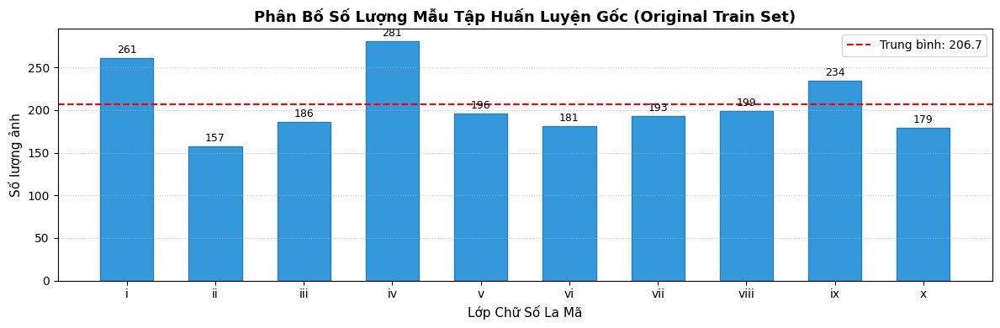

In [29]:
# =============================================================================
# THỐNG KÊ SỐ LƯỢNG MẪU & PHÂN TÍCH PHÂN BỐ CÁC LỚP
# =============================================================================
def scan_dataset(directory: Path):
    """Đếm số lượng ảnh hợp lệ trong từng thư mục con theo lớp."""
    counts = {}
    file_map = defaultdict(list)
    for cls_name in CLASSES:
        cls_dir = directory / cls_name
        if cls_dir.exists():
            files = [str(p) for p in cls_dir.glob("*.png")]
            counts[cls_name] = len(files)
            file_map[cls_name] = files
        else:
            counts[cls_name] = 0
            file_map[cls_name] = []
    return counts, file_map

train_counts, train_files_map = scan_dataset(DATA_TRAIN_DIR)
val_counts, val_files_map = scan_dataset(DATA_VAL_DIR)
test_counts, test_files_map = scan_dataset(LABEL_BOOK_DIR)

total_train = sum(train_counts.values())
total_val = sum(val_counts.values())
total_test = sum(test_counts.values())

print(f"📊 BẢNG TỔNG KẾT SỐ LƯỢNG MẪU:")
print(f"{'Lớp':<6} | {'Train':<8} | {'Val':<8} | {'Test (Label Book)':<18}")
print("-" * 50)
for cls in CLASSES:
    print(f"{cls:<6} | {train_counts[cls]:<8} | {val_counts[cls]:<8} | {test_counts[cls]:<18}")
print("-" * 50)
print(f"{'TỔNG':<6} | {total_train:<8} | {total_val:<8} | {total_test:<18}")
print(f"\nTổng Train + Val hiện tại = {total_train + total_val} ảnh (Giới hạn tối đa: 10,000)")

# Vẽ biểu đồ trực quan hóa phân bố các lớp trong tập Train gốc
plt.figure(figsize=(12, 4))
bars = plt.bar(CLASSES, [train_counts[c] for c in CLASSES], color='#3498db', edgecolor='#2980b9', width=0.6)
plt.axhline(np.mean(list(train_counts.values())), color='red', linestyle='--', label=f'Trung bình: {np.mean(list(train_counts.values())):.1f}')
plt.title("Phân Bố Số Lượng Mẫu Tập Huấn Luyện Gốc (Original Train Set)", fontsize=13, fontweight='bold')
plt.xlabel("Lớp Chữ Số La Mã", fontsize=11)
plt.ylabel("Số lượng ảnh", fontsize=11)
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.legend()

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 3, int(yval), ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

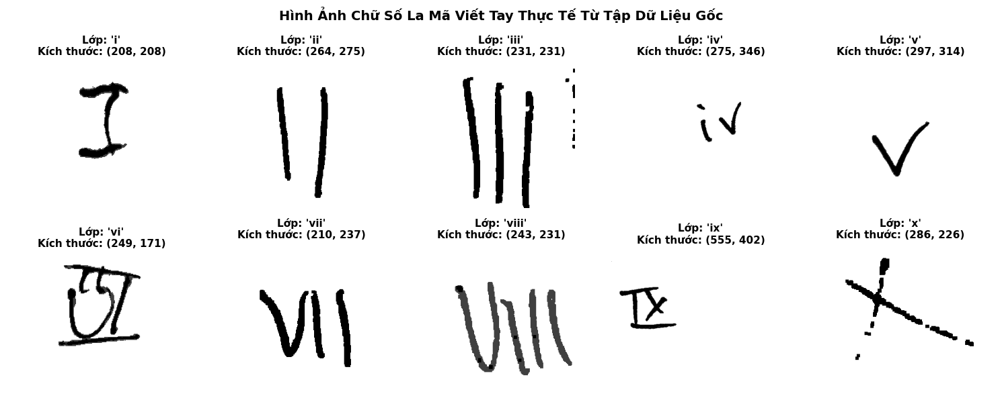

Thông số mẫu ảnh đại diện:
 - Chế độ màu (Mode): L
 - Kích thước gốc (WxH): (208, 208)
 - Giá trị pixel nhỏ nhất: 0 (nét mực đậm)
 - Giá trị pixel lớn nhất: 255 (nền giấy trắng/sáng)
 - Giá trị trung bình: 243.32


In [30]:
# =============================================================================
# TRỰC QUAN HÓA CÁC MẪU ẢNH TIÊU BIỂU TỪ 10 LỚP CHỮ SỐ LA MÃ
# =============================================================================
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle("Hình Ảnh Chữ Số La Mã Viết Tay Thực Tế Từ Tập Dữ Liệu Gốc", fontsize=14, fontweight='bold')

for idx, cls_name in enumerate(CLASSES):
    ax = axes[idx // 5, idx % 5]
    sample_files = train_files_map[cls_name]
    if sample_files:
        sample_path = sample_files[0]
        img = Image.open(sample_path)
        ax.imshow(img, cmap='gray')
        ax.set_title(f"Lớp: '{cls_name}'\nKích thước: {img.size}", fontsize=11, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

# Kiểm tra phân bố kích thước ảnh và dải giá trị pixel
sample_img = Image.open(train_files_map['i'][0])
arr = np.array(sample_img)
print(f"Thông số mẫu ảnh đại diện:")
print(f" - Chế độ màu (Mode): {sample_img.mode}")
print(f" - Kích thước gốc (WxH): {sample_img.size}")
print(f" - Giá trị pixel nhỏ nhất: {arr.min()} (nét mực đậm)")
print(f" - Giá trị pixel lớn nhất: {arr.max()} (nền giấy trắng/sáng)")
print(f" - Giá trị trung bình: {arr.mean():.2f}")

## 🏗️ PHẦN 2: THIẾT KẾ KIẾN TRÚC VGG-16 BẰNG PURE TENSORFLOW (NO KERAS)

### 📐 1. Nguyên Lý & Cấu Trúc Kiến Trúc VGG-16 (Simonyan & Zisserman, 2014)
Kiến trúc VGG-16 là một trong những mạng nơ-ron tích chập kinh điển nhất trong thị giác máy tính. Điểm đột phá của VGG-16 nằm ở việc sử dụng chuỗi các bộ lọc tích chập kích thước nhỏ $3 \times 3$ với bước trượt $\text{stride} = 1$ và đệm $\text{padding} = \text{'SAME'}$. Hai lớp tích chập $3 \times 3$ liên tiếp có vùng thụ cảm (receptive field) tương đương một lớp $5 \times 5$, nhưng số lượng tham số ít hơn và có thêm các hàm kích hoạt phi tuyến xen kẽ giúp tăng khả năng biểu diễn.

Mạng VGG-16 bao gồm **16 lớp có trọng số huấn luyện** chia làm 5 khối tích chập (Convolutional Blocks) và 1 khối phân loại (Classifier):
* **Block 1 (64 filters):** $\text{Conv}(3 \to 64) \to \text{Conv}(64 \to 64) \to \text{MaxPool}(2 \times 2)$
* **Block 2 (128 filters):** $\text{Conv}(64 \to 128) \to \text{Conv}(128 \to 128) \to \text{MaxPool}(2 \times 2)$
* **Block 3 (256 filters):** $\text{Conv}(128 \to 256) \to \text{Conv}(256 \to 256) \to \text{Conv}(256 \to 256) \to \text{MaxPool}(2 \times 2)$
* **Block 4 (512 filters):** $\text{Conv}(256 \to 512) \to \text{Conv}(512 \to 512) \to \text{Conv}(512 \to 512) \to \text{MaxPool}(2 \times 2)$
* **Block 5 (512 filters):** $\text{Conv}(512 \to 512) \to \text{Conv}(512 \to 512) \to \text{Conv}(512 \to 512) \to \text{MaxPool}(2 \times 2)$
* **Classifier (Dense Layers):**
  $$\text{Flatten} \to \text{FC}(512 \to 512) + \text{ReLU} + \text{Dropout} \to \text{FC}(512 \to 512) + \text{ReLU} + \text{Dropout} \to \text{FC}(512 \to 10) \text{ [Logits]}$$

---

### 🧮 2. Các Công Thức Toán Học Cơ Bản (Low-Level Primitives)
1. **Khởi tạo trọng số He Normal (He et al., 2015):**
   Để tránh hiện tượng triệt tiêu hoặc bùng nổ gradient trong mạng sâu có 16 lớp dùng hàm ReLU, trọng số của mỗi lớp tích chập được khởi tạo từ phân phối chuẩn cắt đuôi (Truncated Normal):
   $$\sigma = \sqrt{\frac{2}{k_h \cdot k_w \cdot c_{\text{in}}}}$$
2. **Phép tích chập 2D (Convolution 2D):**
   $$Y(b, y, x, c_{\text{out}}) = \sum_{i=0}^{k_h-1} \sum_{j=0}^{k_w-1} \sum_{c=0}^{c_{\text{in}}-1} X(b, y+i, x+j, c) \cdot W(i, j, c, c_{\text{out}}) + B(c_{\text{out}})$$
   Được thực thi bằng `tf.nn.conv2d(X, W, strides=[1, 1, 1, 1], padding='SAME')` kết hợp `tf.nn.bias_add`.
3. **Phép gộp cực đại (Max Pooling 2D):**
   $$Y(b, y, x, c) = \max_{0 \le i, j < 2} X(b, 2y+i, 2x+j, c)$$
   Được thực thi bằng `tf.nn.max_pool2d(X, ksize=2, strides=2, padding='SAME')`.
4. **Tầng kết nối đầy đủ (Dense Layer):**
   $$Z = X \cdot W + B$$
   Được thực thi bằng `tf.matmul(X, W) + B`.
5. **Cơ chế chống quá khớp Dropout:**
   $$X_{\text{drop}} = \frac{1}{1 - p} \cdot (X \odot M), \quad M \sim \text{Bernoulli}(1 - p)$$
   Được thực thi bằng `tf.nn.dropout(X, rate=p)` khi ở trạng thái huấn luyện (`training=True`).

In [31]:
# =============================================================================
# CÀI ĐẶT KIẾN TRÚC VGG-16 BẰNG PURE TENSORFLOW (NO KERAS)
# =============================================================================
class PureVGG16(tf.Module):
    """
    Mô hình VGG-16 hoàn chỉnh được xây dựng thuần túy bằng các toán tử cốt lõi của TensorFlow.
    Kế thừa tf.Module để quản lý các biến trạng thái (tf.Variable) một cách chuẩn mực.
    Tuyệt đối không kế thừa tf.keras.Model hay sử dụng bất kỳ tf.keras.layers nào.
    """
    def __init__(self, num_classes=10, fc_dim=512, name=None):
        super().__init__(name=name)
        self.num_classes = num_classes
        self.fc_dim = fc_dim
        
        # ---------------------------------------------------------------------
        # HÀM KHỞI TẠO TRỌNG SỐ THEO PHƯƠNG PHÁP HE NORMAL (MSRA)
        # ---------------------------------------------------------------------
        def create_conv_var(k_size, in_channels, out_channels, var_name):
            fan_in = k_size * k_size * in_channels
            stddev = math.sqrt(2.0 / fan_in)
            w = tf.Variable(
                tf.random.truncated_normal([k_size, k_size, in_channels, out_channels], stddev=stddev, seed=RANDOM_SEED),
                name=f"{var_name}_w",
                dtype=tf.float32
            )
            b = tf.Variable(
                tf.zeros([out_channels], dtype=tf.float32),
                name=f"{var_name}_b",
                dtype=tf.float32
            )
            return w, b

        def create_dense_var(in_features, out_features, var_name):
            stddev = math.sqrt(2.0 / in_features)
            w = tf.Variable(
                tf.random.truncated_normal([in_features, out_features], stddev=stddev, seed=RANDOM_SEED),
                name=f"{var_name}_w",
                dtype=tf.float32
            )
            b = tf.Variable(
                tf.zeros([out_features], dtype=tf.float32),
                name=f"{var_name}_b",
                dtype=tf.float32
            )
            return w, b

        # ---------------------------------------------------------------------
        # ĐỊNH NGHĨA 13 LỚP TÍCH CHẬP (CONVOLUTIONAL LAYERS) CỦA VGG-16
        # ---------------------------------------------------------------------
        # Block 1: 2 Conv(64), MaxPool
        self.w1_1, self.b1_1 = create_conv_var(3, 3, 64, 'conv1_1')
        self.w1_2, self.b1_2 = create_conv_var(3, 64, 64, 'conv1_2')
        
        # Block 2: 2 Conv(128), MaxPool
        self.w2_1, self.b2_1 = create_conv_var(3, 64, 128, 'conv2_1')
        self.w2_2, self.b2_2 = create_conv_var(3, 128, 128, 'conv2_2')
        
        # Block 3: 3 Conv(256), MaxPool
        self.w3_1, self.b3_1 = create_conv_var(3, 128, 256, 'conv3_1')
        self.w3_2, self.b3_2 = create_conv_var(3, 256, 256, 'conv3_2')
        self.w3_3, self.b3_3 = create_conv_var(3, 256, 256, 'conv3_3')
        
        # Block 4: 3 Conv(512), MaxPool
        self.w4_1, self.b4_1 = create_conv_var(3, 256, 512, 'conv4_1')
        self.w4_2, self.b4_2 = create_conv_var(3, 512, 512, 'conv4_2')
        self.w4_3, self.b4_3 = create_conv_var(3, 512, 512, 'conv4_3')
        
        # Block 5: 3 Conv(512), MaxPool
        self.w5_1, self.b5_1 = create_conv_var(3, 512, 512, 'conv5_1')
        self.w5_2, self.b5_2 = create_conv_var(3, 512, 512, 'conv5_2')
        self.w5_3, self.b5_3 = create_conv_var(3, 512, 512, 'conv5_3')
        
        # ---------------------------------------------------------------------
        # ĐỊNH NGHĨA 3 LỚP KẾT NỐI ĐẦY ĐỦ (DENSE LAYERS) CỦA VGG-16
        # Với ảnh đầu vào 32x32: Sau 5 lần MaxPool kích thước spatial là 32/(2^5) = 1x1
        # Số chiều feature trước khi vào Dense = 1 * 1 * 512 = 512
        # ---------------------------------------------------------------------
        self.w_fc1, self.b_fc1 = create_dense_var(512, fc_dim, 'fc1')
        self.w_fc2, self.b_fc2 = create_dense_var(fc_dim, fc_dim, 'fc2')
        self.w_fc3, self.b_fc3 = create_dense_var(fc_dim, num_classes, 'fc3')

    def conv2d_relu(self, x, w, b):
        """Toán tử tích chập 2D + Bias Add + ReLU thuần túy."""
        conv = tf.nn.conv2d(x, w, strides=[1, 1, 1, 1], padding='SAME')
        conv_bias = tf.nn.bias_add(conv, b)
        return tf.nn.relu(conv_bias)

    def __call__(self, x, training=False, dropout_rate=0.4):
        """
        Lan truyền xuôi (Forward Pass) qua 16 lớp của mạng VGG-16.
        x: Tensor đầu vào có kích thước [Batch_size, 32, 32, 3]
        """
        # Block 1
        x = self.conv2d_relu(x, self.w1_1, self.b1_1)
        x = self.conv2d_relu(x, self.w1_2, self.b1_2)
        x = tf.nn.max_pool2d(x, ksize=2, strides=2, padding='SAME')  # 32x32 -> 16x16

        # Block 2
        x = self.conv2d_relu(x, self.w2_1, self.b2_1)
        x = self.conv2d_relu(x, self.w2_2, self.b2_2)
        x = tf.nn.max_pool2d(x, ksize=2, strides=2, padding='SAME')  # 16x16 -> 8x8

        # Block 3
        x = self.conv2d_relu(x, self.w3_1, self.b3_1)
        x = self.conv2d_relu(x, self.w3_2, self.b3_2)
        x = self.conv2d_relu(x, self.w3_3, self.b3_3)
        x = tf.nn.max_pool2d(x, ksize=2, strides=2, padding='SAME')  # 8x8 -> 4x4

        # Block 4
        x = self.conv2d_relu(x, self.w4_1, self.b4_1)
        x = self.conv2d_relu(x, self.w4_2, self.b4_2)
        x = self.conv2d_relu(x, self.w4_3, self.b4_3)
        x = tf.nn.max_pool2d(x, ksize=2, strides=2, padding='SAME')  # 4x4 -> 2x2

        # Block 5
        x = self.conv2d_relu(x, self.w5_1, self.b5_1)
        x = self.conv2d_relu(x, self.w5_2, self.b5_2)
        x = self.conv2d_relu(x, self.w5_3, self.b5_3)
        x = tf.nn.max_pool2d(x, ksize=2, strides=2, padding='SAME')  # 2x2 -> 1x1

        # Làm phẳng đặc trưng (Flattening)
        batch_size = tf.shape(x)[0]
        x = tf.reshape(x, [batch_size, -1])  # [Batch_size, 512]

        # Khối phân loại (Classifier)
        # FC 1
        x = tf.nn.relu(tf.matmul(x, self.w_fc1) + self.b_fc1)
        if training:
            x = tf.nn.dropout(x, rate=dropout_rate, seed=RANDOM_SEED)

        # FC 2
        x = tf.nn.relu(tf.matmul(x, self.w_fc2) + self.b_fc2)
        if training:
            x = tf.nn.dropout(x, rate=dropout_rate, seed=RANDOM_SEED)

        # FC 3: Đầu ra logits cho 10 lớp
        logits = tf.matmul(x, self.w_fc3) + self.b_fc3
        return logits

# Kiểm tra khởi tạo mô hình và kích thước đầu ra
test_vgg = PureVGG16(num_classes=NUM_CLASSES, fc_dim=512)
dummy_batch = tf.zeros([2, 32, 32, 3], dtype=tf.float32)
test_output = test_vgg(dummy_batch, training=False)

total_params = sum(tf.size(v).numpy() for v in test_vgg.trainable_variables)
print(f"✅ Khởi tạo PureVGG16 thành công!")
print(f" - Đầu ra kiểm thử logits shape: {test_output.shape}")
print(f" - Tổng số tham số có thể huấn luyện: {total_params:,} tham số")
print(f" - Số lượng biến (Weights & Biases): {len(test_vgg.trainable_variables)} biến (Đúng chuẩn 16 cặp w & b = 32 biến)")

✅ Khởi tạo PureVGG16 thành công!
 - Đầu ra kiểm thử logits shape: (2, 10)
 - Tổng số tham số có thể huấn luyện: 15,245,130 tham số
 - Số lượng biến (Weights & Biases): 32 biến (Đúng chuẩn 16 cặp w & b = 32 biến)


## ⚙️ Bộ Tối Ưu Hóa & Vòng Lặp Huấn Luyện Thuần Túy (Custom Training Pipeline)

Để đảm bảo quy định **"không dùng thư viện Keras"**, chúng ta tự tay cài đặt thuật toán tối ưu hóa **Adam (Adaptive Moment Estimation)** từ các phương trình toán học gốc và xây dựng vòng lặp huấn luyện độc lập với `tf.GradientTape()`.

### 1. Thuật Toán Tối Ưu Hóa Adam (Kingma & Ba, 2014)
Với mỗi bước thời gian $t$, đạo hàm gradient $g_t = \nabla_{\theta} \mathcal{L}(\theta_t)$:
1. **Cập nhật moment bậc nhất (Moving Average of Gradients):**
   $$m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t$$
2. **Cập nhật moment bậc hai (Moving Average of Squared Gradients):**
   $$v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2$$
3. **Hiệu chỉnh độ lệch khởi tạo (Bias Correction):**
   $$\hat{m}_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat{v}_t = \frac{v_t}{1 - \beta_2^t}$$
4. **Cập nhật trọng số tham số:**
   $$\theta_t = \theta_{t-1} - \frac{\alpha \hat{m}_t}{\sqrt{\hat{v}_t} + \epsilon}$$
Trong đó: $\alpha = 10^{-4}$ (tốc độ học), $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\epsilon = 10^{-8}$.

### 2. Hàm Mất Mát (Loss Function)
Sử dụng hàm Cross-Entropy đối với Logits bằng toán tử low-level:
$$\mathcal{L}(y, z) = -\sum_{c=1}^C y_c \log \left( \frac{e^{z_c}}{\sum_{j=1}^C e^{z_j}} \right)$$
Được thực thi bằng `tf.nn.sparse_softmax_cross_entropy_with_logits(labels=y, logits=z)`.

In [32]:
# =============================================================================
# CÀI ĐẶT THUẬT TOÁN ADAM OPTIMIZER VÀ QUẢN LÝ HUẤN LUYỆN BẰNG PURE TENSORFLOW
# =============================================================================
class PureAdamOptimizer:
    """
    Thuật toán tối ưu hóa Adam độc lập, quản lý moment m và v bằng tf.Variable,
    hoàn toàn không kế thừa hoặc gọi tf.keras.optimizers.
    """
    def __init__(self, variables, lr=1e-4, beta1=0.9, beta2=0.999, epsilon=1e-8):
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.epsilon = epsilon
        
        # Biến đếm bước thời gian t (dùng float32 để tính lũy thừa ổn định)
        self.step_t = tf.Variable(0.0, dtype=tf.float32, trainable=False, name="adam_t")
        
        # Danh sách biến lưu trữ moment bậc 1 (m) và moment bậc 2 (v)
        self.m = [tf.Variable(tf.zeros_like(v), trainable=False, name=f"m_{v.name.split(':')[0]}") for v in variables]
        self.v = [tf.Variable(tf.zeros_like(v), trainable=False, name=f"v_{v.name.split(':')[0]}") for v in variables]

    def apply_gradients(self, grads_and_vars):
        """Cập nhật trọng số theo công thức Adam đã qua bias correction."""
        self.step_t.assign_add(1.0)
        t = self.step_t
        
        # Hiệu chỉnh moment m/v trước khi cộng epsilon.
        correction1 = 1.0 - tf.pow(self.beta1, t)
        correction2 = 1.0 - tf.pow(self.beta2, t)
        
        for (g, var), m, v in zip(grads_and_vars, self.m, self.v):
            if g is not None:
                # Cập nhật moment bậc 1
                m.assign(self.beta1 * m + (1.0 - self.beta1) * g)
                # Cập nhật moment bậc 2
                v.assign(self.beta2 * v + (1.0 - self.beta2) * tf.square(g))
                # Tính lượng thay đổi trọng số
                step_delta = self.lr * (m / correction1) / (tf.sqrt(v / correction2) + self.epsilon)
                # Cập nhật trọng số: var = var - step_delta
                var.assign_sub(step_delta)


class PureModelWeightsSaver:
    """Lưu và khôi phục trọng số mô hình dạng numpy/npz mà không cần Keras checkpoint."""
    @staticmethod
    def save_weights(model, file_path):
        weights_dict = {v.name: v.numpy() for v in model.trainable_variables}
        np.savez(file_path, **weights_dict)

    @staticmethod
    def load_weights(model, file_path):
        with np.load(file_path) as data:
            expected = {v.name for v in model.trainable_variables}
            if set(data.files) != expected:
                raise ValueError("Checkpoint không khớp đầy đủ biến của mô hình")
            for v in model.trainable_variables:
                if tuple(data[v.name].shape) != tuple(v.shape):
                    raise ValueError(f"Sai shape checkpoint: {v.name}")
                v.assign(data[v.name])


# -----------------------------------------------------------------------------
# CÁC HÀM BƯỚC HUẤN LUYỆN (TRAIN STEP) VÀ ĐÁNH GIÁ (EVAL STEP)
# -----------------------------------------------------------------------------
def compute_loss(labels, logits):
    """Hàm mất mát phân loại Cross Entropy đa lớp trên Logits."""
    loss_vector = tf.nn.sparse_softmax_cross_entropy_with_logits(labels=labels, logits=logits)
    return tf.reduce_mean(loss_vector)

def compute_accuracy(labels, logits):
    """Tính độ chính xác Accuracy dạng phần trăm [0.0 -> 1.0]."""
    preds = tf.argmax(logits, axis=1, output_type=tf.int32)
    correct = tf.equal(preds, labels)
    return tf.reduce_mean(tf.cast(correct, tf.float32))

def pure_train_step(model, optimizer, x_batch, y_batch, dropout_rate=0.4):
    """Thực thi một bước tối ưu hóa sử dụng tf.GradientTape được biên dịch đồ thị tĩnh @tf.function."""
    with tf.GradientTape() as tape:
        logits = model(x_batch, training=True, dropout_rate=dropout_rate)
        loss = compute_loss(y_batch, logits)
    
    # Tính toán gradients đối với tất cả tham số có thể huấn luyện
    gradients = tape.gradient(loss, model.trainable_variables)
    # Áp dụng cập nhật trọng số
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    
    acc = compute_accuracy(y_batch, logits)
    return loss, acc

def pure_evaluate(model, dataset):
    """Đánh giá toàn diện trên tập dữ liệu và trả về Loss trung bình cùng Accuracy."""
    total_loss = 0.0
    total_correct = 0.0
    total_samples = 0
    
    for x_b, y_b in dataset:
        batch_size = tf.shape(x_b)[0]
        logits = model(x_b, training=False)
        loss = compute_loss(y_b, logits)
        
        preds = tf.argmax(logits, axis=1, output_type=tf.int32)
        correct_count = tf.reduce_sum(tf.cast(tf.equal(preds, y_b), tf.float32))
        
        total_loss += loss.numpy() * float(batch_size)
        total_correct += correct_count.numpy()
        total_samples += int(batch_size)
        
    avg_loss = total_loss / max(1, total_samples)
    accuracy = total_correct / max(1, total_samples)
    return avg_loss, accuracy

In [33]:
# =============================================================================
# PIPELINE NẠP VÀ TIỀN XỬ LÝ DỮ LIỆU BẰNG PURE TF.DATA.DATASET
# =============================================================================
def parse_image_and_label(file_path: tf.Tensor, label_idx: tf.Tensor):
    """
    Đọc file ảnh PNG, chuyển đổi thành 3 kênh màu (RGB), resize về (32, 32)
    và chuẩn hóa giá trị điểm ảnh về đoạn [0.0, 1.0].
    Sử dụng hoàn toàn toán tử tf.io và tf.image.
    """
    # Đọc file nhị phân
    img_raw = tf.io.read_file(file_path)
    # Giải mã ảnh PNG (chỉ định 3 kênh màu)
    img = tf.io.decode_png(img_raw, channels=3)
    # Chuyển đổi kiểu dữ liệu sang float32
    img = tf.cast(img, tf.float32)
    # Resize về kích thước chuẩn 32x32
    img = tf.image.resize(img, [32, 32], method=tf.image.ResizeMethod.BILINEAR)
    # Chuẩn hóa về [0.0, 1.0]
    img = img / 255.0
    return img, label_idx

def create_pure_tf_dataset(file_paths, labels, batch_size=8, shuffle=True):
    """Tạo pipeline tf.data tối ưu với prefetch và shuffle."""
    ds = tf.data.Dataset.from_tensor_slices((file_paths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(file_paths), seed=RANDOM_SEED, reshuffle_each_iteration=True)
    ds = ds.map(parse_image_and_label, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

def collect_paths_and_labels(data_dir: Path):
    """Quét danh sách đường dẫn file và nhãn tương ứng từ thư mục."""
    paths = []
    labels = []
    for cls_name in CLASSES:
        cls_dir = data_dir / cls_name
        if cls_dir.exists():
            cls_idx = CLASS_TO_IDX[cls_name]
            files = sorted(list(cls_dir.glob("*.png")))
            for f in files:
                paths.append(str(f))
                labels.append(cls_idx)
    return paths, labels

# Chuẩn bị dữ liệu ban đầu
train_paths_raw, train_labels_raw = collect_paths_and_labels(DATA_TRAIN_DIR)
val_paths_raw, val_labels_raw = collect_paths_and_labels(DATA_VAL_DIR)
test_paths_raw, test_labels_raw = collect_paths_and_labels(LABEL_BOOK_DIR)

print(f"Tổng hợp dữ liệu gốc:")
print(f" - Train samples: {len(train_paths_raw)}")
print(f" - Val samples:   {len(val_paths_raw)}")
print(f" - Test samples (label_book): {len(test_paths_raw)}")

# Audit chỉ dùng pixel/nhãn, không dùng dự đoán hay label_book để chọn dữ liệu.
import hashlib

def pixel_hash(path):
    with Image.open(path) as image:
        image = image.convert('RGB')
        return hashlib.sha256(str(image.size).encode() + image.tobytes()).hexdigest()

def audit_split(paths, labels):
    seen, out_paths, out_labels = {}, [], []
    for path, label in zip(paths, labels):
        key = pixel_hash(path)  # Lỗi ảnh hỏng phải được xử lý, không bỏ qua âm thầm.
        if key in seen:
            if seen[key] != label:
                raise ValueError(f"Ảnh trùng nhưng khác nhãn: {path}")
            continue
        seen[key] = label
        out_paths.append(path)
        out_labels.append(label)
    return out_paths, out_labels, seen

train_paths_raw, train_labels_raw, train_hashes = audit_split(train_paths_raw, train_labels_raw)
_, _, val_hashes = audit_split(val_paths_raw, val_labels_raw)
for path, label in zip(train_paths_raw, train_labels_raw):
    key = pixel_hash(path)
    if key in val_hashes and val_hashes[key] != label:
        raise ValueError(f"Train/val có ảnh trùng khác nhãn: {path}")
keep = [pixel_hash(p) not in val_hashes for p in train_paths_raw]
print(f"Train trùng validation bị loại: {len(keep) - sum(keep)}")
train_paths_raw = [p for p, ok in zip(train_paths_raw, keep) if ok]
train_labels_raw = [y for y, ok in zip(train_labels_raw, keep) if ok]
assert set(train_labels_raw) == set(range(NUM_CLASSES))

# Tạo tf.data.Dataset cho Baseline
BATCH_SIZE = 8
ds_train_baseline = create_pure_tf_dataset(train_paths_raw, train_labels_raw, batch_size=BATCH_SIZE, shuffle=True)
ds_val_baseline = create_pure_tf_dataset(val_paths_raw, val_labels_raw, batch_size=BATCH_SIZE, shuffle=False)
ds_test_baseline = create_pure_tf_dataset(test_paths_raw, test_labels_raw, batch_size=BATCH_SIZE, shuffle=False)

Tổng hợp dữ liệu gốc:
 - Train samples: 2067
 - Val samples:   813
 - Test samples (label_book): 52
Train trùng validation bị loại: 49


## PHẦN 3 — Baseline: kết quả trong output hiện tại

Ảnh train giữ nguyên, không augment hoặc tự sửa nhãn; đã kiểm tra trùng pixel
và loại train trùng validation trước khi học. Validation giữ nguyên.
Best validation **64,21%**, macro-F1 **0,6127**, label_book **65,38%**.
Label_book là tập tham khảo công khai nhỏ, không phải hidden test chính thức.


In [34]:
# =============================================================================
# TIẾN HÀNH HUẤN LUYỆN MÔ HÌNH BASELINE VGG-16 TRÊN DỮ LIỆU GỐC
# =============================================================================
BASELINE_EPOCHS = 15  # Ngân sách mặc định; chưa bảo đảm hội tụ
LEARNING_RATE = 1e-4

# Khởi tạo mô hình Baseline và Bộ tối ưu hóa Adam thuần túy
tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
vgg_baseline = PureVGG16(num_classes=NUM_CLASSES, fc_dim=512)
opt_baseline = PureAdamOptimizer(vgg_baseline.trainable_variables, lr=LEARNING_RATE)

# Mỗi model/optimizer có graph riêng, tránh tạo lại Adam slots trong tf.function.
@tf.function(reduce_retracing=True)
def train_step_12(x, y):
    return pure_train_step(vgg_baseline, opt_baseline, x, y, dropout_rate=0.4)

best_val_acc_baseline = -1.0
best_model_path_baseline = COMP_DIR / "baseline_audited_v2.npz"

history_baseline = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}

print(f"BẮT ĐẦU HUẤN LUYỆN BASELINE VGG-16 TRÊN DỮ LIỆU GỐC ({BASELINE_EPOCHS} Epochs)...")
print("-" * 75)

for epoch in range(1, BASELINE_EPOCHS + 1):
    epoch_losses = []
    epoch_accs = []
    
    # Vòng lặp huấn luyện từng batch
    for x_b, y_b in ds_train_baseline:
        loss, acc = train_step_12(x_b, y_b)
        epoch_losses.append((float(loss.numpy()), int(tf.shape(y_b)[0])))
        epoch_accs.append((float(acc.numpy()), int(tf.shape(y_b)[0])))
        
    train_loss = np.average([v for v, n in epoch_losses], weights=[n for v, n in epoch_losses])
    train_acc = np.average([v for v, n in epoch_accs], weights=[n for v, n in epoch_accs])
    
    # Đánh giá trên tập Validation
    val_loss, val_acc = pure_evaluate(vgg_baseline, ds_val_baseline)
    
    history_baseline['train_loss'].append(train_loss)
    history_baseline['train_acc'].append(train_acc)
    history_baseline['val_loss'].append(val_loss)
    history_baseline['val_acc'].append(val_acc)
    
    # Lưu lại trọng số tốt nhất
    is_best = ""
    if val_acc > best_val_acc_baseline:
        best_val_acc_baseline = val_acc
        PureModelWeightsSaver.save_weights(vgg_baseline, str(best_model_path_baseline))
        is_best = " ⭐ [BEST VAL ACC]"
        
    print(f"Epoch {epoch:02d}/{BASELINE_EPOCHS:02d} | Train Loss: {train_loss:.4f} - Train Acc: {train_acc*100:.2f}% | Val Loss: {val_loss:.4f} - Val Acc: {val_acc*100:.2f}%{is_best}")

# Tải lại mô hình tốt nhất để đánh giá trên tập kiểm thử chuẩn label_book
PureModelWeightsSaver.load_weights(vgg_baseline, str(best_model_path_baseline))
test_loss_baseline, test_acc_baseline = pure_evaluate(vgg_baseline, ds_test_baseline)

print("-" * 75)
print(f"🎯 KẾT QUẢ BASELINE TRÊN DỮ LIỆU GỐC:")
print(f" - Best Validation Accuracy: {best_val_acc_baseline * 100:.2f}%")
print(f" - Label Book Test Accuracy: {test_acc_baseline * 100:.2f}% (Test Loss: {test_loss_baseline:.4f})")

BẮT ĐẦU HUẤN LUYỆN BASELINE VGG-16 TRÊN DỮ LIỆU GỐC (15 Epochs)...
---------------------------------------------------------------------------
Epoch 01/15 | Train Loss: 2.3033 - Train Acc: 11.94% | Val Loss: 2.3044 - Val Acc: 10.33% ⭐ [BEST VAL ACC]
Epoch 02/15 | Train Loss: 2.2931 - Train Acc: 13.48% | Val Loss: 2.3093 - Val Acc: 10.33%
Epoch 03/15 | Train Loss: 2.2908 - Train Acc: 12.93% | Val Loss: 2.3047 - Val Acc: 10.33%
Epoch 04/15 | Train Loss: 2.2903 - Train Acc: 13.73% | Val Loss: 2.2903 - Val Acc: 10.33%
Epoch 05/15 | Train Loss: 2.1882 - Train Acc: 17.69% | Val Loss: 2.2588 - Val Acc: 13.28% ⭐ [BEST VAL ACC]
Epoch 06/15 | Train Loss: 1.9465 - Train Acc: 26.31% | Val Loss: 1.7177 - Val Acc: 29.89% ⭐ [BEST VAL ACC]
Epoch 07/15 | Train Loss: 1.7087 - Train Acc: 35.08% | Val Loss: 1.7259 - Val Acc: 28.91%
Epoch 08/15 | Train Loss: 1.5121 - Train Acc: 41.58% | Val Loss: 1.4230 - Val Acc: 42.19% ⭐ [BEST VAL ACC]
Epoch 09/15 | Train Loss: 1.3661 - Train Acc: 46.78% | Val Loss: 1.30

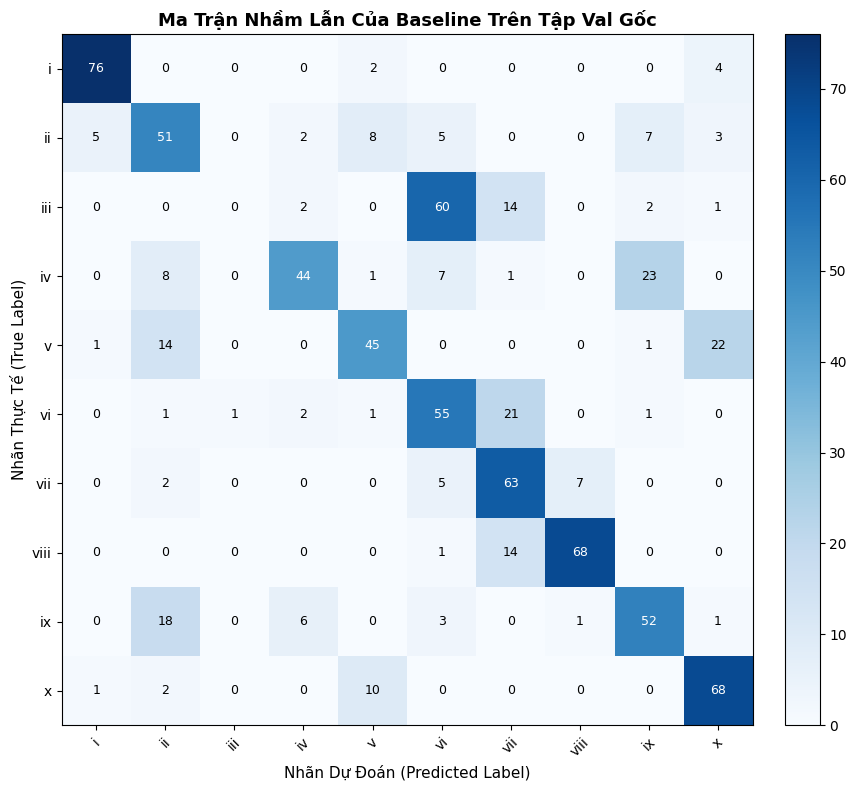


Top 5 cặp lớp bị mô hình nhầm lẫn nhiều nhất:
 - Nhãn thực 'iii' bị đoán nhầm thành 'vi': 60 lần
 - Nhãn thực 'iv' bị đoán nhầm thành 'ix': 23 lần
 - Nhãn thực 'v' bị đoán nhầm thành 'x': 22 lần
 - Nhãn thực 'vi' bị đoán nhầm thành 'vii': 21 lần
 - Nhãn thực 'ix' bị đoán nhầm thành 'ii': 18 lần


In [ ]:
# =============================================================================
# PHÂN TÍCH LỖI (ERROR ANALYSIS) & TRỰC QUAN HÓA MA TRẬN NHẦM LẪN (CONFUSION MATRIX)
# =============================================================================
def get_predictions_and_labels(model, dataset):
    all_preds = []
    all_labels = []
    for x_b, y_b in dataset:
        logits = model(x_b, training=False)
        preds = tf.argmax(logits, axis=1, output_type=tf.int32).numpy()
        all_preds.extend(preds)
        all_labels.extend(y_b.numpy())
    return np.array(all_preds), np.array(all_labels)

val_preds_bl, val_labels_bl = get_predictions_and_labels(vgg_baseline, ds_val_baseline)

# Tự tính Ma Trận Nhầm Lẫn (Confusion Matrix) không phụ thuộc scikit-learn
cm_baseline = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int32)
for true_lbl, pred_lbl in zip(val_labels_bl, val_preds_bl):
    cm_baseline[true_lbl, pred_lbl] += 1

# Vẽ biểu đồ nhiệt (Heatmap) ma trận nhầm lẫn
plt.figure(figsize=(9, 8))
plt.imshow(cm_baseline, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Ma Trận Nhầm Lẫn Của Baseline Trên Tập Val Gốc", fontsize=13, fontweight='bold')
plt.colorbar(fraction=0.046, pad=0.04)
tick_marks = np.arange(NUM_CLASSES)
plt.xticks(tick_marks, CLASSES, rotation=45, fontsize=10)
plt.yticks(tick_marks, CLASSES, fontsize=10)

thresh = cm_baseline.max() / 2.0
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, format(cm_baseline[i, j], 'd'),
                 ha="center", va="center",
                 color="white" if cm_baseline[i, j] > thresh else "black", fontsize=9)

plt.ylabel('Nhãn Thực Tế (True Label)', fontsize=11)
plt.xlabel('Nhãn Dự Đoán (Predicted Label)', fontsize=11)
plt.tight_layout()
plt.show()

# Tính toán các cặp lớp bị nhầm lẫn nhiều nhất
misclassified_pairs = []
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j and cm_baseline[i, j] > 0:
            misclassified_pairs.append((CLASSES[i], CLASSES[j], cm_baseline[i, j]))

misclassified_pairs.sort(key=lambda x: x[2], reverse=True)
print("\nTop 5 cặp lớp bị mô hình nhầm lẫn nhiều nhất:")
for true_c, pred_c, count in misclassified_pairs[:5]:
    print(f" - Nhãn thực '{true_c}' bị đoán nhầm thành '{pred_c}': {count} lần")

## Cải thiện dữ liệu train

Không gộp validation vào train. Không áp ngưỡng 86 cố định hoặc erosion lên
nét chữ đã resize 32×32. Giữ grayscale và ảnh raw để hạn chế lệch phân phối
với validation/test nguyên bản. Đây là giả thuyết cần kiểm chứng bằng kết quả
chạy lại, chưa phải cam kết tăng accuracy.

In [ ]:
# Chuẩn hóa mềm, không xóa nền bằng ngưỡng cứng.
def clean_and_binarize_image(img_pil):
    # Tên hàm giữ tương thích; thực tế giữ grayscale thay vì binarize.
    return ImageOps.autocontrast(img_pil.convert('L'), cutoff=0)

def crop_and_center_digit(img_pil, output_size=(32, 32), padding_ratio=0.18):
    gray = img_pil.convert('L')
    arr = np.asarray(gray)
    # Chỉ dùng mask để tìm bbox; giữ nguyên cường độ pixel của nét.
    threshold = min(210, float(np.percentile(arr, 95)) - 25)
    coords = np.argwhere(arr < threshold)
    if not len(coords):
        return gray.resize(output_size, Image.Resampling.LANCZOS)
    y0, x0 = coords.min(axis=0)
    y1, x1 = coords.max(axis=0) + 1
    cropped = gray.crop((int(x0), int(y0), int(x1), int(y1)))
    side = max(cropped.size)
    pad = max(2, int(side * padding_ratio))
    canvas = Image.new('L', (side + 2 * pad, side + 2 * pad), 255)
    canvas.paste(cropped, ((canvas.width - cropped.width)//2, (canvas.height - cropped.height)//2))
    return canvas.resize(output_size, Image.Resampling.LANCZOS)

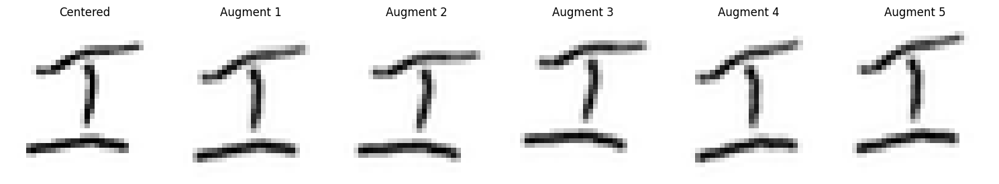

In [ ]:
# Augment ở độ phân giải cao hơn, không lật ảnh hoặc phá nét bằng erosion.
def augment_handwriting(img_pil, rng=None):
    rng = rng if rng is not None else np.random.default_rng(RANDOM_SEED)
    image = img_pil.convert('L').resize((64, 64), Image.Resampling.BICUBIC)
    image = image.rotate(float(rng.uniform(-7, 7)),
                         resample=Image.Resampling.BICUBIC, fillcolor=255)
    dx, dy = map(int, rng.integers(-2, 3, size=2))
    image = image.transform(image.size, Image.Transform.AFFINE,
                            (1, 0, dx, 0, 1, dy),
                            resample=Image.Resampling.BICUBIC, fillcolor=255)
    result = image.resize((32, 32), Image.Resampling.LANCZOS)
    # Fallback nếu biến đổi làm mất quá nhiều nét.
    before = np.asarray(img_pil.resize((32, 32))).astype(float)
    after = np.asarray(result).astype(float)
    if (255 - after).sum() < 0.7 * (255 - before).sum():
        return img_pil.resize((32, 32)).convert('L')
    return result

rng_preview = np.random.default_rng(RANDOM_SEED)
base_sample = crop_and_center_digit(clean_and_binarize_image(Image.open(train_paths_raw[0])))
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for i, ax in enumerate(axes):
    ax.imshow(base_sample if i == 0 else augment_handwriting(base_sample, rng_preview), cmap='gray', vmin=0, vmax=255)
    ax.set_title('Centered' if i == 0 else f'Augment {i}')
    ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# Tạo artifact mới; không ghi đè improved_data/submission.zip cũ.
import tempfile
from collections import defaultdict

IMPROVED_DIR = Path(tempfile.mkdtemp(prefix='improved_v2_', dir=COMP_DIR))
IMPROVED_TRAIN_DIR = IMPROVED_DIR / 'train'
IMPROVED_VAL_DIR = IMPROVED_DIR / 'val'
TARGET_TRAIN_PER_CLASS = 800
rng_data = np.random.default_rng(RANDOM_SEED)
manifest = []
generated_hashes = set()

for cls_name in CLASSES:
    (IMPROVED_TRAIN_DIR / cls_name).mkdir(parents=True)
    (IMPROVED_VAL_DIR / cls_name).mkdir(parents=True)

def record_image(image, destination, source, transform, split):
    key = hashlib.sha256(str(image.convert('RGB').size).encode() + image.convert('RGB').tobytes()).hexdigest()
    if split == 'train' and (key in val_hashes or key in generated_hashes):
        return False
    image.save(destination)
    if split == 'train':
        generated_hashes.add(key)
    manifest.append(dict(file=destination.relative_to(IMPROVED_DIR).as_posix(),
                         source=str(Path(source).relative_to(COMP_DIR)),
                         transform=transform, split=split, pixel_hash=key))
    return True

# Validation byte-for-byte giống baseline, không cân bằng hay augment.
for source, label in zip(val_paths_raw, val_labels_raw):
    destination = IMPROVED_VAL_DIR / CLASSES[label] / Path(source).name
    shutil.copy2(source, destination)
    manifest.append(dict(file=destination.relative_to(IMPROVED_DIR).as_posix(),
                         source=str(Path(source).relative_to(COMP_DIR)),
                         transform='raw', split='val', pixel_hash=pixel_hash(source)))

for label, cls_name in enumerate(CLASSES):
    sources = [p for p, y in zip(train_paths_raw, train_labels_raw) if y == label]
    pool = []
    count = 0
    # Giữ mọi raw hợp lệ trước, thêm centered sau.
    for source in sources:
        with Image.open(source) as im:
            raw = im.convert('RGB')
            centered = crop_and_center_digit(clean_and_binarize_image(im))
        if record_image(raw, IMPROVED_TRAIN_DIR / cls_name / f'{count:05d}_raw.png', source, 'raw', 'train'):
            count += 1
        pool.append((source, centered))
    for source, centered in pool:
        if record_image(centered, IMPROVED_TRAIN_DIR / cls_name / f'{count:05d}_center.png', source, 'center', 'train'):
            count += 1
    if count > TARGET_TRAIN_PER_CLASS:
        raise ValueError('Tăng budget hoặc giảm biến thể; không tự bỏ ảnh gốc')
    attempts = 0
    while count < TARGET_TRAIN_PER_CLASS and attempts < TARGET_TRAIN_PER_CLASS * 30:
        source, centered = pool[int(rng_data.integers(len(pool)))]
        aug = augment_handwriting(centered, rng_data)
        if record_image(aug, IMPROVED_TRAIN_DIR / cls_name / f'{count:05d}_aug.png', source, 'center+rotate+shift', 'train'):
            count += 1
        attempts += 1
    if count != TARGET_TRAIN_PER_CLASS:
        raise ValueError(f'Không đủ biến thể duy nhất cho {cls_name}')
    print(f'{cls_name}: {count} train')

train_rows = [r for r in manifest if r['split'] == 'train']
val_rows = [r for r in manifest if r['split'] == 'val']
assert not ({r['source'] for r in train_rows} & {r['source'] for r in val_rows})
assert not ({r['pixel_hash'] for r in train_rows} & {r['pixel_hash'] for r in val_rows})
actual_total = len(train_rows) + len(val_rows)
evaluator_total = (math.ceil(len(train_rows)/8) + math.ceil(len(val_rows)/8)) * 8
assert actual_total < 10000 and evaluator_total <= 10000
assert len(list(IMPROVED_DIR.rglob('*.png'))) == actual_total
(COMP_DIR / f'{IMPROVED_DIR.name}_manifest.json').write_text(
    json.dumps({'seed': RANDOM_SEED, 'actual_total': actual_total,
                'evaluator_total': evaluator_total, 'images': manifest}, ensure_ascii=False, indent=2), encoding='utf-8')
archive = IMPROVED_DIR.with_suffix('.zip')
with zipfile.ZipFile(archive, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for file in sorted(IMPROVED_DIR.rglob('*.png')):
        zf.write(file, file.relative_to(IMPROVED_DIR).as_posix())
print(f'Dataset: {IMPROVED_DIR}')
print(f'ZIP: {archive}; images={actual_total}, evaluator_count={evaluator_total}')

i: 800 train
ii: 800 train
iii: 800 train
iv: 800 train
v: 800 train
vi: 800 train
vii: 800 train
viii: 800 train
ix: 800 train
x: 800 train
Dataset: /content/deeplearningai-data-centric-competition/improved_v2_vo21_ged
ZIP: /content/deeplearningai-data-centric-competition/improved_v2_vo21_ged.zip; images=8813, evaluator_count=8816


## PHẦN 5 — V2: kết quả trong output hiện tại

Giữ PureVGG16, Adam, LR 1e-4, batch 8, dropout 0,4 và 15 epoch. V2 giữ raw,
thêm centered và augmentation nhẹ, 800 ảnh/lớp. Không có bước tự sửa nhãn.
Train lớn hơn có nhiều bước cập nhật hơn dù số epoch bằng baseline.

Best validation **84,01%**, macro-F1 **0,8402**,
label_book **73,08%**; chênh lệch label_book so với baseline
**+7.69 điểm phần trăm** theo output (tính trước khi làm tròn).


In [ ]:
# =============================================================================
# HUẤN LUYỆN MÔ HÌNH VGG-16 TRÊN TẬP DỮ LIỆU ĐÃ CẢI TIẾN
# =============================================================================
# Chuẩn bị pipeline tf.data cho tập dữ liệu cải tiến
train_paths_imp, train_labels_imp = collect_paths_and_labels(IMPROVED_TRAIN_DIR)
val_paths_imp, val_labels_imp = collect_paths_and_labels(IMPROVED_VAL_DIR)

ds_train_improved = create_pure_tf_dataset(train_paths_imp, train_labels_imp, batch_size=BATCH_SIZE, shuffle=True)
ds_val_improved = create_pure_tf_dataset(val_paths_imp, val_labels_imp, batch_size=BATCH_SIZE, shuffle=False)

# Khởi tạo mô hình VGG-16 mới với cùng cấu trúc
tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
vgg_datacentric = PureVGG16(num_classes=NUM_CLASSES, fc_dim=512)
opt_datacentric = PureAdamOptimizer(vgg_datacentric.trainable_variables, lr=LEARNING_RATE)

# Mỗi model/optimizer có graph riêng, tránh tạo lại Adam slots trong tf.function.
@tf.function(reduce_retracing=True)
def train_step_19(x, y):
    return pure_train_step(vgg_datacentric, opt_datacentric, x, y, dropout_rate=0.4)

best_val_acc_dc = -1.0
best_model_path_dc = COMP_DIR / "datacentric_audited_v2.npz"

history_dc = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}

DATA_CENTRIC_EPOCHS = BASELINE_EPOCHS  # Cùng epoch; số bước cập nhật khác nhau do train lớn hơn

print(f"BẮT ĐẦU HUẤN LUYỆN VGG-16 TRÊN DỮ LIỆU DATA-CENTRIC ({DATA_CENTRIC_EPOCHS} Epochs)...")
print("-" * 75)

for epoch in range(1, DATA_CENTRIC_EPOCHS + 1):
    epoch_losses = []
    epoch_accs = []
    
    for x_b, y_b in ds_train_improved:
        loss, acc = train_step_19(x_b, y_b)
        epoch_losses.append((float(loss.numpy()), int(tf.shape(y_b)[0])))
        epoch_accs.append((float(acc.numpy()), int(tf.shape(y_b)[0])))
        
    train_loss = np.average([v for v, n in epoch_losses], weights=[n for v, n in epoch_losses])
    train_acc = np.average([v for v, n in epoch_accs], weights=[n for v, n in epoch_accs])
    
    val_loss, val_acc = pure_evaluate(vgg_datacentric, ds_val_improved)
    
    history_dc['train_loss'].append(train_loss)
    history_dc['train_acc'].append(train_acc)
    history_dc['val_loss'].append(val_loss)
    history_dc['val_acc'].append(val_acc)
    
    is_best = ""
    if val_acc > best_val_acc_dc:
        best_val_acc_dc = val_acc
        PureModelWeightsSaver.save_weights(vgg_datacentric, str(best_model_path_dc))
        is_best = " ⭐ [BEST VAL ACC]"
        
    print(f"Epoch {epoch:02d}/{DATA_CENTRIC_EPOCHS:02d} | Train Loss: {train_loss:.4f} - Train Acc: {train_acc*100:.2f}% | Val Loss: {val_loss:.4f} - Val Acc: {val_acc*100:.2f}%{is_best}")

# Tải lại trọng số tốt nhất để đánh giá trên tập kiểm thử label_book
PureModelWeightsSaver.load_weights(vgg_datacentric, str(best_model_path_dc))
test_loss_dc, test_acc_dc = pure_evaluate(vgg_datacentric, ds_test_baseline)

print("-" * 75)
print(f"🎯 KẾT QUẢ MÔ HÌNH DATA-CENTRIC:")
print(f" - Best Validation Accuracy: {best_val_acc_dc * 100:.2f}%")
print(f" - Label Book Test Accuracy: {test_acc_dc * 100:.2f}% (Test Loss: {test_loss_dc:.4f})")

BẮT ĐẦU HUẤN LUYỆN VGG-16 TRÊN DỮ LIỆU DATA-CENTRIC (15 Epochs)...
---------------------------------------------------------------------------
Epoch 01/15 | Train Loss: 2.2640 - Train Acc: 11.92% | Val Loss: 1.9985 - Val Acc: 20.42% ⭐ [BEST VAL ACC]
Epoch 02/15 | Train Loss: 1.6391 - Train Acc: 35.38% | Val Loss: 1.3116 - Val Acc: 47.48% ⭐ [BEST VAL ACC]
Epoch 03/15 | Train Loss: 1.2728 - Train Acc: 52.68% | Val Loss: 1.1742 - Val Acc: 55.10% ⭐ [BEST VAL ACC]
Epoch 04/15 | Train Loss: 1.0130 - Train Acc: 65.03% | Val Loss: 1.0167 - Val Acc: 65.44% ⭐ [BEST VAL ACC]
Epoch 05/15 | Train Loss: 0.7680 - Train Acc: 75.75% | Val Loss: 0.9373 - Val Acc: 69.25% ⭐ [BEST VAL ACC]
Epoch 06/15 | Train Loss: 0.5687 - Train Acc: 83.26% | Val Loss: 0.9546 - Val Acc: 72.57% ⭐ [BEST VAL ACC]
Epoch 07/15 | Train Loss: 0.4578 - Train Acc: 86.67% | Val Loss: 0.6211 - Val Acc: 80.57% ⭐ [BEST VAL ACC]
Epoch 08/15 | Train Loss: 0.3838 - Train Acc: 88.78% | Val Loss: 0.6053 - Val Acc: 82.41% ⭐ [BEST VAL ACC]
E

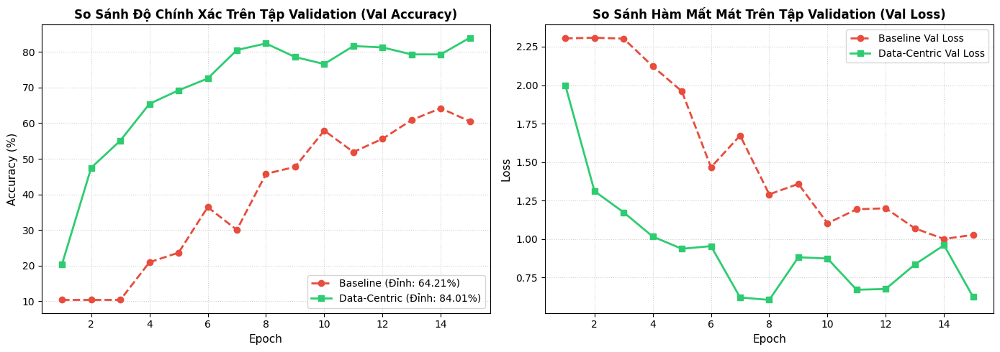

📊 BẢNG TỔNG KẾT SO SÁNH ĐỊNH LƯỢNG (TEST BENCHMARK TRÊN LABEL_BOOK):
 - Baseline VGG-16 Accuracy:     65.38%
 - Data-Centric VGG-16 Accuracy: 73.08%
 - Độ tăng trưởng tuyệt đối:    +7.69 điểm phần trăm
🚀 KẾT LUẬN: Phương pháp Data-Centric AI đã giúp tăng 7.69% độ chính xác mà không cần thay đổi bất kỳ dòng code kiến trúc mạng nào!
baseline: val macro-F1=0.6127
Recall theo lớp: {'i': np.float64(0.927), 'ii': np.float64(0.63), 'iii': np.float64(0.0), 'iv': np.float64(0.524), 'v': np.float64(0.542), 'vi': np.float64(0.671), 'vii': np.float64(0.818), 'viii': np.float64(0.819), 'ix': np.float64(0.642), 'x': np.float64(0.84)}
data_centric: val macro-F1=0.8402
Recall theo lớp: {'i': np.float64(0.878), 'ii': np.float64(0.778), 'iii': np.float64(0.835), 'iv': np.float64(0.655), 'v': np.float64(0.928), 'vi': np.float64(0.915), 'vii': np.float64(0.844), 'viii': np.float64(0.916), 'ix': np.float64(0.827), 'x': np.float64(0.827)}
Metrics: /content/deeplearningai-data-centric-competition/improved_v2

In [ ]:
# =============================================================================
# SO SÁNH TRỰC QUAN HIỆU NĂNG: BASELINE VS DATA-CENTRIC AI
# =============================================================================
epochs_range = range(1, len(history_baseline['train_acc']) + 1)

plt.figure(figsize=(14, 5))

# Đồ thị so sánh Validation Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, [acc * 100 for acc in history_baseline['val_acc']], 'o--', color='#e74c3c', label=f'Baseline (Đỉnh: {best_val_acc_baseline*100:.2f}%)', linewidth=2)
plt.plot(epochs_range, [acc * 100 for acc in history_dc['val_acc']], 's-', color='#2ecc71', label=f'Data-Centric (Đỉnh: {best_val_acc_dc*100:.2f}%)', linewidth=2)
plt.title("So Sánh Độ Chính Xác Trên Tập Validation (Val Accuracy)", fontsize=12, fontweight='bold')
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Accuracy (%)", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10)

# Đồ thị so sánh Validation Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history_baseline['val_loss'], 'o--', color='#e74c3c', label=f'Baseline Val Loss', linewidth=2)
plt.plot(epochs_range, history_dc['val_loss'], 's-', color='#2ecc71', label=f'Data-Centric Val Loss', linewidth=2)
plt.title("So Sánh Hàm Mất Mát Trên Tập Validation (Val Loss)", fontsize=12, fontweight='bold')
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Loss", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10)

plt.tight_layout()
plt.show()

# Đánh giá ma trận nhầm lẫn trên tập Test chuẩn (label_book)
test_preds_bl, test_labels_bl = get_predictions_and_labels(vgg_baseline, ds_test_baseline)
test_preds_dc, test_labels_dc = get_predictions_and_labels(vgg_datacentric, ds_test_baseline)

acc_bl_percent = (test_preds_bl == test_labels_bl).mean() * 100
acc_dc_percent = (test_preds_dc == test_labels_dc).mean() * 100
acc_gain = acc_dc_percent - acc_bl_percent

print("=" * 70)
print(f"📊 BẢNG TỔNG KẾT SO SÁNH ĐỊNH LƯỢNG (TEST BENCHMARK TRÊN LABEL_BOOK):")
print("=" * 70)
print(f" - Baseline VGG-16 Accuracy:     {acc_bl_percent:.2f}%")
print(f" - Data-Centric VGG-16 Accuracy: {acc_dc_percent:.2f}%")
print(f" - Độ tăng trưởng tuyệt đối:    {acc_gain:+.2f} điểm phần trăm")
print("=" * 70)
if acc_gain > 0:
    print(f"🚀 KẾT LUẬN: Phương pháp Data-Centric AI đã giúp tăng {acc_gain:.2f}% độ chính xác mà không cần thay đổi bất kỳ dòng code kiến trúc mạng nào!")
else:
    print("Chưa thấy cải thiện trên label_book; không kết luận phương pháp vượt trội.")

# Báo cáo theo lớp trên cùng validation để tìm lớp cần thu thập/sửa dữ liệu.
validation_report = {}
for name, model in [('baseline', vgg_baseline), ('data_centric', vgg_datacentric)]:
    preds, labels = get_predictions_and_labels(model, ds_val_baseline)
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    np.add.at(cm, (labels, preds), 1)
    recall = np.diag(cm) / np.maximum(cm.sum(axis=1), 1)
    precision = np.diag(cm) / np.maximum(cm.sum(axis=0), 1)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    validation_report[name] = dict(accuracy=float(np.trace(cm)/cm.sum()),
                                   macro_f1=float(f1.mean()),
                                   recall_by_class=dict(zip(CLASSES, recall.tolist())),
                                   confusion_matrix=cm.tolist())
    print(f"{name}: val macro-F1={f1.mean():.4f}")
    print('Recall theo lớp:', dict(zip(CLASSES, np.round(recall, 3))))
report = dict(seed=RANDOM_SEED, epochs=BASELINE_EPOCHS,
              train_baseline=len(train_paths_raw), train_improved=len(train_paths_imp),
              validation=len(val_paths_raw), label_book=len(test_paths_raw),
              steps_per_epoch_baseline=math.ceil(len(train_paths_raw)/BATCH_SIZE),
              steps_per_epoch_improved=math.ceil(len(train_paths_imp)/BATCH_SIZE),
              validation_metrics=validation_report,
              label_book_accuracy={'baseline': float(acc_bl_percent/100),
                                   'data_centric': float(acc_dc_percent/100)})
report_path = COMP_DIR / f'{IMPROVED_DIR.name}_metrics.json'
report_path.write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8')
print('Metrics:', report_path)


## Diễn giải baseline → V2 của lần chạy hiện tại

| Phương án | Validation accuracy | Val macro-F1 | Label_book |
|---|---:|---:|---:|
| Baseline | 64,21% | 0,6127 | 65,38% |
| V2 | 84,01% | 0,8402 | 73,08% |

Chênh lệch label_book là +7.69 điểm phần trăm, không phải mức tăng tương
đối. Không dùng mốc của lần chạy cũ thay số hiện tại. Checkpoint được chọn
bằng validation. Chưa có ablation để tách tác dụng từng thay đổi dữ liệu.
Không có sửa nhãn thủ công/tự động được xác nhận trong pipeline này.


## PHẦN 6 — V3 và mốc đầu vào hiện tại

Run hiện tại **`20261109T080842Z_47bed10a`**. V2 được chụp ở cell tiếp theo: validation
**84,01%**, macro-F1 **0,8402**, label_book
**73,08%**. Recall thấp ở `iv` (0.655), `ii` (0.778), `ix` (0.827), `x` (0.827).
Ngân sách V3 tính từ confusion matrix này, không từ phiên cũ.

Output sau huấn luyện của run này chọn **V2**. V3 hiện tại đạt validation
**77,49%**, label_book **67,31%**. Không bảo đảm
V3 cải thiện ở mọi lần chạy; xem số đo thực tế thay vì suy ra từ tên phiên bản.

### Giả thuyết V3

V2 bổ sung chủ yếu ảnh căn giữa, còn validation/test giữ khung hình raw.
V3 giữ toàn bộ raw và centered rồi tạo **hỗn hợp biến thể từ cả hai miền ảnh**:
raw chiếm 60% nhánh sinh augmentation; centered chiếm 40%. Co giãn nhẹ hai
chiều, shear nhỏ, xoay/dịch và biến đổi hình học nhẹ giúp đa dạng kiểu viết; V3 không jitter tương phản riêng.
Không erosion/dilation, không lật, không tự đổi nhãn.

Giữ **8.000 ảnh train** như V2, nhưng phân bổ ngân sách theo lỗi validation
đã làm trơn, giới hạn trọng số để tránh dồn hết vào lớp khó. Đây là hai thay
đổi đồng thời (miền augmentation + phân bổ), nên kết quả chỉ đánh giá cả gói;
muốn tách tác dụng cần ablation bổ sung. Không bảo đảm V3 sẽ thắng V2.

Chạy các cell dưới **sau khi phần V2 đã hoàn thành trong cùng runtime**.
V3 khởi tạo từ đầu, giữ VGG, Adam, LR, dropout, batch size và số epoch của V2.
Validation giữ nguyên byte; không dùng label_book để tạo dữ liệu/chọn mô hình.
Mọi lần chạy tạo thư mục riêng, lưu checkpoint, dataset, manifest, curves và
metrics. Nhật ký JSONL chỉ nối thêm. Không thay biến/model của V2.

**Colab:** `/content` sẽ mất khi reset runtime. Muốn giữ qua các phiên, đặt
`HISTORY_ROOT` vào thư mục Google Drive đã mount trước khi chạy cell tiếp theo;
các file dataset/checkpoint trong mỗi thư mục run được giữ cùng lịch sử.


In [ ]:
# V3.1 — Chụp lại V2 và tạo run riêng để lưu lịch sử.
from datetime import datetime, timezone
import uuid
import hashlib
from PIL import ImageEnhance

required_v3 = ['vgg_datacentric', 'history_dc', 'ds_val_baseline',
               'train_paths_raw', 'train_labels_raw', 'val_paths_raw',
               'val_labels_raw', 'validation_report', 'BASELINE_EPOCHS']
missing_v3 = [name for name in required_v3 if name not in globals()]
if missing_v3:
    raise RuntimeError('Chạy xong phần V2 trong cùng runtime trước: ' + ', '.join(missing_v3))

# Có thể đặt HISTORY_ROOT ở cell riêng trước cell này, ví dụ thư mục Drive đã mount.
HISTORY_ROOT = Path(globals().get('HISTORY_ROOT', COMP_DIR / 'optimization_history')).resolve()
HISTORY_ROOT.mkdir(parents=True, exist_ok=True)
V3_RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8]
V3_RUN_DIR = HISTORY_ROOT / V3_RUN_ID
V3_RUN_DIR.mkdir()

def write_json_v3(path, payload):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    def convert(value):
        if isinstance(value, np.generic):
            return value.item()
        if isinstance(value, np.ndarray):
            return value.tolist()
        if isinstance(value, Path):
            return str(value)
        raise TypeError(f'Không serialize được {type(value).__name__}')
    temporary.write_text(json.dumps(payload, ensure_ascii=False, indent=2,
                                   allow_nan=False, default=convert), encoding='utf-8')
    temporary.replace(path)

def log_event_v3(event, **details):
    row = dict(run_id=V3_RUN_ID, time_utc=datetime.now(timezone.utc).isoformat(),
               event=event, **details)
    with (HISTORY_ROOT / 'history.jsonl').open('a', encoding='utf-8') as stream:
        stream.write(json.dumps(row, ensure_ascii=False, allow_nan=False) + '\n')

def metrics_v3(model, dataset):
    preds, labels = get_predictions_and_labels(model, dataset)
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    np.add.at(cm, (labels, preds), 1)
    recall = np.diag(cm) / np.maximum(cm.sum(axis=1), 1)
    precision = np.diag(cm) / np.maximum(cm.sum(axis=0), 1)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    loss, accuracy = pure_evaluate(model, dataset)
    if not np.isfinite(loss) or cm.sum() == 0:
        raise ValueError('Metrics không hợp lệ')
    return dict(loss=float(loss), accuracy=float(accuracy), macro_f1=float(f1.mean()),
                recall_by_class=dict(zip(CLASSES, recall.tolist())), confusion_matrix=cm.tolist())

v2_frozen_metrics = metrics_v3(vgg_datacentric, ds_val_baseline)
PureModelWeightsSaver.save_weights(vgg_datacentric, str(V3_RUN_DIR / 'v2_reference.npz'))
v2_saved_dataset = V3_RUN_DIR / 'v2_dataset.zip'
with zipfile.ZipFile(v2_saved_dataset, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for image in sorted(IMPROVED_DIR.rglob('*.png')):
        zf.write(image, image.relative_to(IMPROVED_DIR).as_posix())
if len(list(IMPROVED_DIR.rglob('*.png'))) != len(train_paths_imp) + len(val_paths_imp):
    raise ValueError('Dataset V2 hiện tại không khớp danh sách ảnh đã train')
v2_manifest_path = COMP_DIR / f'{IMPROVED_DIR.name}_manifest.json'
if v2_manifest_path.exists():
    shutil.copy2(v2_manifest_path, V3_RUN_DIR / 'v2_manifest.json')
v3_split_fingerprint = hashlib.sha256(json.dumps(
    [(CLASSES[y], pixel_hash(p)) for p, y in zip(val_paths_raw, val_labels_raw)],
    separators=(',', ':')).encode()).hexdigest()
write_json_v3(V3_RUN_DIR / 'v2_reference.json', dict(
    provenance='measured_current_runtime', validation=v2_frozen_metrics,
    history=history_dc, validation_fingerprint=v3_split_fingerprint,
    label_book_accuracy=float(acc_dc_percent / 100),
    train_count=len(train_paths_imp), epochs=BASELINE_EPOCHS))
write_json_v3(V3_RUN_DIR / 'reported_previous_run.json', dict(
    provenance='user_reported_colab_run', baseline_label_book_accuracy=0.6154,
    v2_label_book_accuracy=0.7308, baseline_val_macro_f1=0.7065,
    v2_val_macro_f1=0.8223))
log_event_v3('started', validation_fingerprint=v3_split_fingerprint,
             v2_validation=v2_frozen_metrics)
print('Thư mục lịch sử lần chạy này:', V3_RUN_DIR)
print('V2 hiện tại, validation:', v2_frozen_metrics)


Thư mục lịch sử lần chạy này: /content/deeplearningai-data-centric-competition/optimization_history/20261109T080842Z_47bed10a
V2 hiện tại, validation: {'loss': 0.6241070032119751, 'accuracy': 0.8400983810424805, 'macro_f1': 0.8402450396815204, 'recall_by_class': {'i': 0.8780487804878049, 'ii': 0.7777777777777778, 'iii': 0.8354430379746836, 'iv': 0.6547619047619048, 'v': 0.927710843373494, 'vi': 0.9146341463414634, 'vii': 0.8441558441558441, 'viii': 0.9156626506024096, 'ix': 0.8271604938271605, 'x': 0.8271604938271605}, 'confusion_matrix': [[72, 5, 2, 0, 1, 0, 0, 0, 0, 2], [4, 63, 6, 0, 3, 2, 0, 0, 2, 1], [0, 3, 66, 4, 0, 3, 0, 3, 0, 0], [1, 5, 5, 55, 1, 2, 0, 0, 15, 0], [0, 3, 0, 0, 77, 1, 0, 0, 1, 1], [0, 1, 3, 1, 1, 75, 0, 0, 0, 1], [0, 1, 6, 0, 1, 2, 65, 2, 0, 0], [0, 1, 1, 1, 0, 0, 4, 76, 0, 0], [0, 3, 2, 5, 1, 1, 0, 1, 67, 1], [2, 1, 0, 0, 4, 1, 0, 0, 6, 67]]}


Ngân sách V3: {'i': 763, 'ii': 871, 'iii': 809, 'iv': 965, 'v': 710, 'vi': 724, 'vii': 800, 'viii': 722, 'ix': 818, 'x': 818} | Tổng: 8000


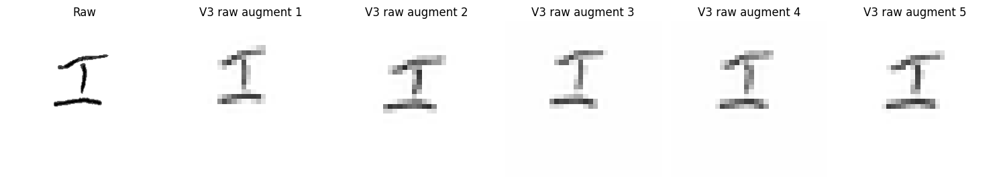

In [ ]:
# V3.2 — Augmentation hỗn hợp và ngân sách theo lỗi validation.
def allocate_budget_v3(cm, total=8000):
    cm = np.asarray(cm, dtype=float)
    if cm.shape != (NUM_CLASSES, NUM_CLASSES) or (cm.sum(axis=1) == 0).any():
        raise ValueError('Mỗi lớp phải có validation và confusion matrix đúng shape')
    # Beta smoothing tránh lỗi một vài ảnh làm ngân sách biến động quá mạnh.
    smoothed_error = (cm.sum(axis=1) - np.diag(cm) + 2) / (cm.sum(axis=1) + 10)
    weights = np.clip(1 + 1.5 * (smoothed_error - smoothed_error.mean()), 0.85, 1.20)
    quotas = weights / weights.sum() * total
    counts = np.floor(quotas).astype(int)
    order = np.argsort(-(quotas - counts), kind='stable')
    counts[order[:total - int(counts.sum())]] += 1
    assert counts.sum() == total
    return dict(zip(CLASSES, counts.tolist()))

def augment_mixed_v3(image, rng):
    canvas = image.convert('L').resize((96, 96), Image.Resampling.BICUBIC)
    canvas = canvas.rotate(float(rng.uniform(-6, 6)),
                           resample=Image.Resampling.BICUBIC, fillcolor=255)
    sx, sy = rng.uniform(0.88, 1.12, size=2)
    shear = float(rng.uniform(-0.07, 0.07))
    dx, dy = rng.uniform(-3, 3, size=2)
    # Pillow affine map: tọa độ output -> input, tâm giữ ở (48, 48).
    a, e = 1 / sx, 1 / sy
    canvas = canvas.transform((96, 96), Image.Transform.AFFINE,
        (a, shear, 48 - 48*a - 48*shear + dx, 0, e, 48 - 48*e + dy),
        resample=Image.Resampling.BICUBIC, fillcolor=255)
    canvas = ImageEnhance.Contrast(canvas).enhance(float(rng.uniform(0.90, 1.10)))
    result = canvas.resize((32, 32), Image.Resampling.LANCZOS)
    before = np.asarray(image.convert('L').resize((32, 32)), dtype=float)
    after = np.asarray(result, dtype=float)
    # Reject nếu mất quá nhiều mực; không bảo đảm giữ nguyên ngữ nghĩa mọi ảnh.
    if (255 - after).sum() < 0.75 * (255 - before).sum():
        return image.convert('L').resize((32, 32), Image.Resampling.LANCZOS)
    return result

v3_targets = allocate_budget_v3(v2_frozen_metrics['confusion_matrix'])
print('Ngân sách V3:', v3_targets, '| Tổng:', sum(v3_targets.values()))
rng_v3_preview = np.random.default_rng(RANDOM_SEED + 3000)
with Image.open(train_paths_raw[0]) as image:
    raw_v3_preview = image.convert('L')
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for idx, ax in enumerate(axes):
    ax.imshow(raw_v3_preview if idx == 0 else augment_mixed_v3(raw_v3_preview, rng_v3_preview),
              cmap='gray', vmin=0, vmax=255)
    ax.set_title('Raw' if idx == 0 else f'V3 raw augment {idx}')
    ax.axis('off')
plt.tight_layout()
plt.show()


In [ ]:
# V3.3 — Builder độc lập, không sử dụng biến manifest/model của V2.
def build_dataset_v3(destination, train_paths, train_labels, val_paths, val_labels,
                     targets, seed=123):
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=False)
    rng = np.random.default_rng(seed)
    rows, train_seen, validation_hashes = [], set(), {pixel_hash(p) for p in val_paths}
    source_keys = {str(Path(p).resolve()) for p in train_paths}
    if source_keys & {str(Path(p).resolve()) for p in val_paths}:
        raise ValueError('Nguồn train và val giao nhau')
    if {pixel_hash(p) for p in train_paths} & validation_hashes:
        raise ValueError('Train còn ảnh trùng validation')
    for cls in CLASSES:
        (destination / 'train' / cls).mkdir(parents=True)
        (destination / 'val' / cls).mkdir(parents=True)
    for source, label in zip(val_paths, val_labels):
        out = destination / 'val' / CLASSES[label] / Path(source).name
        if out.exists():
            raise ValueError('Tên validation trùng nhau')
        shutil.copy2(source, out)
        assert out.read_bytes() == Path(source).read_bytes()
        rows.append(dict(file=out.relative_to(destination).as_posix(), split='val',
                         source=str(Path(source).resolve()), transform='raw', pixel_hash=pixel_hash(out)))
    for label, cls in enumerate(CLASSES):
        sources = [p for p, y in zip(train_paths, train_labels) if y == label]
        if not sources:
            raise ValueError(f'Thiếu nguồn train: {cls}')
        pool, count = [], 0
        def save(image, source, transform):
            nonlocal count
            image = image.convert('RGB')
            key = hashlib.sha256(str(image.size).encode() + image.tobytes()).hexdigest()
            if key in train_seen or key in validation_hashes:
                return False
            out = destination / 'train' / cls / f'{count:05d}.png'
            image.save(out)
            train_seen.add(key)
            rows.append(dict(file=out.relative_to(destination).as_posix(), split='train',
                             source=str(Path(source).resolve()), transform=transform, pixel_hash=key))
            count += 1
            return True
        # Giữ mọi raw trước khi thêm centered và ảnh tổng hợp.
        for source in sources:
            with Image.open(source) as image:
                raw = image.convert('L')
                centered = crop_and_center_digit(clean_and_binarize_image(image))
                save(image, source, 'raw')
            pool.append((source, raw, centered))
        for source, raw, centered in pool:
            save(centered, source, 'center')
        if count > targets[cls]:
            raise ValueError(f'Budget {cls} không đủ giữ mọi raw + centered')
        attempts, max_attempts = 0, targets[cls] * 40
        source_order = rng.permutation(len(pool))
        while count < targets[cls] and attempts < max_attempts:
            if attempts and attempts % len(pool) == 0:
                source_order = rng.permutation(len(pool))
            source, raw, centered = pool[int(source_order[attempts % len(pool)])]
            raw_branch = rng.random() < 0.60
            base = raw if raw_branch else centered
            save(augment_mixed_v3(base, rng), source,
                 'raw+affine+contrast' if raw_branch else 'center+affine+contrast')
            attempts += 1
        if count != targets[cls]:
            raise RuntimeError(f'Không đủ ảnh duy nhất cho {cls}; dataset chưa hoàn tất')
        print(f'{cls}: {count} train')
    n_train = sum(row['split'] == 'train' for row in rows)
    n_val = len(rows) - n_train
    rounded = (math.ceil(n_train / 8) + math.ceil(n_val / 8)) * 8
    assert len(rows) < 10000 and rounded <= 10000
    assert len(list(destination.rglob('*.png'))) == len(rows)
    assert not (train_seen & validation_hashes)
    manifest = dict(seed=seed, targets=targets, total=len(rows), evaluator_count=rounded,
                    train=n_train, val=n_val, images=rows)
    write_json_v3(destination.parent / 'manifest.json', manifest)
    archive_path = destination.parent / 'dataset.zip'
    with zipfile.ZipFile(archive_path, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
        for image in sorted(destination.rglob('*.png')):
            zf.write(image, image.relative_to(destination).as_posix())
    return manifest, archive_path

V3_DATA_DIR = V3_RUN_DIR / 'dataset'
v3_manifest, v3_archive = build_dataset_v3(
    V3_DATA_DIR, train_paths_raw, train_labels_raw, val_paths_raw, val_labels_raw,
    v3_targets, RANDOM_SEED)
assert v3_manifest['train'] == len(train_paths_imp) == 8000
write_json_v3(V3_RUN_DIR / 'config.json', dict(
    model='PureVGG16', fc_dim=512, learning_rate=LEARNING_RATE, batch_size=BATCH_SIZE,
    epochs=BASELINE_EPOCHS, dropout=0.4, seed=RANDOM_SEED,
    targets=v3_targets, augmentation_raw_probability=0.60,
    checkpoint_selection='validation_accuracy', validation_fingerprint=v3_split_fingerprint))
log_event_v3('dataset_ready', train=v3_manifest['train'], val=v3_manifest['val'],
             archive=str(v3_archive))
print('Dataset V3:', v3_archive)


i: 763 train
ii: 871 train
iii: 809 train
iv: 965 train
v: 710 train
vi: 724 train
vii: 800 train
viii: 722 train
ix: 818 train
x: 818 train
Dataset V3: /content/deeplearningai-data-centric-competition/optimization_history/20261109T080842Z_47bed10a/dataset.zip


### V3: huấn luyện từ đầu, cùng ngân sách với V2

Cell sau chạy thêm một lần huấn luyện đầy đủ. Mỗi epoch ghi curves và nhật ký
ra đĩa; checkpoint riêng được chọn theo validation accuracy giống V2.
Nếu ngắt giữa chừng, file `training_status.json` đánh dấu trạng thái và epoch
hoàn tất. Chưa hỗ trợ resume optimizer giữa epoch; hãy tạo run mới để thử lại.
Không ghi kết quả test theo từng epoch.


In [ ]:
# V3.4 — Train model mới; không fine-tune model V2.
if (V3_RUN_DIR / 'training_status.json').exists():
    raise RuntimeError('Run này đã bắt đầu train. Chạy lại từ V3.1 để tạo run mới, giữ lịch sử cũ.')
v3_train_paths, v3_train_labels = collect_paths_and_labels(V3_DATA_DIR / 'train')
tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
ds_train_v3 = create_pure_tf_dataset(v3_train_paths, v3_train_labels,
                                    batch_size=BATCH_SIZE, shuffle=True)
vgg_v3 = PureVGG16(num_classes=NUM_CLASSES, fc_dim=512)
opt_v3 = PureAdamOptimizer(vgg_v3.trainable_variables, lr=LEARNING_RATE)

@tf.function(reduce_retracing=True)
def train_step_v3(x, y):
    return pure_train_step(vgg_v3, opt_v3, x, y, dropout_rate=0.4)

history_v3 = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[])
v3_best_acc, v3_best_epoch = -1.0, 0
v3_checkpoint = V3_RUN_DIR / 'v3_best_weights.npz'
write_json_v3(V3_RUN_DIR / 'training_status.json', dict(status='running', completed_epochs=0))
try:
    for epoch in range(1, BASELINE_EPOCHS + 1):
        loss_sum = acc_sum = 0.0
        n_samples = 0
        for x, y in ds_train_v3:
            loss, acc = train_step_v3(x, y)
            n = int(tf.shape(y)[0])
            loss_sum += float(loss) * n
            acc_sum += float(acc) * n
            n_samples += n
        val_loss, val_acc = pure_evaluate(vgg_v3, ds_val_baseline)
        if not np.isfinite([loss_sum, acc_sum, val_loss, val_acc]).all():
            raise FloatingPointError('Loss/accuracy không hữu hạn; dừng run')
        for key, value in dict(train_loss=loss_sum/n_samples, train_acc=acc_sum/n_samples,
                               val_loss=val_loss, val_acc=val_acc).items():
            history_v3[key].append(float(value))
        if val_acc > v3_best_acc:
            v3_best_acc, v3_best_epoch = float(val_acc), epoch
            PureModelWeightsSaver.save_weights(vgg_v3, str(v3_checkpoint))
        write_json_v3(V3_RUN_DIR / 'curves.json', history_v3)
        write_json_v3(V3_RUN_DIR / 'training_status.json', dict(
            status='running', completed_epochs=epoch, best_epoch=v3_best_epoch))
        log_event_v3('epoch_completed', epoch=epoch, val_loss=float(val_loss),
                     val_accuracy=float(val_acc))
        print(f'V3 {epoch:02d}/{BASELINE_EPOCHS}: train={acc_sum/n_samples:.4f}, '
              f'val={val_acc:.4f}, loss={val_loss:.4f}, best_epoch={v3_best_epoch}')
except BaseException as error:
    write_json_v3(V3_RUN_DIR / 'training_status.json', dict(
        status='interrupted_or_failed', completed_epochs=len(history_v3['val_acc']),
        error_type=type(error).__name__, message=str(error)))
    log_event_v3('interrupted_or_failed', error_type=type(error).__name__)
    raise

PureModelWeightsSaver.load_weights(vgg_v3, str(v3_checkpoint))
v3_val_metrics = metrics_v3(vgg_v3, ds_val_baseline)
write_json_v3(V3_RUN_DIR / 'v3_validation.json', v3_val_metrics)
write_json_v3(V3_RUN_DIR / 'training_status.json', dict(
    status='completed', completed_epochs=BASELINE_EPOCHS, best_epoch=v3_best_epoch))
log_event_v3('training_completed', best_epoch=v3_best_epoch, validation=v3_val_metrics)
print('V3 validation:', v3_val_metrics)


V3 01/15: train=0.1104, val=0.1033, loss=2.3045, best_epoch=1
V3 02/15: train=0.1182, val=0.1033, loss=2.3045, best_epoch=1
V3 03/15: train=0.1202, val=0.1033, loss=2.3058, best_epoch=1
V3 04/15: train=0.1206, val=0.1033, loss=2.3058, best_epoch=1
V3 05/15: train=0.1202, val=0.1033, loss=2.3052, best_epoch=1
V3 06/15: train=0.1207, val=0.1033, loss=2.3070, best_epoch=1
V3 07/15: train=0.1211, val=0.1033, loss=2.3060, best_epoch=1
V3 08/15: train=0.1214, val=0.1033, loss=2.3057, best_epoch=1
V3 09/15: train=0.2685, val=0.3567, loss=1.5390, best_epoch=9
V3 10/15: train=0.4353, val=0.4686, loss=1.3434, best_epoch=10
V3 11/15: train=0.5447, val=0.5597, loss=1.1374, best_epoch=11
V3 12/15: train=0.6271, val=0.6408, loss=0.9773, best_epoch=12
V3 13/15: train=0.6924, val=0.6667, loss=0.9804, best_epoch=13
V3 14/15: train=0.7528, val=0.7048, loss=0.9416, best_epoch=14
V3 15/15: train=0.8201, val=0.7749, loss=0.8157, best_epoch=15
V3 validation: {'loss': 0.8156893849372864, 'accuracy': 0.774907

Lựa chọn bằng validation: V2
Version         Val acc   Macro-F1   Label book
V2               0.8401     0.8402      73.08%
V3               0.7749     0.7716      67.31%
V3 − V2 label-book: -5.77 điểm phần trăm
Label_book nhỏ; một ảnh tương ứng 1.92 điểm phần trăm.


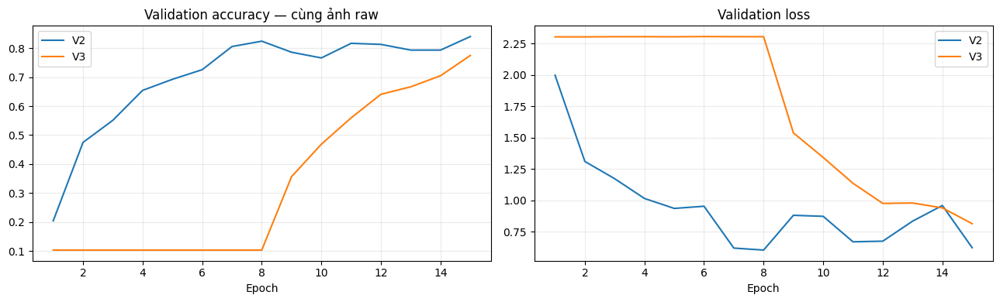

In [ ]:
# V3.5 — Chốt lựa chọn chỉ theo validation, sau đó mới báo cáo label_book.
def validation_rank_v3(metrics):
    return (metrics['accuracy'], metrics['macro_f1'], -metrics['loss'])

selected_version_v3 = 'V3' if validation_rank_v3(v3_val_metrics) > validation_rank_v3(v2_frozen_metrics) else 'V2'
selection_v3 = dict(selected=selected_version_v3,
                    criterion='val accuracy, tie-break macro-F1, then lower loss',
                    v2_validation=v2_frozen_metrics, v3_validation=v3_val_metrics,
                    selected_checkpoint=str(v3_checkpoint if selected_version_v3 == 'V3' else V3_RUN_DIR / 'v2_reference.npz'),
                    selected_dataset=str(v3_archive if selected_version_v3 == 'V3' else v2_saved_dataset),
                    validation_fingerprint=v3_split_fingerprint)
write_json_v3(V3_RUN_DIR / 'selection.json', selection_v3)
log_event_v3('selected_before_label_book', selected=selected_version_v3)
print('Lựa chọn bằng validation:', selected_version_v3)

# Tham khảo công khai; không dùng giá trị sau đây để đổi selection.
v3_lb_loss, v3_lb_acc = pure_evaluate(vgg_v3, ds_test_baseline)
v3_result = dict(run_id=V3_RUN_ID, provenance='measured_current_runtime',
                 v2_validation=v2_frozen_metrics, v3_validation=v3_val_metrics,
                 v2_label_book_accuracy=float(acc_dc_percent/100),
                 v3_label_book_accuracy=float(v3_lb_acc),
                 selected_by_validation=selected_version_v3,
                 validation_fingerprint=v3_split_fingerprint,
                 label_book_count=len(test_paths_raw), epochs=BASELINE_EPOCHS,
                 checkpoint=str(v3_checkpoint), dataset=str(v3_archive))
write_json_v3(V3_RUN_DIR / 'results.json', v3_result)
log_event_v3('reported', selected=selected_version_v3,
             v3_label_book_accuracy=float(v3_lb_acc))

print(f"{'Version':<12} {'Val acc':>10} {'Macro-F1':>10} {'Label book':>12}")
for version, metrics, lb in [('V2', v2_frozen_metrics, acc_dc_percent/100),
                              ('V3', v3_val_metrics, float(v3_lb_acc))]:
    print(f"{version:<12} {metrics['accuracy']:>10.4f} {metrics['macro_f1']:>10.4f} {lb:>11.2%}")
print(f'V3 − V2 label-book: {(float(v3_lb_acc)-acc_dc_percent/100)*100:+.2f} điểm phần trăm')
print('Label_book nhỏ; một ảnh tương ứng', round(100/len(test_paths_raw), 2), 'điểm phần trăm.')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, curves in [('V2', history_dc), ('V3', history_v3)]:
    epochs = np.arange(1, len(curves['val_acc']) + 1)
    axes[0].plot(epochs, curves['val_acc'], label=name)
    axes[1].plot(epochs, curves['val_loss'], label=name)
for ax, title in zip(axes, ['Validation accuracy — cùng ảnh raw', 'Validation loss']):
    ax.set(title=title, xlabel='Epoch')
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
fig.savefig(V3_RUN_DIR / 'comparison.png', dpi=150)
plt.show()


In [ ]:
# V3.6 — Tổng hợp mọi run, giữ kết quả cũ dù thử nghiệm mới không tốt hơn.
print('LỊCH SỬ ĐO THỰC TẾ (không trộn với bảng số liệu người dùng báo cáo)')
for result_file in sorted(HISTORY_ROOT.glob('*/results.json')):
    row = json.loads(result_file.read_text(encoding='utf-8'))
    compatible = row['validation_fingerprint'] == v3_split_fingerprint
    print(row['run_id'], '| split:', 'same' if compatible else 'DIFFERENT',
          '| V3 val:', round(row['v3_validation']['accuracy'], 4),
          '| F1:', round(row['v3_validation']['macro_f1'], 4),
          '| label_book:', round(row['v3_label_book_accuracy'], 4),
          '| selected:', row['selected_by_validation'])

# Xem các cặp nhầm trên validation để thiết kế V4; không tự sửa nhãn theo model.
cm_v3 = np.asarray(v3_val_metrics['confusion_matrix'])
pairs_v3 = sorted([(int(cm_v3[i, j]), CLASSES[i], CLASSES[j])
                   for i in range(NUM_CLASSES) for j in range(NUM_CLASSES)
                   if i != j and cm_v3[i, j] > 0], reverse=True)
print('Các cặp nhầm V3 trên validation:', pairs_v3[:10])
print('Artifacts của lần chạy:', V3_RUN_DIR)
print('Nhật ký nối thêm:', HISTORY_ROOT / 'history.jsonl')


LỊCH SỬ ĐO THỰC TẾ (không trộn với bảng số liệu người dùng báo cáo)
20261109T054449Z_3adedb09 | split: same | V3 val: 0.8942 | F1: 0.8933 | label_book: 0.7885 | selected: V3
20261109T063013Z_3abf24f6 | split: same | V3 val: 0.8782 | F1: 0.8778 | label_book: 0.7692 | selected: V3
20261109T080842Z_47bed10a | split: same | V3 val: 0.7749 | F1: 0.7716 | label_book: 0.6731 | selected: V2
Các cặp nhầm V3 trên validation: [(24, 'ix', 'iv'), (24, 'iii', 'vii'), (18, 'vii', 'viii'), (12, 'ii', 'vi'), (10, 'iv', 'ix'), (9, 'iv', 'iii'), (8, 'x', 'v'), (7, 'vi', 'vii'), (6, 'v', 'ii'), (5, 'viii', 'vii')]
Artifacts của lần chạy: /content/deeplearningai-data-centric-competition/optimization_history/20261109T080842Z_47bed10a
Nhật ký nối thêm: /content/deeplearningai-data-centric-competition/optimization_history/history.jsonl


### Kết quả hiện tại và lịch sử — không gộp run

| Run V3 | Val accuracy | Macro-F1 | Label_book | Phần 6 chọn |
|---|---:|---:|---:|---|
| `20261109T054449Z_3adedb09` | 89,42% | 0,8933 | 78,85% | V3 |
| `20261109T063013Z_3abf24f6` | 87,82% | 0,8778 | 76,92% | V3 |
| `20261109T080842Z_47bed10a` | 77,49% | 0,7716 | 67,31% | V2 |

Run hiện tại `20261109T080842Z_47bed10a` chọn **V2**. V3 đạt validation 77,49%
và label_book 67,31%, so với V2 84,01% và
73,08%; chênh lệch label_book **-5.77 điểm phần trăm**.
Không kết luận “V3 luôn tốt hơn V2”. Các dòng lịch sử thuộc những run trước;
V4 có campaign/cache riêng, không phải cùng model V3 vừa train.


## PHẦN 7 — V4 trên T4: phân biệt campaign đã lưu và run V3 mới

Phần 6 đang lưu là run `20261109T080842Z_47bed10a`, V3 có validation 77,49%,
macro-F1 0,7716, label_book 67,31%; phần 6 chọn V2.

V4 dùng campaign `v4_t4` và tái sử dụng các trial đã hoàn tất nếu cùng cấu
hình/fingerprint. Vì thế bảng V4 đã lưu không đồng nghĩa đã train lại trên
dataset của run V3 mới. Xem `campaign.json` để xác nhận dataset đối chứng.
Đổi dataset đối chứng cần campaign mới; không cần chạy lại chỉ để đọc báo cáo.

Output V4 chọn `v3_control`; mean validation 87,66%
qua 3 seed. Label_book trong output hiện tại: **Không in lại — đọc cache**. Nếu cell chỉ báo
đọc cache, lấy điểm từ `final_report.json`; không tự chèn số của run khác.

Thời gian GPU thực tế phải đo; T4 không bảo đảm có một lượng quota Colab cụ
thể. Mặc định **90 phút mỗi phiên**, kiểm tra deadline từng batch. Có thể chạy
lại cell điều phối để tiếp tục. Tệp history/checkpoint phải nằm trên Drive đã
mount nếu muốn giữ qua khi Colab reset. Giới hạn thời gian gồm cả dựng dữ liệu
và train; giải mã/ghi file hoặc một batch đang chạy có thể vượt deadline một chút.

Quy trình: 8 cấu hình gồm V3 đối chứng → sàng lọc 4 epoch → tối đa 3 ứng viên
tốt nhất + đối chứng học đủ 15 epoch → ứng viên dẫn đầu và đối chứng chạy
**3 seed**. Sàng lọc có thể bỏ sót cấu hình học chậm. Không thay VGG/Adam/LR/
batch/dropout. Cùng số epoch chưa đồng nghĩa cùng số bước khi train lớn hơn.
V3 đối chứng được train lại bằng cùng engine với V4 để tránh khác pipeline.

Ứng viên gồm raw/centered với nhiều tỷ lệ, padding biến thiên, nhiễu/blur nhẹ,
ngân sách ảnh gần giới hạn evaluator, và 8–16% chữ La Mã vẽ bằng nét cong
ngẫu nhiên. Chữ tổng hợp là giả thuyết, cần xem preview và validation; không
được coi là dữ liệu đã xác minh bằng tay. Không tự đổi nhãn, không lật ảnh.

Chọn bằng validation mean accuracy trên 3 seed, cần tăng tối thiểu tương đương
2 ảnh và tốt hơn ở ít nhất 2/3 seed; nếu không, giữ V3. Đây là kiểm tra độ ổn
định, chưa chứng minh ý nghĩa thống kê với chỉ 3 seed. Sau khi chốt mới đo
label_book **một lần cho lựa chọn cuối**; không dùng nó trong tìm kiếm.

Điều kiện kết thúc phân biệt rõ: `budget_exhausted` (chạy tiếp),
`search_space_completed` (đã xét ngân sách ứng viên định trước). Không có kết
luận “không thể cải thiện nữa”: finite search không chứng minh tối ưu toàn cục.
Tối ưu nhiều lần trên cùng validation có thể overfit; cần holdout theo người
viết mới để kiểm chứng tổng quát hóa trước khi đưa ra khẳng định mạnh.

**Lần đầu:** chạy sau V3, hoặc trỏ `V4_CONTROL_DATA_DIR` vào dataset V3 đã lưu
và cung cấp `V4_REFERENCE_METRICS` (dict từ `v3_validation.json`). **Chạy tiếp:**
giữ nguyên `V4_CAMPAIGN_DIR`; bootstrap phía dưới tự nạp các định nghĩa cũ
nếu cần, không train lại baseline/V2/V3. Các cell cũ và output cũ được giữ nguyên.


In [ ]:
# V4.0 — Bootstrap khi reset runtime; không chạy các vòng train cũ.
# Định nghĩa được chụp từ phiên bản notebook này để V4 tự hoạt động.
v4_required = ['PureVGG16', 'PureAdamOptimizer', 'PureModelWeightsSaver',
               'train_paths_raw', 'val_paths_raw', 'ds_val_baseline',
               'parse_image_and_label', 'pixel_hash', 'allocate_budget_v3',
               'augment_mixed_v3', 'crop_and_center_digit']
if not all(name in globals() for name in v4_required):
    # =============================================================================
    # THIẾT LẬP MÔI TRƯỜNG & KHAI BÁO CẤU HÌNH HỆ THỐNG
    # =============================================================================
    import os
    import sys
    import glob
    import json
    import math
    import shutil
    import tarfile
    import zipfile
    import subprocess
    from pathlib import Path
    from collections import Counter, defaultdict

    import numpy as np
    import matplotlib.pyplot as plt
    from PIL import Image, ImageOps, ImageFilter
    from scipy import ndimage

    import tensorflow as tf

    RANDOM_SEED = 123
    tf.random.set_seed(RANDOM_SEED)
    np.random.seed(RANDOM_SEED)
    os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

    CLASSES = ['i', 'ii', 'iii', 'iv', 'v', 'vi', 'vii', 'viii', 'ix', 'x']
    NUM_CLASSES = len(CLASSES)
    CLASS_TO_IDX = {cls_name: i for i, cls_name in enumerate(CLASSES)}
    IDX_TO_CLASS = {i: cls_name for i, cls_name in enumerate(CLASSES)}

    # Xác định đường dẫn thư mục cạnh tranh
    ROOT_DIR = Path(".").resolve()
    COMP_DIR = ROOT_DIR if (ROOT_DIR / "label_book").exists() else ROOT_DIR / "deeplearningai-data-centric-competition"

    # Tải repository nếu chưa có
    if not COMP_DIR.exists():
        print("⏳ Đang tải repository chứa dữ liệu từ GitHub...")
        subprocess.run(["git", "clone", "https://github.com/nov05/deeplearningai-data-centric-competition.git"], check=True)
        COMP_DIR = ROOT_DIR / "deeplearningai-data-centric-competition"

    DATA_TRAIN_DIR = COMP_DIR / "data" / "train"
    DATA_VAL_DIR = COMP_DIR / "data" / "val"
    LABEL_BOOK_DIR = COMP_DIR / "label_book"

    # TỰ ĐỘNG GIẢI NÉN original/data.tar.gz NẾU CHƯA CÓ DATA/TRAIN
    tar_data_path = COMP_DIR / "original" / "data.tar.gz"
    if not DATA_TRAIN_DIR.exists() and tar_data_path.exists():
        print(f"📦 Đang tự động giải nén {tar_data_path.name}...")
        with tarfile.open(tar_data_path, "r:gz") as tar:
            tar.extractall(path=COMP_DIR, filter="data")
        print("✅ Đã giải nén dữ liệu Train & Val thành công!")

    tar_lb_path = COMP_DIR / "original" / "label_book.tar.gz"
    if not LABEL_BOOK_DIR.exists() and tar_lb_path.exists():
        print(f"📦 Đang tự động giải nén {tar_lb_path.name}...")
        with tarfile.open(tar_lb_path, "r:gz") as tar:
            tar.extractall(path=COMP_DIR, filter="data")
        print("✅ Đã giải nén label_book thành công!")

    print(f"\nThư mục Train gốc: {DATA_TRAIN_DIR} (Tồn tại: {DATA_TRAIN_DIR.exists()})")
    print(f"Thư mục Val gốc:   {DATA_VAL_DIR} (Tồn tại: {DATA_VAL_DIR.exists()})")
    print(f"Thư mục Test gốc:  {LABEL_BOOK_DIR} (Tồn tại: {LABEL_BOOK_DIR.exists()})")

    # =============================================================================
    # CÀI ĐẶT KIẾN TRÚC VGG-16 BẰNG PURE TENSORFLOW (NO KERAS)
    # =============================================================================
    class PureVGG16(tf.Module):
        """
        Mô hình VGG-16 hoàn chỉnh được xây dựng thuần túy bằng các toán tử cốt lõi của TensorFlow.
        Kế thừa tf.Module để quản lý các biến trạng thái (tf.Variable) một cách chuẩn mực.
        Tuyệt đối không kế thừa tf.keras.Model hay sử dụng bất kỳ tf.keras.layers nào.
        """
        def __init__(self, num_classes=10, fc_dim=512, name=None):
            super().__init__(name=name)
            self.num_classes = num_classes
            self.fc_dim = fc_dim
            
            # ---------------------------------------------------------------------
            # HÀM KHỞI TẠO TRỌNG SỐ THEO PHƯƠNG PHÁP HE NORMAL (MSRA)
            # ---------------------------------------------------------------------
            def create_conv_var(k_size, in_channels, out_channels, var_name):
                fan_in = k_size * k_size * in_channels
                stddev = math.sqrt(2.0 / fan_in)
                w = tf.Variable(
                    tf.random.truncated_normal([k_size, k_size, in_channels, out_channels], stddev=stddev, seed=RANDOM_SEED),
                    name=f"{var_name}_w",
                    dtype=tf.float32
                )
                b = tf.Variable(
                    tf.zeros([out_channels], dtype=tf.float32),
                    name=f"{var_name}_b",
                    dtype=tf.float32
                )
                return w, b

            def create_dense_var(in_features, out_features, var_name):
                stddev = math.sqrt(2.0 / in_features)
                w = tf.Variable(
                    tf.random.truncated_normal([in_features, out_features], stddev=stddev, seed=RANDOM_SEED),
                    name=f"{var_name}_w",
                    dtype=tf.float32
                )
                b = tf.Variable(
                    tf.zeros([out_features], dtype=tf.float32),
                    name=f"{var_name}_b",
                    dtype=tf.float32
                )
                return w, b

            # ---------------------------------------------------------------------
            # ĐỊNH NGHĨA 13 LỚP TÍCH CHẬP (CONVOLUTIONAL LAYERS) CỦA VGG-16
            # ---------------------------------------------------------------------
            # Block 1: 2 Conv(64), MaxPool
            self.w1_1, self.b1_1 = create_conv_var(3, 3, 64, 'conv1_1')
            self.w1_2, self.b1_2 = create_conv_var(3, 64, 64, 'conv1_2')
            
            # Block 2: 2 Conv(128), MaxPool
            self.w2_1, self.b2_1 = create_conv_var(3, 64, 128, 'conv2_1')
            self.w2_2, self.b2_2 = create_conv_var(3, 128, 128, 'conv2_2')
            
            # Block 3: 3 Conv(256), MaxPool
            self.w3_1, self.b3_1 = create_conv_var(3, 128, 256, 'conv3_1')
            self.w3_2, self.b3_2 = create_conv_var(3, 256, 256, 'conv3_2')
            self.w3_3, self.b3_3 = create_conv_var(3, 256, 256, 'conv3_3')
            
            # Block 4: 3 Conv(512), MaxPool
            self.w4_1, self.b4_1 = create_conv_var(3, 256, 512, 'conv4_1')
            self.w4_2, self.b4_2 = create_conv_var(3, 512, 512, 'conv4_2')
            self.w4_3, self.b4_3 = create_conv_var(3, 512, 512, 'conv4_3')
            
            # Block 5: 3 Conv(512), MaxPool
            self.w5_1, self.b5_1 = create_conv_var(3, 512, 512, 'conv5_1')
            self.w5_2, self.b5_2 = create_conv_var(3, 512, 512, 'conv5_2')
            self.w5_3, self.b5_3 = create_conv_var(3, 512, 512, 'conv5_3')
            
            # ---------------------------------------------------------------------
            # ĐỊNH NGHĨA 3 LỚP KẾT NỐI ĐẦY ĐỦ (DENSE LAYERS) CỦA VGG-16
            # Với ảnh đầu vào 32x32: Sau 5 lần MaxPool kích thước spatial là 32/(2^5) = 1x1
            # Số chiều feature trước khi vào Dense = 1 * 1 * 512 = 512
            # ---------------------------------------------------------------------
            self.w_fc1, self.b_fc1 = create_dense_var(512, fc_dim, 'fc1')
            self.w_fc2, self.b_fc2 = create_dense_var(fc_dim, fc_dim, 'fc2')
            self.w_fc3, self.b_fc3 = create_dense_var(fc_dim, num_classes, 'fc3')

        def conv2d_relu(self, x, w, b):
            """Toán tử tích chập 2D + Bias Add + ReLU thuần túy."""
            conv = tf.nn.conv2d(x, w, strides=[1, 1, 1, 1], padding='SAME')
            conv_bias = tf.nn.bias_add(conv, b)
            return tf.nn.relu(conv_bias)

        def __call__(self, x, training=False, dropout_rate=0.4):
            """
            Lan truyền xuôi (Forward Pass) qua 16 lớp của mạng VGG-16.
            x: Tensor đầu vào có kích thước [Batch_size, 32, 32, 3]
            """
            # Block 1
            x = self.conv2d_relu(x, self.w1_1, self.b1_1)
            x = self.conv2d_relu(x, self.w1_2, self.b1_2)
            x = tf.nn.max_pool2d(x, ksize=2, strides=2, padding='SAME')  # 32x32 -> 16x16

            # Block 2
            x = self.conv2d_relu(x, self.w2_1, self.b2_1)
            x = self.conv2d_relu(x, self.w2_2, self.b2_2)
            x = tf.nn.max_pool2d(x, ksize=2, strides=2, padding='SAME')  # 16x16 -> 8x8

            # Block 3
            x = self.conv2d_relu(x, self.w3_1, self.b3_1)
            x = self.conv2d_relu(x, self.w3_2, self.b3_2)
            x = self.conv2d_relu(x, self.w3_3, self.b3_3)
            x = tf.nn.max_pool2d(x, ksize=2, strides=2, padding='SAME')  # 8x8 -> 4x4

            # Block 4
            x = self.conv2d_relu(x, self.w4_1, self.b4_1)
            x = self.conv2d_relu(x, self.w4_2, self.b4_2)
            x = self.conv2d_relu(x, self.w4_3, self.b4_3)
            x = tf.nn.max_pool2d(x, ksize=2, strides=2, padding='SAME')  # 4x4 -> 2x2

            # Block 5
            x = self.conv2d_relu(x, self.w5_1, self.b5_1)
            x = self.conv2d_relu(x, self.w5_2, self.b5_2)
            x = self.conv2d_relu(x, self.w5_3, self.b5_3)
            x = tf.nn.max_pool2d(x, ksize=2, strides=2, padding='SAME')  # 2x2 -> 1x1

            # Làm phẳng đặc trưng (Flattening)
            batch_size = tf.shape(x)[0]
            x = tf.reshape(x, [batch_size, -1])  # [Batch_size, 512]

            # Khối phân loại (Classifier)
            # FC 1
            x = tf.nn.relu(tf.matmul(x, self.w_fc1) + self.b_fc1)
            if training:
                x = tf.nn.dropout(x, rate=dropout_rate, seed=RANDOM_SEED)

            # FC 2
            x = tf.nn.relu(tf.matmul(x, self.w_fc2) + self.b_fc2)
            if training:
                x = tf.nn.dropout(x, rate=dropout_rate, seed=RANDOM_SEED)

            # FC 3: Đầu ra logits cho 10 lớp
            logits = tf.matmul(x, self.w_fc3) + self.b_fc3
            return logits



    # =============================================================================
    # CÀI ĐẶT THUẬT TOÁN ADAM OPTIMIZER VÀ QUẢN LÝ HUẤN LUYỆN BẰNG PURE TENSORFLOW
    # =============================================================================
    class PureAdamOptimizer:
        """
        Thuật toán tối ưu hóa Adam độc lập, quản lý moment m và v bằng tf.Variable,
        hoàn toàn không kế thừa hoặc gọi tf.keras.optimizers.
        """
        def __init__(self, variables, lr=1e-4, beta1=0.9, beta2=0.999, epsilon=1e-8):
            self.lr = lr
            self.beta1 = beta1
            self.beta2 = beta2
            self.epsilon = epsilon
            
            # Biến đếm bước thời gian t (dùng float32 để tính lũy thừa ổn định)
            self.step_t = tf.Variable(0.0, dtype=tf.float32, trainable=False, name="adam_t")
            
            # Danh sách biến lưu trữ moment bậc 1 (m) và moment bậc 2 (v)
            self.m = [tf.Variable(tf.zeros_like(v), trainable=False, name=f"m_{v.name.split(':')[0]}") for v in variables]
            self.v = [tf.Variable(tf.zeros_like(v), trainable=False, name=f"v_{v.name.split(':')[0]}") for v in variables]

        def apply_gradients(self, grads_and_vars):
            """Cập nhật trọng số theo công thức Adam đã qua bias correction."""
            self.step_t.assign_add(1.0)
            t = self.step_t
            
            # Hiệu chỉnh moment m/v trước khi cộng epsilon.
            correction1 = 1.0 - tf.pow(self.beta1, t)
            correction2 = 1.0 - tf.pow(self.beta2, t)
            
            for (g, var), m, v in zip(grads_and_vars, self.m, self.v):
                if g is not None:
                    # Cập nhật moment bậc 1
                    m.assign(self.beta1 * m + (1.0 - self.beta1) * g)
                    # Cập nhật moment bậc 2
                    v.assign(self.beta2 * v + (1.0 - self.beta2) * tf.square(g))
                    # Tính lượng thay đổi trọng số
                    step_delta = self.lr * (m / correction1) / (tf.sqrt(v / correction2) + self.epsilon)
                    # Cập nhật trọng số: var = var - step_delta
                    var.assign_sub(step_delta)


    class PureModelWeightsSaver:
        """Lưu và khôi phục trọng số mô hình dạng numpy/npz mà không cần Keras checkpoint."""
        @staticmethod
        def save_weights(model, file_path):
            weights_dict = {v.name: v.numpy() for v in model.trainable_variables}
            np.savez(file_path, **weights_dict)

        @staticmethod
        def load_weights(model, file_path):
            with np.load(file_path) as data:
                expected = {v.name for v in model.trainable_variables}
                if set(data.files) != expected:
                    raise ValueError("Checkpoint không khớp đầy đủ biến của mô hình")
                for v in model.trainable_variables:
                    if tuple(data[v.name].shape) != tuple(v.shape):
                        raise ValueError(f"Sai shape checkpoint: {v.name}")
                    v.assign(data[v.name])


    # -----------------------------------------------------------------------------
    # CÁC HÀM BƯỚC HUẤN LUYỆN (TRAIN STEP) VÀ ĐÁNH GIÁ (EVAL STEP)
    # -----------------------------------------------------------------------------
    def compute_loss(labels, logits):
        """Hàm mất mát phân loại Cross Entropy đa lớp trên Logits."""
        loss_vector = tf.nn.sparse_softmax_cross_entropy_with_logits(labels=labels, logits=logits)
        return tf.reduce_mean(loss_vector)

    def compute_accuracy(labels, logits):
        """Tính độ chính xác Accuracy dạng phần trăm [0.0 -> 1.0]."""
        preds = tf.argmax(logits, axis=1, output_type=tf.int32)
        correct = tf.equal(preds, labels)
        return tf.reduce_mean(tf.cast(correct, tf.float32))

    def pure_train_step(model, optimizer, x_batch, y_batch, dropout_rate=0.4):
        """Thực thi một bước tối ưu hóa sử dụng tf.GradientTape được biên dịch đồ thị tĩnh @tf.function."""
        with tf.GradientTape() as tape:
            logits = model(x_batch, training=True, dropout_rate=dropout_rate)
            loss = compute_loss(y_batch, logits)
        
        # Tính toán gradients đối với tất cả tham số có thể huấn luyện
        gradients = tape.gradient(loss, model.trainable_variables)
        # Áp dụng cập nhật trọng số
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))
        
        acc = compute_accuracy(y_batch, logits)
        return loss, acc

    def pure_evaluate(model, dataset):
        """Đánh giá toàn diện trên tập dữ liệu và trả về Loss trung bình cùng Accuracy."""
        total_loss = 0.0
        total_correct = 0.0
        total_samples = 0
        
        for x_b, y_b in dataset:
            batch_size = tf.shape(x_b)[0]
            logits = model(x_b, training=False)
            loss = compute_loss(y_b, logits)
            
            preds = tf.argmax(logits, axis=1, output_type=tf.int32)
            correct_count = tf.reduce_sum(tf.cast(tf.equal(preds, y_b), tf.float32))
            
            total_loss += loss.numpy() * float(batch_size)
            total_correct += correct_count.numpy()
            total_samples += int(batch_size)
            
        avg_loss = total_loss / max(1, total_samples)
        accuracy = total_correct / max(1, total_samples)
        return avg_loss, accuracy

    # =============================================================================
    # PIPELINE NẠP VÀ TIỀN XỬ LÝ DỮ LIỆU BẰNG PURE TF.DATA.DATASET
    # =============================================================================
    def parse_image_and_label(file_path: tf.Tensor, label_idx: tf.Tensor):
        """
        Đọc file ảnh PNG, chuyển đổi thành 3 kênh màu (RGB), resize về (32, 32)
        và chuẩn hóa giá trị điểm ảnh về đoạn [0.0, 1.0].
        Sử dụng hoàn toàn toán tử tf.io và tf.image.
        """
        # Đọc file nhị phân
        img_raw = tf.io.read_file(file_path)
        # Giải mã ảnh PNG (chỉ định 3 kênh màu)
        img = tf.io.decode_png(img_raw, channels=3)
        # Chuyển đổi kiểu dữ liệu sang float32
        img = tf.cast(img, tf.float32)
        # Resize về kích thước chuẩn 32x32
        img = tf.image.resize(img, [32, 32], method=tf.image.ResizeMethod.BILINEAR)
        # Chuẩn hóa về [0.0, 1.0]
        img = img / 255.0
        return img, label_idx

    def create_pure_tf_dataset(file_paths, labels, batch_size=8, shuffle=True):
        """Tạo pipeline tf.data tối ưu với prefetch và shuffle."""
        ds = tf.data.Dataset.from_tensor_slices((file_paths, labels))
        if shuffle:
            ds = ds.shuffle(buffer_size=len(file_paths), seed=RANDOM_SEED, reshuffle_each_iteration=True)
        ds = ds.map(parse_image_and_label, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.batch(batch_size)
        ds = ds.prefetch(tf.data.AUTOTUNE)
        return ds

    def collect_paths_and_labels(data_dir: Path):
        """Quét danh sách đường dẫn file và nhãn tương ứng từ thư mục."""
        paths = []
        labels = []
        for cls_name in CLASSES:
            cls_dir = data_dir / cls_name
            if cls_dir.exists():
                cls_idx = CLASS_TO_IDX[cls_name]
                files = sorted(list(cls_dir.glob("*.png")))
                for f in files:
                    paths.append(str(f))
                    labels.append(cls_idx)
        return paths, labels

    # Chuẩn bị dữ liệu ban đầu
    train_paths_raw, train_labels_raw = collect_paths_and_labels(DATA_TRAIN_DIR)
    val_paths_raw, val_labels_raw = collect_paths_and_labels(DATA_VAL_DIR)
    test_paths_raw, test_labels_raw = collect_paths_and_labels(LABEL_BOOK_DIR)

    print(f"Tổng hợp dữ liệu gốc:")
    print(f" - Train samples: {len(train_paths_raw)}")
    print(f" - Val samples:   {len(val_paths_raw)}")
    print(f" - Test samples (label_book): {len(test_paths_raw)}")

    # Audit chỉ dùng pixel/nhãn, không dùng dự đoán hay label_book để chọn dữ liệu.
    import hashlib

    def pixel_hash(path):
        with Image.open(path) as image:
            image = image.convert('RGB')
            return hashlib.sha256(str(image.size).encode() + image.tobytes()).hexdigest()

    def audit_split(paths, labels):
        seen, out_paths, out_labels = {}, [], []
        for path, label in zip(paths, labels):
            key = pixel_hash(path)  # Lỗi ảnh hỏng phải được xử lý, không bỏ qua âm thầm.
            if key in seen:
                if seen[key] != label:
                    raise ValueError(f"Ảnh trùng nhưng khác nhãn: {path}")
                continue
            seen[key] = label
            out_paths.append(path)
            out_labels.append(label)
        return out_paths, out_labels, seen

    train_paths_raw, train_labels_raw, train_hashes = audit_split(train_paths_raw, train_labels_raw)
    _, _, val_hashes = audit_split(val_paths_raw, val_labels_raw)
    for path, label in zip(train_paths_raw, train_labels_raw):
        key = pixel_hash(path)
        if key in val_hashes and val_hashes[key] != label:
            raise ValueError(f"Train/val có ảnh trùng khác nhãn: {path}")
    keep = [pixel_hash(p) not in val_hashes for p in train_paths_raw]
    print(f"Train trùng validation bị loại: {len(keep) - sum(keep)}")
    train_paths_raw = [p for p, ok in zip(train_paths_raw, keep) if ok]
    train_labels_raw = [y for y, ok in zip(train_labels_raw, keep) if ok]
    assert set(train_labels_raw) == set(range(NUM_CLASSES))

    # Tạo tf.data.Dataset cho Baseline
    BATCH_SIZE = 8
    ds_train_baseline = create_pure_tf_dataset(train_paths_raw, train_labels_raw, batch_size=BATCH_SIZE, shuffle=True)
    ds_val_baseline = create_pure_tf_dataset(val_paths_raw, val_labels_raw, batch_size=BATCH_SIZE, shuffle=False)
    ds_test_baseline = create_pure_tf_dataset(test_paths_raw, test_labels_raw, batch_size=BATCH_SIZE, shuffle=False)

    # Chuẩn hóa mềm, không xóa nền bằng ngưỡng cứng.
    def clean_and_binarize_image(img_pil):
        # Tên hàm giữ tương thích; thực tế giữ grayscale thay vì binarize.
        return ImageOps.autocontrast(img_pil.convert('L'), cutoff=0)

    def crop_and_center_digit(img_pil, output_size=(32, 32), padding_ratio=0.18):
        gray = img_pil.convert('L')
        arr = np.asarray(gray)
        # Chỉ dùng mask để tìm bbox; giữ nguyên cường độ pixel của nét.
        threshold = min(210, float(np.percentile(arr, 95)) - 25)
        coords = np.argwhere(arr < threshold)
        if not len(coords):
            return gray.resize(output_size, Image.Resampling.LANCZOS)
        y0, x0 = coords.min(axis=0)
        y1, x1 = coords.max(axis=0) + 1
        cropped = gray.crop((int(x0), int(y0), int(x1), int(y1)))
        side = max(cropped.size)
        pad = max(2, int(side * padding_ratio))
        canvas = Image.new('L', (side + 2 * pad, side + 2 * pad), 255)
        canvas.paste(cropped, ((canvas.width - cropped.width)//2, (canvas.height - cropped.height)//2))
        return canvas.resize(output_size, Image.Resampling.LANCZOS)

    def allocate_budget_v3(cm, total=8000):
        cm = np.asarray(cm, dtype=float)
        if cm.shape != (NUM_CLASSES, NUM_CLASSES) or (cm.sum(axis=1) == 0).any():
            raise ValueError('Mỗi lớp phải có validation và confusion matrix đúng shape')
        smoothed_error = (cm.sum(axis=1) - np.diag(cm) + 2) / (cm.sum(axis=1) + 10)
        weights = np.clip(1 + 1.5 * (smoothed_error - smoothed_error.mean()), 0.85, 1.2)
        quotas = weights / weights.sum() * total
        counts = np.floor(quotas).astype(int)
        order = np.argsort(-(quotas - counts), kind='stable')
        counts[order[:total - int(counts.sum())]] += 1
        assert counts.sum() == total
        return dict(zip(CLASSES, counts.tolist()))

    def augment_mixed_v3(image, rng):
        canvas = image.convert('L').resize((96, 96), Image.Resampling.BICUBIC)
        canvas = canvas.rotate(float(rng.uniform(-6, 6)), resample=Image.Resampling.BICUBIC, fillcolor=255)
        sx, sy = rng.uniform(0.88, 1.12, size=2)
        shear = float(rng.uniform(-0.07, 0.07))
        dx, dy = rng.uniform(-3, 3, size=2)
        a, e = (1 / sx, 1 / sy)
        canvas = canvas.transform((96, 96), Image.Transform.AFFINE, (a, shear, 48 - 48 * a - 48 * shear + dx, 0, e, 48 - 48 * e + dy), resample=Image.Resampling.BICUBIC, fillcolor=255)
        canvas = ImageEnhance.Contrast(canvas).enhance(float(rng.uniform(0.9, 1.1)))
        result = canvas.resize((32, 32), Image.Resampling.LANCZOS)
        before = np.asarray(image.convert('L').resize((32, 32)), dtype=float)
        after = np.asarray(result, dtype=float)
        if (255 - after).sum() < 0.75 * (255 - before).sum():
            return image.convert('L').resize((32, 32), Image.Resampling.LANCZOS)
        return result
print('V4 definitions/data ready; baseline và V2/V3 không bị train lại.')


V4 definitions/data ready; baseline và V2/V3 không bị train lại.


In [ ]:
# V4.1 — Ngân sách cho T4 và bộ nhớ lịch sử bền vững.
import gc
import time
import tempfile
from datetime import datetime, timezone
from PIL import ImageDraw, ImageEnhance

V4_SESSION_MINUTES = float(globals().get('V4_SESSION_MINUTES', 90))
V4_SCREEN_EPOCHS = 4
V4_FULL_EPOCHS = int(globals().get('BASELINE_EPOCHS', 15))
V4_SEEDS = [123, 456, 789]
V4_TOP_K = 3
V4_BATCH_SIZE = int(globals().get('BATCH_SIZE', 8))
V4_LR = float(globals().get('LEARNING_RATE', 1e-4))
V4_CAMPAIGN_DIR = Path(globals().get('V4_CAMPAIGN_DIR',
    Path(globals().get('HISTORY_ROOT', COMP_DIR / 'optimization_history')) / 'v4_t4')).resolve()
V4_CAMPAIGN_DIR.mkdir(parents=True, exist_ok=True)
if V4_BATCH_SIZE != 8 or V4_FULL_EPOCHS < V4_SCREEN_EPOCHS or V4_SESSION_MINUTES <= 0:
    raise ValueError('Cần batch=8, full epochs >= screen epochs, thời gian > 0')

def json_v4(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    def convert(obj):
        if isinstance(obj, np.generic): return obj.item()
        if isinstance(obj, np.ndarray): return obj.tolist()
        if isinstance(obj, Path): return str(obj)
        raise TypeError(type(obj).__name__)
    tmp.write_text(json.dumps(value, ensure_ascii=False, indent=2,
                             allow_nan=False, default=convert), encoding='utf-8')
    tmp.replace(path)

def read_v4(path, default=None):
    path = Path(path)
    return json.loads(path.read_text(encoding='utf-8')) if path.exists() else default

def event_v4(kind, **values):
    row = dict(time_utc=datetime.now(timezone.utc).isoformat(), event=kind, **values)
    with (V4_CAMPAIGN_DIR / 'events.jsonl').open('a', encoding='utf-8') as stream:
        stream.write(json.dumps(row, ensure_ascii=False, allow_nan=False) + '\n')

class BudgetExhaustedV4(Exception):
    pass

def check_time_v4(deadline):
    if time.monotonic() >= deadline:
        raise BudgetExhaustedV4('Hết ngân sách phiên; chạy lại cell điều phối để tiếp tục')

def evaluate_v4(model, dataset):
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    loss_sum, n = 0.0, 0
    for x, y in dataset:
        logits = model(x, training=False)
        pred = tf.argmax(logits, axis=1, output_type=tf.int32).numpy()
        labels = y.numpy()
        np.add.at(cm, (labels, pred), 1)
        loss_sum += float(compute_loss(y, logits)) * len(labels)
        n += len(labels)
    if not n:
        raise ValueError('Validation rỗng')
    recall = np.diag(cm) / np.maximum(cm.sum(axis=1), 1)
    precision = np.diag(cm) / np.maximum(cm.sum(axis=0), 1)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    result = dict(accuracy=float(np.trace(cm)/n), macro_f1=float(f1.mean()),
                  loss=float(loss_sum/n), recall_by_class=dict(zip(CLASSES, recall.tolist())),
                  confusion_matrix=cm.tolist())
    if not np.isfinite([result['accuracy'], result['macro_f1'], result['loss']]).all():
        raise FloatingPointError('Metrics không hữu hạn')
    return result

def rank_v4(metrics):
    return (metrics['accuracy'], metrics['macro_f1'], -metrics['loss'])

def save_best_v4(model, path):
    path = Path(path)
    tmp = path.with_name(path.stem + '.tmp.npz')
    PureModelWeightsSaver.save_weights(model, str(tmp))
    tmp.replace(path)

print('GPU TensorFlow:', tf.config.list_physical_devices('GPU'))
print('Campaign:', V4_CAMPAIGN_DIR, '| phút/phiên:', V4_SESSION_MINUTES)
if not tf.config.list_physical_devices('GPU'):
    print('Chưa có GPU TensorFlow. Có thể xem cấu hình/preview; cell train mặc định yêu cầu GPU.')


GPU TensorFlow: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Campaign: /content/deeplearningai-data-centric-competition/optimization_history/v4_t4 | phút/phiên: 90.0


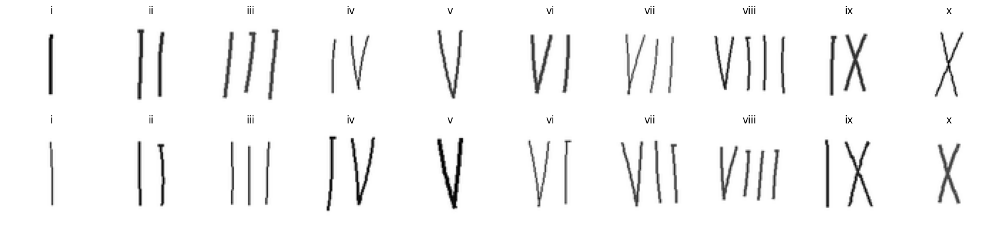

In [ ]:
# V4.2 — Không gian dữ liệu định trước; không nhìn label_book.
def synthetic_roman_v4(label, rng):
    # Các ký tự và thứ tự phải đúng nhãn; mỗi nét là đường cong nhẹ ngẫu nhiên.
    text = label.upper()
    widths = [13 if c == 'I' else 27 for c in text]
    gap = float(rng.uniform(7, 13))
    width = sum(widths) + gap * (len(text) - 1)
    canvas = Image.new('L', (192, 128), 255)
    draw = ImageDraw.Draw(canvas)
    pen = int(rng.integers(2, 5))
    ink = int(rng.integers(0, 80))
    slant = float(rng.uniform(-0.10, 0.10))
    def stroke(start, end):
        x0, y0 = start
        x1, y1 = end
        bend = float(rng.uniform(-2, 2))
        points = []
        for t in np.linspace(0, 1, 25):
            xx = x0 + (x1-x0)*t + bend*np.sin(np.pi*t)
            yy = y0 + (y1-y0)*t
            points.append((float(xx + slant*(yy-64)), float(yy)))
        draw.line(points, fill=ink, width=pen, joint='curve')
    cursor = (192-width)/2
    for char, char_width in zip(text, widths):
        top, bottom = float(rng.uniform(24, 32)), float(rng.uniform(96, 104))
        left, right = cursor+2, cursor+char_width-2
        if char == 'I':
            mid = (left+right)/2
            stroke((mid+rng.uniform(-2, 2), top), (mid+rng.uniform(-2, 2), bottom))
            if rng.random() < .25:
                stroke((mid-3, top), (mid+3, top))
        elif char == 'V':
            mid = (left+right)/2 + rng.uniform(-2, 2)
            stroke((left, top), (mid, bottom))
            stroke((mid, bottom), (right, top+rng.uniform(-2, 2)))
        elif char == 'X':
            stroke((left, top), (right, bottom))
            stroke((right, top), (left, bottom))
        else:
            raise ValueError(label)
        cursor += char_width + gap
    return crop_and_center_digit(canvas, output_size=(64, 64),
                                 padding_ratio=float(rng.uniform(.10, .30)))

def image_aug_v4(image, rng, padding=False, photo=False):
    if padding:
        image = crop_and_center_digit(clean_and_binarize_image(image), (64, 64),
                                     padding_ratio=float(rng.uniform(.08, .34)))
    result = augment_mixed_v3(image, rng)
    if photo:
        result = ImageEnhance.Brightness(result).enhance(float(rng.uniform(.90, 1.04)))
        if rng.random() < .35:
            result = result.filter(ImageFilter.GaussianBlur(float(rng.uniform(.1, .45))))
        arr = np.asarray(result, dtype=float)
        arr = np.clip(arr + rng.normal(0, rng.uniform(0, 2), arr.shape), 0, 255)
        result = Image.fromarray(arr.astype(np.uint8))
    return result

def specs_v4(max_train):
    return [
        dict(name='v3_control', control=True, total=8000),
        dict(name='raw85', total=8000, raw_prob=.85),
        dict(name='variable_padding', total=8000, raw_prob=.60, padding=True),
        dict(name='photo_mild', total=8000, raw_prob=.75, photo=True),
        dict(name='synthetic08', total=8000, raw_prob=.60, synthetic=.08),
        dict(name='synthetic16', total=8000, raw_prob=.60, synthetic=.16),
        dict(name='max_budget', total=max_train, raw_prob=.65, padding=True),
        dict(name='max_mixed_synthetic08', total=max_train, raw_prob=.75,
             padding=True, photo=True, synthetic=.08),
    ]

# Preview để xem tính hợp lý của nhãn trước khi chạy.
preview_rng_v4 = np.random.default_rng(4123)
fig, axes = plt.subplots(2, 10, figsize=(17, 4))
for col, cls in enumerate(CLASSES):
    for row in range(2):
        axes[row, col].imshow(synthetic_roman_v4(cls, preview_rng_v4), cmap='gray', vmin=0, vmax=255)
        axes[row, col].set_title(cls)
        axes[row, col].axis('off')
plt.tight_layout()
plt.show()


In [ ]:
# V4.3 — Dựng dữ liệu, kiểm toán nguồn, cấu hình và phiên bản.
def build_data_v4(spec, reference, destination, deadline):
    destination = Path(destination)
    manifest_path = destination.parent / 'manifest.json'
    previous = read_v4(manifest_path)
    if previous is not None:
        if previous['spec'] != spec:
            raise ValueError('Không ghi đè dataset bằng cấu hình khác')
        if len(list(destination.rglob('*.png'))) != previous['total']:
            raise ValueError('Dataset lưu trước đó thiếu ảnh; khôi phục dataset hoặc dùng campaign mới')
        for p, y in zip(val_paths_raw, val_labels_raw):
            exported = destination / 'val' / CLASSES[y] / Path(p).name
            if exported.read_bytes() != Path(p).read_bytes():
                raise ValueError('Validation trong dataset cache đã thay đổi')
        return destination
    # Dựng vào staging riêng. Chỉ công bố dataset sau khi mọi kiểm tra thành công.
    destination.parent.mkdir(parents=True, exist_ok=True)
    staging = Path(tempfile.mkdtemp(prefix='building_', dir=destination.parent))
    rng = np.random.default_rng(4123)
    records, seen = [], set()
    val_keys = {pixel_hash(p) for p in val_paths_raw}
    try:
        if spec.get('control'):
            for file in sorted(Path(reference['dataset']).rglob('*.png')):
                check_time_v4(deadline)
                relative = file.relative_to(reference['dataset'])
                target = staging / relative
                target.parent.mkdir(parents=True, exist_ok=True)
                shutil.copy2(file, target)
                records.append(dict(file=relative.as_posix(), source=str(file),
                                    transform='v3_control_copy', split=relative.parts[0],
                                    pixel_hash=pixel_hash(file)))
        else:
            quotas = allocate_budget_v3(reference['metrics']['confusion_matrix'], spec['total'])
            for cls in CLASSES:
                (staging / 'train' / cls).mkdir(parents=True)
                (staging / 'val' / cls).mkdir(parents=True)
            for source, label in zip(val_paths_raw, val_labels_raw):
                target = staging / 'val' / CLASSES[label] / Path(source).name
                shutil.copy2(source, target)
                records.append(dict(file=target.relative_to(staging).as_posix(), source=str(source),
                                    transform='raw', split='val', pixel_hash=pixel_hash(source)))
            for label, cls in enumerate(CLASSES):
                check_time_v4(deadline)
                count = 0
                pool = []
                synth_target = int(round(quotas[cls] * spec.get('synthetic', 0)))
                real_target = quotas[cls] - synth_target
                def save(image, source, transform):
                    nonlocal count
                    image = image.convert('RGB')
                    key = hashlib.sha256(str(image.size).encode()+image.tobytes()).hexdigest()
                    if key in seen or key in val_keys: return False
                    target = staging / 'train' / cls / f'{count:05d}.png'
                    image.save(target)
                    records.append(dict(file=target.relative_to(staging).as_posix(), source=str(source),
                                        transform=transform, split='train', pixel_hash=key))
                    seen.add(key)
                    count += 1
                    return True
                for source, y in zip(train_paths_raw, train_labels_raw):
                    if y != label: continue
                    check_time_v4(deadline)
                    with Image.open(source) as im:
                        raw = im.convert('L')
                        centered = crop_and_center_digit(clean_and_binarize_image(im))
                        save(im, source, 'raw')
                    pool.append((source, raw, centered))
                for source, raw, centered in pool:
                    save(centered, source, 'center')
                if not pool or count > real_target:
                    raise ValueError(f'Budget không đủ giữ raw+centered: {cls}')
                attempts = 0
                source_order = rng.permutation(len(pool))
                while count < real_target and attempts < real_target * 50:
                    check_time_v4(deadline)
                    if attempts and attempts % len(pool) == 0:
                        source_order = rng.permutation(len(pool))
                    source, raw, centered = pool[int(source_order[attempts % len(pool)])]
                    raw_branch = rng.random() < spec.get('raw_prob', .6)
                    base = raw if raw_branch else centered
                    save(image_aug_v4(base, rng, spec.get('padding', False), spec.get('photo', False)),
                         source, 'raw_aug' if raw_branch else 'center_aug')
                    attempts += 1
                if count != real_target:
                    raise ValueError(f'Không đủ biến thể thật duy nhất: {cls}')
                attempts = 0
                while count < quotas[cls] and attempts < synth_target * 20:
                    check_time_v4(deadline)
                    sample = synthetic_roman_v4(cls, rng)
                    save(image_aug_v4(sample, rng), f'synthetic/{cls}/{attempts}', 'synthetic_strokes')
                    attempts += 1
                if count != quotas[cls]:
                    raise ValueError(f'Không đủ biến thể tổng hợp: {cls}')
        train_records = [r for r in records if r['split'] == 'train']
        val_records = [r for r in records if r['split'] == 'val']
        assert len(train_records) == spec['total']
        assert len(val_records) == len(val_paths_raw)
        assert not ({r['pixel_hash'] for r in train_records} & {r['pixel_hash'] for r in val_records})
        # So cả bytes lẫn nhãn validation, kể cả dataset V3 đối chứng được copy.
        for p, y in zip(val_paths_raw, val_labels_raw):
            assert (staging / 'val' / CLASSES[y] / Path(p).name).read_bytes() == Path(p).read_bytes()
        assert len(records) < 10000
        rounded = (math.ceil(len(train_records)/8)+math.ceil(len(val_records)/8))*8
        assert rounded <= 10000
        if destination.exists():
            raise FileExistsError('Không ghi đè dataset đã tồn tại')
        staging.replace(destination)
        json_v4(manifest_path, dict(spec=spec, total=len(records), evaluator_count=rounded, images=records))
        event_v4('dataset_ready', variant=spec['name'], train=len(train_records), val=len(val_records))
    except BaseException:
        # Chỉ xóa staging do chính hàm tạo; không xóa dataset nguồn hoặc run cũ.
        if staging.exists(): shutil.rmtree(staging)
        raise
    return destination

def init_campaign_v4():
    train_fingerprint = [(CLASSES[y], pixel_hash(p)) for p, y in zip(train_paths_raw, train_labels_raw)]
    validation_fingerprint = [(CLASSES[y], pixel_hash(p)) for p, y in zip(val_paths_raw, val_labels_raw)]
    train_keys = {key for label, key in train_fingerprint}
    val_keys = {key for label, key in validation_fingerprint}
    assert not train_keys & val_keys
    max_train = (10000 // 8 - math.ceil(len(val_paths_raw)/8)) * 8
    while max_train + len(val_paths_raw) >= 10000:
        max_train -= 8
    specs = specs_v4(max_train)
    settings = dict(engine_version=1, full_epochs=V4_FULL_EPOCHS,
                    screen_epochs=V4_SCREEN_EPOCHS, lr=V4_LR, batch=V4_BATCH_SIZE,
                    seeds=V4_SEEDS, top_k=V4_TOP_K, specs=specs,
                    train_fingerprint=train_fingerprint, validation_fingerprint=validation_fingerprint)
    signature = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()
    metadata_path = V4_CAMPAIGN_DIR / 'campaign.json'
    previous = read_v4(metadata_path)
    if previous:
        if previous['signature'] != signature:
            raise ValueError('Data/cấu hình khác campaign cũ. Đổi V4_CAMPAIGN_DIR để giữ lịch sử.')
        return previous, specs
    original = globals().get('V4_CONTROL_DATA_DIR', globals().get('V3_DATA_DIR'))
    reference_metrics = globals().get('V4_REFERENCE_METRICS', globals().get('v3_val_metrics'))
    # Cho phép runtime mới dùng lại dataset/metrics V3 đã lưu, không train lại V3.
    if original is None:
        roots = {Path(globals().get('HISTORY_ROOT', COMP_DIR/'optimization_history')),
                 V4_CAMPAIGN_DIR.parent}
        saved = [p for root in roots for p in root.glob('*/v3_validation.json')
                 if (p.parent/'dataset/train').is_dir()]
        if saved:
            latest = max(saved, key=lambda p: p.stat().st_mtime)
            original = latest.parent/'dataset'
            if reference_metrics is None: reference_metrics = read_v4(latest)
            print('Dùng dataset V3 đã lưu:', original)
    if original is not None and reference_metrics is None:
        reference_metrics = read_v4(Path(original).parent/'v3_validation.json')
    if original is None or reference_metrics is None:
        raise RuntimeError('Cần dataset V3 và metrics: chạy sau V3, hoặc đặt V4_CONTROL_DATA_DIR + V4_REFERENCE_METRICS.')
    original = Path(original).resolve()
    if len(list((original / 'train').rglob('*.png'))) != 8000:
        raise ValueError('Đối chứng cần đúng dataset V3 8000 train')
    meta = dict(signature=signature, settings=settings,
                reference=dict(dataset=str(original), metrics=reference_metrics),
                reported_previous_run=dict(provenance='user_reported',
                    val_accuracy=.8942, val_macro_f1=.8933, label_book_accuracy=.7885))
    json_v4(metadata_path, meta)
    event_v4('campaign_created', signature=signature)
    return meta, specs


In [ ]:
# V4.4 — Train/resume từng trial; kiến trúc và cấu hình học giữ cố định.
def trial_v4(spec, dataset, seed, target_epochs, deadline):
    folder = V4_CAMPAIGN_DIR / spec['name'] / f'seed_{seed}'
    folder.mkdir(parents=True, exist_ok=True)
    old = read_v4(folder / 'progress.json', {})
    if old.get('completed_epochs', 0) >= target_epochs:
        result = read_v4(folder / f'result_{target_epochs}.json')
        if result is not None: return result
        raise RuntimeError('Thiếu result sau completed epoch; dùng campaign mới hoặc khôi phục file')
    check_time_v4(deadline)
    paths, labels = collect_paths_and_labels(Path(dataset) / 'train')
    tf.random.set_seed(seed)
    np.random.seed(seed)
    model = PureVGG16(num_classes=NUM_CLASSES, fc_dim=512)
    optimizer = PureAdamOptimizer(model.trainable_variables, lr=V4_LR)
    epoch_state = tf.Variable(0, trainable=False, dtype=tf.int64)
    state = dict(model=model, epoch=epoch_state, adam_t=optimizer.step_t)
    state.update({f'adam_m_{i}': var for i, var in enumerate(optimizer.m)})
    state.update({f'adam_v_{i}': var for i, var in enumerate(optimizer.v)})
    checkpoint = tf.train.Checkpoint(**state)
    manager = tf.train.CheckpointManager(checkpoint, str(folder / 'resume'), max_to_keep=2)
    history = old.get('history', [])
    best = old.get('best')
    start_epoch = 0
    if manager.latest_checkpoint:
        checkpoint.restore(manager.latest_checkpoint).assert_existing_objects_matched()
        start_epoch = int(epoch_state.numpy())
        if start_epoch != old.get('completed_epochs', -1):
            raise RuntimeError('Checkpoint/progress không cùng epoch; khôi phục bản sao trước')
    elif old:
        raise RuntimeError('Có progress nhưng thiếu resume checkpoint; không train đè kết quả')

    @tf.function(reduce_retracing=True)
    def step(x, y):
        return pure_train_step(model, optimizer, x, y, dropout_rate=.4)

    # Giải mã/cache một lần; seed của shuffle được xác định theo epoch cho resume.
    base = tf.data.Dataset.from_tensor_slices((paths, labels))
    base = base.map(parse_image_and_label, num_parallel_calls=tf.data.AUTOTUNE).cache()
    start_time = time.monotonic()
    try:
        for epoch in range(start_epoch + 1, target_epochs + 1):
            check_time_v4(deadline)
            epoch_start = time.monotonic()
            ds = base.shuffle(len(paths), seed=seed+epoch, reshuffle_each_iteration=False)
            ds = ds.batch(V4_BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
            n, loss_sum, acc_sum = 0, 0.0, 0.0
            for x, y in ds:
                check_time_v4(deadline)
                loss, acc = step(x, y)
                size = int(tf.shape(y)[0])
                loss_sum += float(loss) * size
                acc_sum += float(acc) * size
                n += size
            check_time_v4(deadline)
            metrics = evaluate_v4(model, ds_val_baseline)
            if not n or not np.isfinite([loss_sum, acc_sum]).all():
                raise FloatingPointError('Train metrics không hợp lệ')
            if best is None or metrics['accuracy'] > best['metrics']['accuracy']:
                best = dict(epoch=epoch, metrics=metrics)
                save_best_v4(model, folder / 'best.npz')
            history.append(dict(epoch=epoch, train_loss=loss_sum/n, train_accuracy=acc_sum/n,
                                validation=metrics, seconds=time.monotonic()-epoch_start))
            epoch_state.assign(epoch)
            manager.save(checkpoint_number=epoch)
            json_v4(folder / 'progress.json', dict(completed_epochs=epoch, history=history,
                    best=best, resumed=start_epoch > 0))
            # Giữ checkpoint riêng của từng fidelity, tránh best ở epoch 15 ghi
            # đè artifact được ghi trong kết quả sàng lọc epoch 4.
            if epoch in {V4_SCREEN_EPOCHS, V4_FULL_EPOCHS, target_epochs}:
                snapshot = folder / f'best_at_{epoch}.npz'
                shutil.copy2(folder / 'best.npz', snapshot)
                result = dict(variant=spec['name'], seed=seed, epochs=epoch, best=best,
                              checkpoint=str(snapshot), dataset=str(dataset),
                              resumed=start_epoch > 0)
                json_v4(folder / f'result_{epoch}.json', result)
            event_v4('epoch_completed', variant=spec['name'], seed=seed, epoch=epoch,
                     validation_accuracy=metrics['accuracy'])
            print(f"{spec['name']} seed={seed} epoch={epoch}/{target_epochs}: "
                  f"val={metrics['accuracy']:.4f}, F1={metrics['macro_f1']:.4f}, "
                  f"seconds={history[-1]['seconds']:.1f}", flush=True)
            if epoch == 1:
                print('Ước tính cho 15 epoch sau khi đã đo 1 epoch (chưa tính I/O/model khác):',
                      round(history[-1]['seconds']*V4_FULL_EPOCHS/60, 1), 'phút', flush=True)
        return read_v4(folder / f'result_{target_epochs}.json')
    except BaseException as error:
        event_v4('trial_interrupted', variant=spec['name'], seed=seed,
                 completed_epochs=len(history), error_type=type(error).__name__)
        raise
    finally:
        # Không xóa model/checkpoint của V2/V3 đang mở trong notebook.
        del step, model, optimizer, checkpoint, manager, state, base
        gc.collect()

def choose_confirmed_v4(control, candidates, min_gain):
    # Cùng các seed cho đối chứng và ứng viên: so sánh ghép cặp.
    eligible = []
    for name, rows in candidates.items():
        if [r['seed'] for r in rows] != [c['seed'] for c in control]:
            raise ValueError('Seed ứng viên và đối chứng không khớp thứ tự')
        gains = [r['best']['metrics']['accuracy'] - c['best']['metrics']['accuracy']
                 for r, c in zip(rows, control)]
        if len(rows) != 3 or len(control) != 3:
            raise ValueError('Chưa đủ 3 seed để chốt lựa chọn')
        average = float(np.mean([r['best']['metrics']['accuracy'] for r in rows]))
        if np.mean(gains) >= min_gain and sum(g > 0 for g in gains) >= 2:
            eligible.append((average, float(np.mean([r['best']['metrics']['macro_f1'] for r in rows])), name))
    return max(eligible)[2] if eligible else 'v3_control'


In [ ]:
# V4.5 — Chạy cell này lại để tiếp tục; không train lại trial đã hoàn tất.
def run_campaign_v4():
    if not tf.config.list_physical_devices('GPU') and not globals().get('V4_ALLOW_CPU', False):
        print('Chọn Runtime → Change runtime type → T4 GPU. Chưa bắt đầu train.')
        return dict(status='gpu_required')
    deadline = time.monotonic() + V4_SESSION_MINUTES * 60
    meta, specs = init_campaign_v4()
    by_name = {s['name']: s for s in specs}
    reference = meta['reference']
    try:
        screened = []
        for spec in specs:
            check_time_v4(deadline)
            dataset = build_data_v4(spec, reference, V4_CAMPAIGN_DIR/spec['name']/'dataset', deadline)
            result = trial_v4(spec, dataset, V4_SEEDS[0], V4_SCREEN_EPOCHS, deadline)
            screened.append(result)
            json_v4(V4_CAMPAIGN_DIR/'screening.json', screened)
        ranked = sorted((r for r in screened if r['variant'] != 'v3_control'),
                        key=lambda r: rank_v4(r['best']['metrics']), reverse=True)
        finalists = ['v3_control'] + [r['variant'] for r in ranked[:V4_TOP_K]]
        json_v4(V4_CAMPAIGN_DIR/'finalists.json', dict(variants=finalists,
                  criterion='best validation accuracy at screening fidelity'))
        full = []
        for name in finalists:
            result = trial_v4(by_name[name], V4_CAMPAIGN_DIR/name/'dataset',
                              V4_SEEDS[0], V4_FULL_EPOCHS, deadline)
            full.append(result)
        # Chỉ ứng viên tốt nhất ở fidelity đầy đủ đi tiếp; đối chứng luôn có đủ epoch.
        candidate = max((r for r in full if r['variant'] != 'v3_control'),
                        key=lambda r: rank_v4(r['best']['metrics']))['variant']
        confirmed = {}
        for name in ['v3_control', candidate]:
            confirmed[name] = []
            for seed in V4_SEEDS:
                row = trial_v4(by_name[name], V4_CAMPAIGN_DIR/name/'dataset',
                               seed, V4_FULL_EPOCHS, deadline)
                confirmed[name].append(row)
        selected = choose_confirmed_v4(confirmed['v3_control'],
                    {candidate: confirmed[candidate]}, min_gain=2/len(val_paths_raw))
        summary = dict(status='search_space_completed', selected=selected,
                       candidate=candidate, confirmed=confirmed, screen_epochs=V4_SCREEN_EPOCHS,
                       full_epochs=V4_FULL_EPOCHS, seeds=V4_SEEDS,
                       scope='predefined 8 configs, successive halving; not a global optimum',
                       selection_rule='paired 3-seed mean gain >= 2/val_count and wins >= 2/3 seeds')
        json_v4(V4_CAMPAIGN_DIR/'selection.json', summary)
        json_v4(V4_CAMPAIGN_DIR/'session_status.json', dict(
            status='search_space_completed', selected=selected))
        event_v4('search_space_completed', selected=selected)
        print('Hoàn tất không gian ứng viên đã định trước; chọn:', selected)
        return summary
    except BudgetExhaustedV4 as error:
        status = dict(status='budget_exhausted', message=str(error),
                      next_action='Chạy lại V4.5; giữ nguyên V4_CAMPAIGN_DIR và cấu hình.')
        json_v4(V4_CAMPAIGN_DIR/'session_status.json', status)
        event_v4('budget_exhausted')
        print(status['message'])
        return status

v4_search_status = run_campaign_v4()
print('Trạng thái:', v4_search_status['status'])


Hoàn tất không gian ứng viên đã định trước; chọn: v3_control
Trạng thái: search_space_completed


In [ ]:
# V4.6 — Xem tiến độ mọi trial và đánh giá lựa chọn cuối đúng một lần.
print(f"{'Variant':<27} {'Seed':>5} {'Epochs':>7} {'Val acc':>9} {'Macro-F1':>9}")
for file in sorted(V4_CAMPAIGN_DIR.glob('*/seed_*/progress.json')):
    row = read_v4(file)
    metric = row['best']['metrics']
    print(f"{file.parent.parent.name:<27} {file.parent.name[5:]:>5} "
          f"{row['completed_epochs']:>7} {metric['accuracy']:>9.4f} {metric['macro_f1']:>9.4f}")

def report_final_v4():
    selection = read_v4(V4_CAMPAIGN_DIR/'selection.json')
    if not selection or selection['status'] != 'search_space_completed':
        print('Chưa chốt: chưa đủ sàng lọc/full training/3 seed. Chạy tiếp V4.5 khi có GPU.')
        return None
    selected = selection['selected']
    confirmed = selection['confirmed']
    print('Lựa chọn theo validation:', selected)
    for name, trials in confirmed.items():
        values = np.array([r['best']['metrics']['accuracy'] for r in trials])
        print(name, 'mean val accuracy:', round(float(values.mean()), 4),
              '| std:', round(float(values.std(ddof=1)), 4), '| seeds:', selection['seeds'])
    if (V4_CAMPAIGN_DIR/'final_report.json').exists():
        print('Đã đánh giá label_book cho lựa chọn này; đọc kết quả đã lưu.')
        return read_v4(V4_CAMPAIGN_DIR/'final_report.json')
    # Dùng seed 123 đã định trước, không chọn seed/model theo label_book, không ensemble.
    chosen = next(r for r in confirmed[selected] if r['seed'] == V4_SEEDS[0])
    model = PureVGG16(num_classes=NUM_CLASSES, fc_dim=512)
    PureModelWeightsSaver.load_weights(model, chosen['checkpoint'])
    test = evaluate_v4(model, ds_test_baseline)
    del model
    gc.collect()
    archive = V4_CAMPAIGN_DIR/'selected_dataset.zip'
    with zipfile.ZipFile(archive, 'w', compression=zipfile.ZIP_DEFLATED) as stream:
        for image in sorted(Path(chosen['dataset']).rglob('*.png')):
            stream.write(image, image.relative_to(chosen['dataset']).as_posix())
    report = dict(selected=selected, deployment_seed=V4_SEEDS[0],
                  label_book=test, label_book_count=len(test_paths_raw),
                  checkpoint=chosen['checkpoint'], dataset_zip=str(archive),
                  conclusion='Chỉ hết không gian tìm kiếm định trước; không chứng minh không thể cải thiện thêm.')
    json_v4(V4_CAMPAIGN_DIR/'final_report.json', report)
    event_v4('label_book_reported_once', selected=selected, accuracy=test['accuracy'])
    print('Label_book:', round(test['accuracy']*100, 2), '% | Dataset:', archive)
    return report

v4_final_report = report_final_v4()


Variant                      Seed  Epochs   Val acc  Macro-F1
max_budget                    123       4    0.5683    0.5367
max_mixed_synthetic08         123       4    0.5597    0.5392
photo_mild                    123       4    0.6298    0.6215
raw85                         123       4    0.6556    0.6350
synthetic08                   123      15    0.8536    0.8538
synthetic16                   123      15    0.8684    0.8692
v3_control                    123      15    0.8930    0.8923
v3_control                    456      15    0.8635    0.8638
v3_control                    789      15    0.8733    0.8735
variable_padding              123      15    0.8708    0.8701
variable_padding              456      15    0.8610    0.8605
variable_padding              789      15    0.8401    0.8384
Lựa chọn theo validation: v3_control
v3_control mean val accuracy: 0.8766 | std: 0.015 | seeds: [123, 456, 789]
variable_padding mean val accuracy: 0.8573 | std: 0.0157 | seeds: [123, 456, 789]


### Trạng thái V4 theo output đang lưu

Engine đã `search_space_completed`, chọn **`v3_control`**. Mean validation
**87,66%** là trung bình ba model. Model seed 123 có
validation **89,30%**, macro-F1 **0,8923**.
Label_book trong cell báo cáo hiện tại: **Không in lại — đọc cache**.

Không đồng nhất model V4 đã lưu với V3 vừa train ở phần 6. Bốn cấu hình
khác bị loại sau 4 epoch, chưa có đánh giá đủ 15 epoch cho chúng. Resume
giữ model/Adam/epoch nhưng RNG dropout không khôi phục bit-for-bit, nên
không bảo đảm mọi lần train lại cho cùng kết quả. Đây không phải tối ưu toàn cục.


### FINAL cell: fresh runtime

The FINAL cell now uses complete V3 artifacts available on the current validation split,
or the folder specified by `FINAL_V3_SOURCE_DIR`. It rechecks the checkpoint and exports
its actual metrics. The 89.42% report below describes a historical run only.
Complete V3.1 through V3.5 or restore the run folder from Drive before exporting.
This cell exports V3 only; review `selection.json` if the run selected V2 instead.

## PHẦN 8 — Kết quả chốt đúng với output cell cuối

**Gói thực tế đã xuất:** V3 lịch sử run **`20261109T054449Z_3adedb09`**, best epoch
**6**. Cell cuối đã nạp checkpoint và xác minh lại validation:
**727/813 = 89,42%**, macro-F1
**0,8933**, loss **0.4175105**.

### Mỗi dòng là một lần đánh giá riêng

| Giai đoạn / checkpoint | Val accuracy | Val macro-F1 | Label_book |
|---|---:|---:|---|
| Baseline — phần 3 hiện tại | 64,21% | 0,6127 | 65,38% |
| V2 — phần 5 hiện tại | 84,01% | 0,8402 | 73,08% |
| V3 — phần 6 hiện tại, `20261109T080842Z_47bed10a` | 77,49% | 0,7716 | 67,31% |
| V4 `v3_control` seed 123 — campaign đã lưu | 89,30% | 0,8923 | Không in lại — đọc cache |
| **Checkpoint lịch sử cell cuối đã xác minh/xuất** | **89,42%** | **0,8933** | **78,85% — điểm lịch sử** |

Phần 6 hiện tại chọn **V2**, không phải V3. Không gắn số cao hơn của
run lịch sử vào model vừa train. Label_book 78,85% của gói cuối
là kết quả **đã lưu từ run lịch sử**, không được đo lại khi đóng gói.
Validation 89,42% của gói cuối đã được đo lại thành công.

### Kết luận riêng của engine V4

| Phương án | Seed 123 | Seed 456 | Seed 789 | Mean val accuracy | Std |
|---|---:|---:|---:|---:|---:|
| `v3_control` | 89,30% | 86,35% | 87,33% | 87,66% | 1.50 điểm % |
| `variable_padding` | 87,08% | 86,10% | 84,01% | 85,73% | 1.57 điểm % |

Engine V4 chọn **`v3_control`** theo validation nhiều seed. Các số này thuộc
campaign đã lưu, không chứng minh riêng run `20261109T054449Z_3adedb09` đã được kiểm chứng
trên 3 seed. Sau V4, cell cuối đưa ra quyết định riêng: lấy run lịch sử có
validation cao nhất trong các run V3 đã lưu và kiểm tra lại trước khi xuất.
Artifact này khác `v4_t4/selected_dataset.zip` do engine V4 trực tiếp chọn.
Không gộp hai quyết định hoặc hai bộ số liệu thành một kết quả.

### Artifact được output cell cuối xác nhận

Thư mục **`final_v3_mk338p4h/`** trong `optimization_history/` trên Colab:

* `submission_final.zip`: dataset đi cùng run lịch sử, 8.000 train + 813 val.
* `best_weights.npz`: checkpoint epoch 6 của chính run đó.
* `decision.json`: nguồn artifact, metrics xác minh và SHA-256.

Đường dẫn dataset đã xuất: `/content/deeplearningai-data-centric-competition/optimization_history/final_v3_mk338p4h/submission_final.zip`.

Giữ artifact cùng hồ sơ quyết định. Không đổi sang dataset V4 rồi giữ số
điểm lịch sử. Chọn nhiều lần trên cùng validation có thể overfit; label_book
không phải hidden test chính thức. Chưa chứng minh đạt tối ưu toàn cục.
Các bảng markdown này được trích từ output notebook đang lưu; code và
output đã chạy được giữ nguyên hoàn toàn.


In [ ]:
# FINAL — Xác minh và đóng gói đúng run V3 đã chốt, không huấn luyện lại.
import io
from collections import Counter

# Use an explicit Drive run folder, or the best complete V3 run available on this split.
FINAL_HISTORY_ROOT = Path(globals().get('HISTORY_ROOT', COMP_DIR/'optimization_history'))
final_required_files = ['v3_best_weights.npz', 'dataset.zip', 'v3_validation.json', 'results.json', 'config.json']
final_fingerprint = hashlib.sha256(json.dumps(
    [(CLASSES[y], pixel_hash(p)) for p,y in zip(val_paths_raw, val_labels_raw)],
    separators=(',', ':')).encode()).hexdigest()

def resolve_final_v3(history_root, fingerprint, explicit_source=None):
    candidates = [Path(explicit_source)] if explicit_source is not None else sorted(Path(history_root).glob('*'))
    eligible, skipped = [], []
    for folder in candidates:
        if not folder.is_dir():
            skipped.append(f'{folder}: folder not found')
            continue
        missing = [name for name in final_required_files if not (folder/name).is_file()]
        if missing:
            skipped.append(f'{folder.name}: missing {missing}')
            continue
        try:
            record = json.loads((folder/'results.json').read_text(encoding='utf-8'))
            metrics = json.loads((folder/'v3_validation.json').read_text(encoding='utf-8'))
            if record.get('validation_fingerprint') != fingerprint:
                skipped.append(f'{folder.name}: different validation split')
                continue
            acc, f1, loss = (float(metrics[k]) for k in ['accuracy', 'macro_f1', 'loss'])
            if not all(math.isfinite(v) for v in (acc, f1, loss)):
                raise ValueError('non-finite metrics')
            eligible.append(((acc, f1, -loss), folder))
        except (ValueError, KeyError, TypeError) as error:
            skipped.append(f'{folder.name}: invalid metadata ({error})')
    if not eligible:
        raise FileNotFoundError(
            'No complete V3 run on this validation split. Complete V3.1 through V3.5, '
            'or restore your saved run from Drive and set FINAL_V3_SOURCE_DIR. '
            'Saved notebook outputs do not contain checkpoint files. Details: ' + '; '.join(skipped))
    return max(eligible, key=lambda item: item[0])[1]

FINAL_SOURCE_DIR = resolve_final_v3(
    FINAL_HISTORY_ROOT, final_fingerprint, globals().get('FINAL_V3_SOURCE_DIR'))
final_stored_metrics = read_v4(FINAL_SOURCE_DIR/'v3_validation.json')
final_run_record = read_v4(FINAL_SOURCE_DIR/'results.json')
final_config = read_v4(FINAL_SOURCE_DIR/'config.json')
FINAL_RUN_ID = final_run_record['run_id']
assert final_config['model'] == 'PureVGG16' and final_config['fc_dim'] == 512
final_training_status = read_v4(FINAL_SOURCE_DIR/'training_status.json', {})
final_best_epoch = final_training_status.get('best_epoch')
if final_best_epoch is None and (FINAL_SOURCE_DIR/'curves.json').is_file():
    final_curve = read_v4(FINAL_SOURCE_DIR/'curves.json')['val_acc']
    final_best_epoch = int(np.argmax(final_curve)) + 1 if final_curve else None
print('Selected available V3 run:', FINAL_RUN_ID)
print('Stored validation:', final_stored_metrics)
if final_run_record.get('selected_by_validation') == 'V2':
    print('WARNING: this run selected V2 over V3. This cell exports V3 only; review selection.json before submission.')

# Kiểm tra từng ảnh trong ZIP, đúng nhãn/thư mục, unique pixel và validation nguyên byte.
final_expected_val = {
    f'val/{CLASSES[y]}/{Path(p).name}': Path(p) for p,y in zip(val_paths_raw, val_labels_raw)}
final_train_hashes, final_val_hashes = set(), set()
final_counts = Counter()
with zipfile.ZipFile(FINAL_SOURCE_DIR/'dataset.zip') as final_zip:
    names = final_zip.namelist()
    if len(names) != len(set(names)):
        raise ValueError('ZIP chứa tên file lặp')
    observed_val = set()
    for name in names:
        parts = name.split('/')
        if len(parts) != 3 or parts[0] not in ['train','val'] or parts[1] not in CLASSES or not parts[2].endswith('.png'):
            raise ValueError(f'Cấu trúc ZIP không hợp lệ: {name}')
        content = final_zip.read(name)
        with Image.open(io.BytesIO(content)) as image:
            rgb = image.convert('RGB')
            key = hashlib.sha256(str(rgb.size).encode()+rgb.tobytes()).hexdigest()
        final_counts[(parts[0],parts[1])] += 1
        if parts[0] == 'train':
            if key in final_train_hashes:
                raise ValueError(f'Train có ảnh trùng pixel: {name}')
            final_train_hashes.add(key)
        else:
            if name not in final_expected_val or content != final_expected_val[name].read_bytes():
                raise ValueError(f'Validation thay đổi: {name}')
            observed_val.add(name)
            final_val_hashes.add(key)
    assert observed_val == set(final_expected_val)
assert not final_train_hashes & final_val_hashes
final_n_train = sum(n for (split,cls),n in final_counts.items() if split == 'train')
final_n_val = sum(n for (split,cls),n in final_counts.items() if split == 'val')
assert final_n_train == sum(final_config['targets'].values())
assert final_n_val == len(val_paths_raw)
assert {cls: final_counts[('train',cls)] for cls in CLASSES} == final_config['targets']
final_rounded = (math.ceil(final_n_train/8)+math.ceil(final_n_val/8))*8
assert final_n_train+final_n_val < 10000 and final_rounded <= 10000

final_model = PureVGG16(num_classes=NUM_CLASSES, fc_dim=512)
PureModelWeightsSaver.load_weights(final_model, str(FINAL_SOURCE_DIR/'v3_best_weights.npz'))
final_rechecked_metrics = evaluate_v4(final_model, ds_val_baseline)
if (not np.isclose(final_rechecked_metrics['accuracy'], final_stored_metrics['accuracy'], atol=1e-6)
    or final_rechecked_metrics['confusion_matrix'] != final_stored_metrics['confusion_matrix']):
    raise ValueError(f'Không tái lập được validation của checkpoint: {final_rechecked_metrics}')
del final_model
gc.collect()

def final_file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024*1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

FINAL_HISTORY_ROOT.mkdir(parents=True, exist_ok=True)
FINAL_OUTPUT_DIR = Path(tempfile.mkdtemp(prefix='final_v3_', dir=FINAL_HISTORY_ROOT))
shutil.copy2(FINAL_SOURCE_DIR/'dataset.zip', FINAL_OUTPUT_DIR/'submission_final.zip')
shutil.copy2(FINAL_SOURCE_DIR/'v3_best_weights.npz', FINAL_OUTPUT_DIR/'best_weights.npz')
for name in ['config.json','v3_validation.json','results.json','manifest.json']:
    if (FINAL_SOURCE_DIR/name).exists():
        shutil.copy2(FINAL_SOURCE_DIR/name, FINAL_OUTPUT_DIR/name)
final_decision = dict(
    strategy='V3', source_run=FINAL_RUN_ID, source_dir=str(FINAL_SOURCE_DIR),
    chosen_by='explicit V3 source or best complete available V3 on same split; artifacts rechecked',
    validation=final_rechecked_metrics, best_epoch=final_best_epoch, deployment_seed=final_config['seed'],
    historical_label_book_accuracy=final_run_record['v3_label_book_accuracy'],
    label_book_re_evaluated=False, train=final_n_train, val=final_n_val,
    evaluator_count=final_rounded,
    dataset_sha256=final_file_sha256(FINAL_OUTPUT_DIR/'submission_final.zip'),
    checkpoint_sha256=final_file_sha256(FINAL_OUTPUT_DIR/'best_weights.npz'),
    caveat='V3 export only; historical scores and V4 multi-seed results do not apply to this run.')
json_v4(FINAL_OUTPUT_DIR/'decision.json', final_decision)
print('CHỐT: V3 — run', FINAL_RUN_ID, '| best epoch', final_best_epoch)
print('Validation xác minh lại:', final_rechecked_metrics)
print('Dataset nộp:', FINAL_OUTPUT_DIR/'submission_final.zip')
print('Checkpoint:', FINAL_OUTPUT_DIR/'best_weights.npz')
print('Hồ sơ quyết định:', FINAL_OUTPUT_DIR/'decision.json')
print('Lưu thư mục final này ra Drive để giữ sau khi Colab reset.')


In [36]:
from pathlib import Path

root = Path("/content/deeplearningai-data-centric-competition/optimization_history")
files = sorted(root.glob("*/results.json"))
print("Số run còn lưu:", len(files))
for f in files:
    print(f.parent)
    print(f.read_text())

Số run còn lưu: 1
/content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff
{
  "run_id": "20261110T113110Z_447bd9ff",
  "provenance": "measured_current_runtime",
  "v2_validation": {
    "loss": 0.644380509853363,
    "accuracy": 0.8560885787010193,
    "macro_f1": 0.8557809729355637,
    "recall_by_class": {
      "i": 0.9146341463414634,
      "ii": 0.6049382716049383,
      "iii": 0.8734177215189873,
      "iv": 0.7976190476190477,
      "v": 0.963855421686747,
      "vi": 0.926829268292683,
      "vii": 0.8441558441558441,
      "viii": 0.891566265060241,
      "ix": 0.8024691358024691,
      "x": 0.9382716049382716
    },
    "confusion_matrix": [
      [
        75,
        3,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        4
      ],
      [
        5,
        49,
        4,
        3,
        1,
        1,
        0,
        0,
        18,
        0
      ],
      [
        0,
        2,
        69,
   

In [37]:
from pathlib import Path
import shutil
from google.colab import files

run = Path("/content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff")

required = [
    "v3_best_weights.npz", "dataset.zip",
    "v3_validation.json", "results.json", "config.json"
]
missing = [name for name in required if not (run / name).is_file()]
assert not missing, f"Thiếu file: {missing}"

archive = shutil.make_archive(
    "/content/backup_" + run.name,
    "zip", root_dir=str(run.parent), base_dir=run.name
)
files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Kết quả thực nghiệm DAT301m

Run: `20261110T113110Z_447bd9ff`

Báo cáo khôi phục từ các file đã lưu của run. Đây không phải toàn bộ output gốc của notebook. Validation dùng để lựa chọn mô hình; label_book là tập tham khảo công khai gồm 52 ảnh, không phải hidden test.

## config.json

```json
{
  "model": "PureVGG16",
  "fc_dim": 512,
  "learning_rate": 0.0001,
  "batch_size": 8,
  "epochs": 15,
  "dropout": 0.4,
  "seed": 123,
  "targets": {
    "i": 747,
    "ii": 973,
    "iii": 792,
    "iv": 874,
    "v": 693,
    "vi": 734,
    "vii": 824,
    "viii": 772,
    "ix": 869,
    "x": 722
  },
  "augmentation_raw_probability": 0.6,
  "checkpoint_selection": "validation_accuracy",
  "validation_fingerprint": "b14d32e94b07a1bfe935b03801ec3f13e656a12bc9cf89894e279749bf57f875"
}
```

## v2_reference.json

```json
{
  "provenance": "measured_current_runtime",
  "validation": {
    "loss": 0.644380509853363,
    "accuracy": 0.8560885787010193,
    "macro_f1": 0.8557809729355637,
    "recall_by_class": {
      "i": 0.9146341463414634,
      "ii": 0.6049382716049383,
      "iii": 0.8734177215189873,
      "iv": 0.7976190476190477,
      "v": 0.963855421686747,
      "vi": 0.926829268292683,
      "vii": 0.8441558441558441,
      "viii": 0.891566265060241,
      "ix": 0.8024691358024691,
      "x": 0.9382716049382716
    },
    "confusion_matrix": [
      [
        75,
        3,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        4
      ],
      [
        5,
        49,
        4,
        3,
        1,
        1,
        0,
        0,
        18,
        0
      ],
      [
        0,
        2,
        69,
        5,
        0,
        0,
        1,
        0,
        2,
        0
      ],
      [
        1,
        4,
        2,
        67,
        1,
        0,
        0,
        0,
        9,
        0
      ],
      [
        0,
        1,
        0,
        0,
        80,
        0,
        0,
        0,
        2,
        0
      ],
      [
        0,
        2,
        0,
        1,
        3,
        76,
        0,
        0,
        0,
        0
      ],
      [
        0,
        1,
        1,
        1,
        0,
        3,
        65,
        6,
        0,
        0
      ],
      [
        0,
        1,
        3,
        0,
        0,
        1,
        4,
        74,
        0,
        0
      ],
      [
        0,
        1,
        1,
        12,
        0,
        0,
        0,
        2,
        65,
        0
      ],
      [
        1,
        1,
        0,
        0,
        2,
        0,
        0,
        0,
        1,
        76
      ]
    ]
  },
  "history": {
    "train_loss": [
      2.2269337882995606,
      1.5844633768200875,
      1.1777722558230161,
      0.8791702178418637,
      0.631926378200762,
      0.47626258827908896,
      0.38011821515348854,
      0.31297829041897784,
      0.271215691138932,
      0.21272304651889135,
      0.2073961948358825,
      0.14759461598468807,
      0.14678344326484694,
      0.12551837795291762,
      0.13193754892750775
    ],
    "train_acc": [
      0.13475,
      0.374125,
      0.563625,
      0.697625,
      0.806,
      0.865625,
      0.8935,
      0.9115,
      0.924125,
      0.93825,
      0.942625,
      0.957875,
      0.959625,
      0.966,
      0.96325
    ],
    "val_loss": [
      2.0588932037353516,
      1.458738088607788,
      1.2198171615600586,
      1.0998404026031494,
      0.5909307599067688,
      0.6211875081062317,
      0.6560162305831909,
      0.7495713829994202,
      0.7237423658370972,
      0.6753351092338562,
      0.7219030857086182,
      0.7426601052284241,
      0.644380509853363,
      0.7432655692100525,
      0.7549988031387329
    ],
    "val_acc": [
      0.23001229763031006,
      0.42804428935050964,
      0.5338253378868103,
      0.6273062825202942,
      0.8241082429885864,
      0.8031980395317078,
      0.8081181049346924,
      0.8179581761360168,
      0.8081181049346924,
      0.8241082429885864,
      0.8277983069419861,
      0.8265682458877563,
      0.8560885787010193,
      0.8130381107330322,
      0.8105781078338623
    ]
  },
  "validation_fingerprint": "b14d32e94b07a1bfe935b03801ec3f13e656a12bc9cf89894e279749bf57f875",
  "label_book_accuracy": 0.7692307692307694,
  "train_count": 8000,
  "epochs": 15
}
```

## curves.json

```json
{
  "train_loss": [
    2.302102067708969,
    2.297226277589798,
    2.15512097632885,
    1.4846752808094024,
    0.840437654260546,
    0.6206228685162496,
    0.5045961944311858,
    0.4149509788122959,
    0.34920424687606283,
    0.29534718661027726,
    0.25259257770105614,
    0.2263934330093507,
    0.17248944284578466,
    0.16166292144030375,
    0.139439079374798
  ],
  "train_acc": [
    0.11775,
    0.12075,
    0.168875,
    0.416,
    0.74425,
    0.82475,
    0.858125,
    0.8775,
    0.90325,
    0.91725,
    0.9265,
    0.933875,
    0.950375,
    0.951375,
    0.96
  ],
  "val_loss": [
    2.30814266204834,
    2.306022882461548,
    1.8255879878997803,
    1.126585841178894,
    0.645872950553894,
    0.5319406986236572,
    0.7070514559745789,
    0.5630032420158386,
    0.5788751244544983,
    0.5753301978111267,
    0.7781978845596313,
    0.7305886149406433,
    0.6225264668464661,
    0.5056420564651489,
    1.4122251272201538
  ],
  "val_acc": [
    0.09963099658489227,
    0.09963099658489227,
    0.23862238228321075,
    0.5731857419013977,
    0.7749077677726746,
    0.8487085103988647,
    0.7835178375244141,
    0.847478449344635,
    0.8351783752441406,
    0.8413284420967102,
    0.8216482400894165,
    0.814268171787262,
    0.8277983069419861,
    0.8979089856147766,
    0.7503075003623962
  ]
}
```

## training_status.json

```json
{
  "status": "completed",
  "completed_epochs": 15,
  "best_epoch": 14
}
```

## v3_validation.json

```json
{
  "loss": 0.5056420564651489,
  "accuracy": 0.8979089856147766,
  "macro_f1": 0.897839274551649,
  "recall_by_class": {
    "i": 0.9512195121951219,
    "ii": 0.8395061728395061,
    "iii": 0.9746835443037974,
    "iv": 0.7976190476190477,
    "v": 0.963855421686747,
    "vi": 0.8536585365853658,
    "vii": 0.9090909090909091,
    "viii": 0.9156626506024096,
    "ix": 0.8518518518518519,
    "x": 0.9259259259259259
  },
  "confusion_matrix": [
    [
      78,
      2,
      0,
      1,
      0,
      0,
      0,
      0,
      0,
      1
    ],
    [
      3,
      68,
      6,
      1,
      1,
      0,
      0,
      0,
      2,
      0
    ],
    [
      0,
      1,
      77,
      0,
      0,
      0,
      0,
      1,
      0,
      0
    ],
    [
      1,
      4,
      4,
      67,
      0,
      0,
      0,
      1,
      7,
      0
    ],
    [
      0,
      1,
      0,
      0,
      80,
      0,
      0,
      0,
      1,
      1
    ],
    [
      0,
      2,
      3,
      1,
      0,
      70,
      5,
      0,
      0,
      1
    ],
    [
      0,
      1,
      2,
      0,
      1,
      0,
      70,
      2,
      1,
      0
    ],
    [
      0,
      1,
      1,
      0,
      0,
      0,
      5,
      76,
      0,
      0
    ],
    [
      1,
      4,
      0,
      6,
      0,
      0,
      0,
      1,
      69,
      0
    ],
    [
      4,
      0,
      0,
      0,
      2,
      0,
      0,
      0,
      0,
      75
    ]
  ]
}
```

## selection.json

```json
{
  "selected": "V3",
  "criterion": "val accuracy, tie-break macro-F1, then lower loss",
  "v2_validation": {
    "loss": 0.644380509853363,
    "accuracy": 0.8560885787010193,
    "macro_f1": 0.8557809729355637,
    "recall_by_class": {
      "i": 0.9146341463414634,
      "ii": 0.6049382716049383,
      "iii": 0.8734177215189873,
      "iv": 0.7976190476190477,
      "v": 0.963855421686747,
      "vi": 0.926829268292683,
      "vii": 0.8441558441558441,
      "viii": 0.891566265060241,
      "ix": 0.8024691358024691,
      "x": 0.9382716049382716
    },
    "confusion_matrix": [
      [
        75,
        3,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        4
      ],
      [
        5,
        49,
        4,
        3,
        1,
        1,
        0,
        0,
        18,
        0
      ],
      [
        0,
        2,
        69,
        5,
        0,
        0,
        1,
        0,
        2,
        0
      ],
      [
        1,
        4,
        2,
        67,
        1,
        0,
        0,
        0,
        9,
        0
      ],
      [
        0,
        1,
        0,
        0,
        80,
        0,
        0,
        0,
        2,
        0
      ],
      [
        0,
        2,
        0,
        1,
        3,
        76,
        0,
        0,
        0,
        0
      ],
      [
        0,
        1,
        1,
        1,
        0,
        3,
        65,
        6,
        0,
        0
      ],
      [
        0,
        1,
        3,
        0,
        0,
        1,
        4,
        74,
        0,
        0
      ],
      [
        0,
        1,
        1,
        12,
        0,
        0,
        0,
        2,
        65,
        0
      ],
      [
        1,
        1,
        0,
        0,
        2,
        0,
        0,
        0,
        1,
        76
      ]
    ]
  },
  "v3_validation": {
    "loss": 0.5056420564651489,
    "accuracy": 0.8979089856147766,
    "macro_f1": 0.897839274551649,
    "recall_by_class": {
      "i": 0.9512195121951219,
      "ii": 0.8395061728395061,
      "iii": 0.9746835443037974,
      "iv": 0.7976190476190477,
      "v": 0.963855421686747,
      "vi": 0.8536585365853658,
      "vii": 0.9090909090909091,
      "viii": 0.9156626506024096,
      "ix": 0.8518518518518519,
      "x": 0.9259259259259259
    },
    "confusion_matrix": [
      [
        78,
        2,
        0,
        1,
        0,
        0,
        0,
        0,
        0,
        1
      ],
      [
        3,
        68,
        6,
        1,
        1,
        0,
        0,
        0,
        2,
        0
      ],
      [
        0,
        1,
        77,
        0,
        0,
        0,
        0,
        1,
        0,
        0
      ],
      [
        1,
        4,
        4,
        67,
        0,
        0,
        0,
        1,
        7,
        0
      ],
      [
        0,
        1,
        0,
        0,
        80,
        0,
        0,
        0,
        1,
        1
      ],
      [
        0,
        2,
        3,
        1,
        0,
        70,
        5,
        0,
        0,
        1
      ],
      [
        0,
        1,
        2,
        0,
        1,
        0,
        70,
        2,
        1,
        0
      ],
      [
        0,
        1,
        1,
        0,
        0,
        0,
        5,
        76,
        0,
        0
      ],
      [
        1,
        4,
        0,
        6,
        0,
        0,
        0,
        1,
        69,
        0
      ],
      [
        4,
        0,
        0,
        0,
        2,
        0,
        0,
        0,
        0,
        75
      ]
    ]
  },
  "selected_checkpoint": "/content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/v3_best_weights.npz",
  "selected_dataset": "/content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset.zip",
  "validation_fingerprint": "b14d32e94b07a1bfe935b03801ec3f13e656a12bc9cf89894e279749bf57f875"
}
```

## results.json

```json
{
  "run_id": "20261110T113110Z_447bd9ff",
  "provenance": "measured_current_runtime",
  "v2_validation": {
    "loss": 0.644380509853363,
    "accuracy": 0.8560885787010193,
    "macro_f1": 0.8557809729355637,
    "recall_by_class": {
      "i": 0.9146341463414634,
      "ii": 0.6049382716049383,
      "iii": 0.8734177215189873,
      "iv": 0.7976190476190477,
      "v": 0.963855421686747,
      "vi": 0.926829268292683,
      "vii": 0.8441558441558441,
      "viii": 0.891566265060241,
      "ix": 0.8024691358024691,
      "x": 0.9382716049382716
    },
    "confusion_matrix": [
      [
        75,
        3,
        0,
        0,
        0,
        0,
        0,
        0,
        0,
        4
      ],
      [
        5,
        49,
        4,
        3,
        1,
        1,
        0,
        0,
        18,
        0
      ],
      [
        0,
        2,
        69,
        5,
        0,
        0,
        1,
        0,
        2,
        0
      ],
      [
        1,
        4,
        2,
        67,
        1,
        0,
        0,
        0,
        9,
        0
      ],
      [
        0,
        1,
        0,
        0,
        80,
        0,
        0,
        0,
        2,
        0
      ],
      [
        0,
        2,
        0,
        1,
        3,
        76,
        0,
        0,
        0,
        0
      ],
      [
        0,
        1,
        1,
        1,
        0,
        3,
        65,
        6,
        0,
        0
      ],
      [
        0,
        1,
        3,
        0,
        0,
        1,
        4,
        74,
        0,
        0
      ],
      [
        0,
        1,
        1,
        12,
        0,
        0,
        0,
        2,
        65,
        0
      ],
      [
        1,
        1,
        0,
        0,
        2,
        0,
        0,
        0,
        1,
        76
      ]
    ]
  },
  "v3_validation": {
    "loss": 0.5056420564651489,
    "accuracy": 0.8979089856147766,
    "macro_f1": 0.897839274551649,
    "recall_by_class": {
      "i": 0.9512195121951219,
      "ii": 0.8395061728395061,
      "iii": 0.9746835443037974,
      "iv": 0.7976190476190477,
      "v": 0.963855421686747,
      "vi": 0.8536585365853658,
      "vii": 0.9090909090909091,
      "viii": 0.9156626506024096,
      "ix": 0.8518518518518519,
      "x": 0.9259259259259259
    },
    "confusion_matrix": [
      [
        78,
        2,
        0,
        1,
        0,
        0,
        0,
        0,
        0,
        1
      ],
      [
        3,
        68,
        6,
        1,
        1,
        0,
        0,
        0,
        2,
        0
      ],
      [
        0,
        1,
        77,
        0,
        0,
        0,
        0,
        1,
        0,
        0
      ],
      [
        1,
        4,
        4,
        67,
        0,
        0,
        0,
        1,
        7,
        0
      ],
      [
        0,
        1,
        0,
        0,
        80,
        0,
        0,
        0,
        1,
        1
      ],
      [
        0,
        2,
        3,
        1,
        0,
        70,
        5,
        0,
        0,
        1
      ],
      [
        0,
        1,
        2,
        0,
        1,
        0,
        70,
        2,
        1,
        0
      ],
      [
        0,
        1,
        1,
        0,
        0,
        0,
        5,
        76,
        0,
        0
      ],
      [
        1,
        4,
        0,
        6,
        0,
        0,
        0,
        1,
        69,
        0
      ],
      [
        4,
        0,
        0,
        0,
        2,
        0,
        0,
        0,
        0,
        75
      ]
    ]
  },
  "v2_label_book_accuracy": 0.7692307692307694,
  "v3_label_book_accuracy": 0.8269230723381042,
  "selected_by_validation": "V3",
  "validation_fingerprint": "b14d32e94b07a1bfe935b03801ec3f13e656a12bc9cf89894e279749bf57f875",
  "label_book_count": 52,
  "epochs": 15,
  "checkpoint": "/content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/v3_best_weights.npz",
  "dataset": "/content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset.zip"
}
```

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/comparison.png


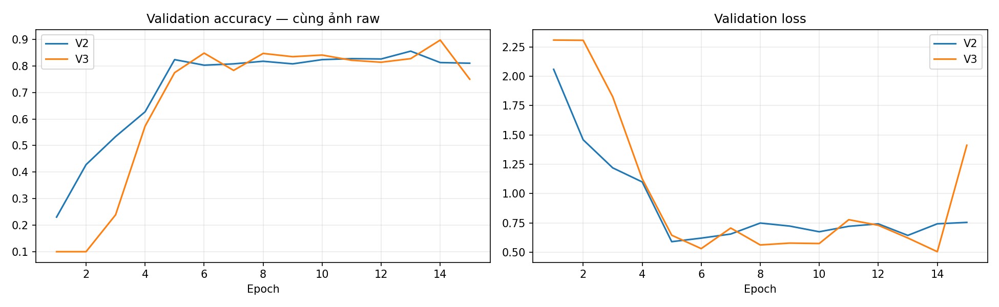

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00000.png


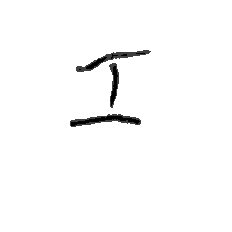

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00001.png


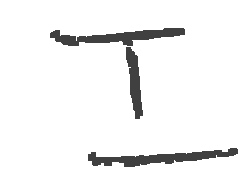

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00002.png


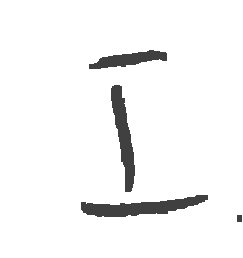

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00003.png


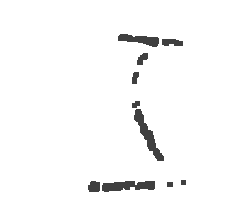

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00004.png


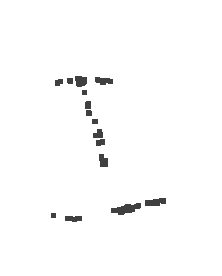

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00005.png


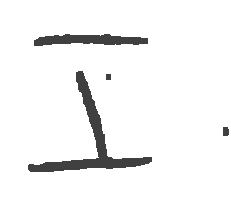

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00006.png


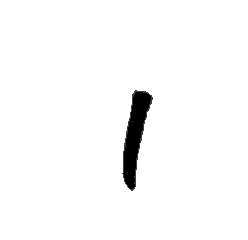

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00007.png


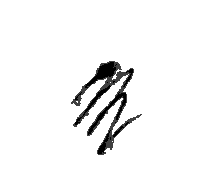

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00008.png


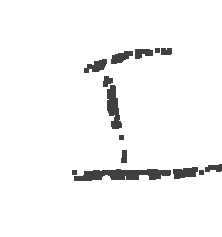

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00009.png


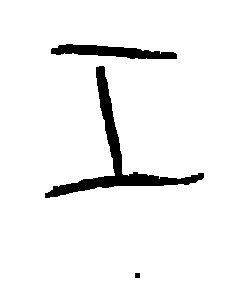

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00010.png


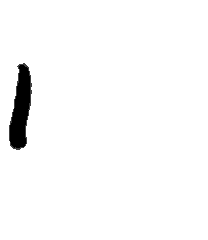

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00011.png


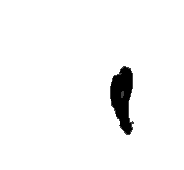

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00012.png


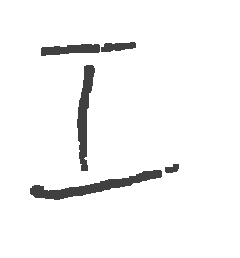

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00013.png


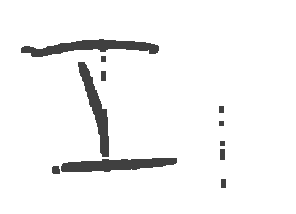

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00014.png


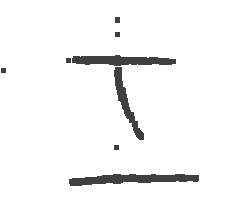

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00015.png


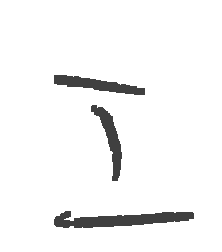

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00016.png


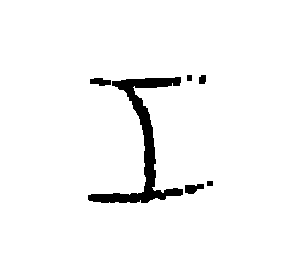

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00017.png


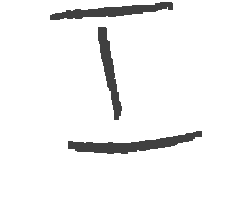

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00018.png


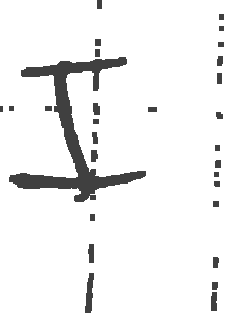

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00019.png


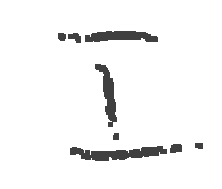

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00020.png


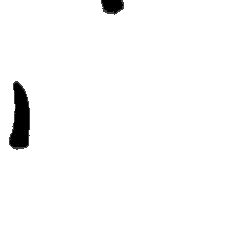

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00021.png


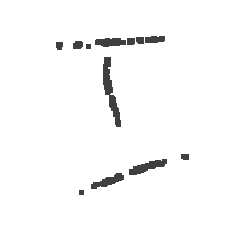

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00022.png


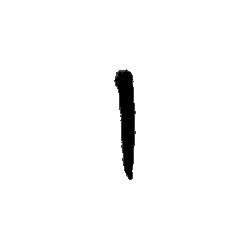

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00023.png


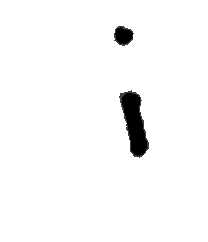

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00024.png


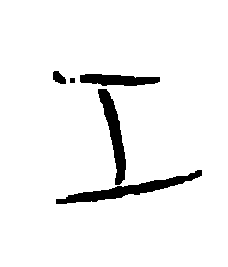

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00025.png


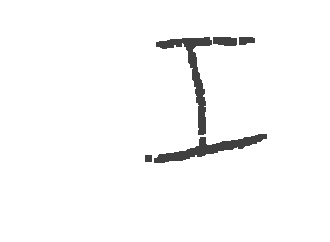

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00026.png


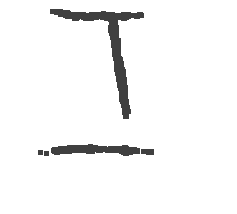

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00027.png


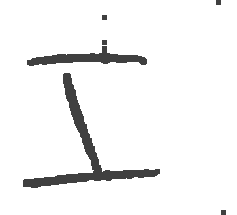

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00028.png


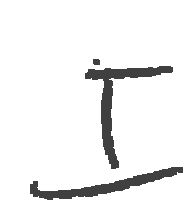

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00029.png


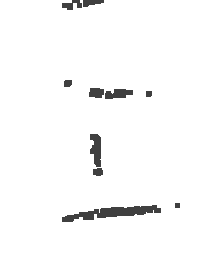

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00030.png


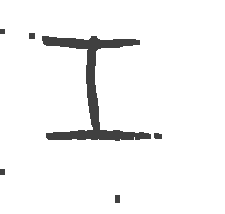

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00031.png


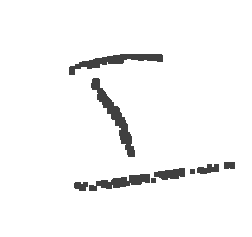

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00032.png


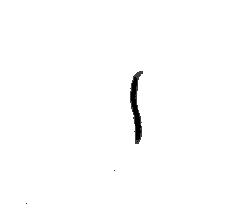

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00033.png


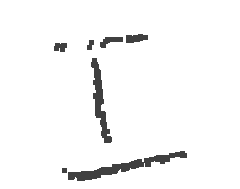

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00034.png


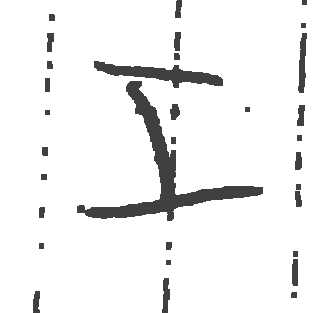

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00035.png


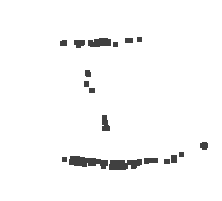

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00036.png


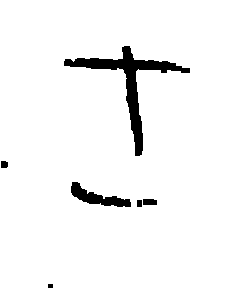

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00037.png


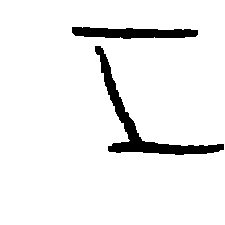

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00038.png


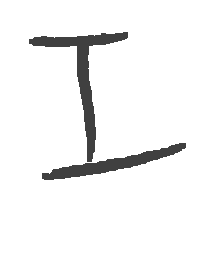

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00039.png


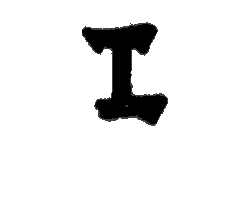

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00040.png


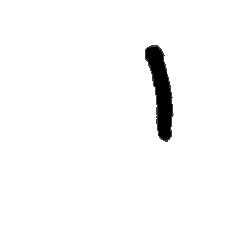

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00041.png


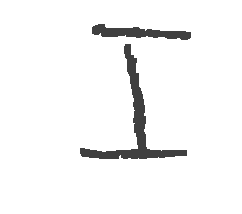

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00042.png


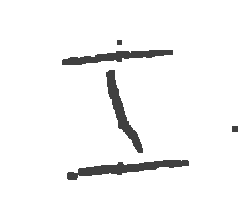

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00043.png


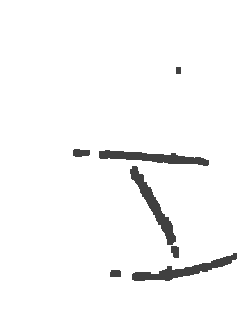

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00044.png


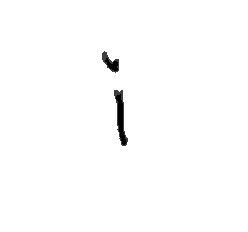

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00045.png


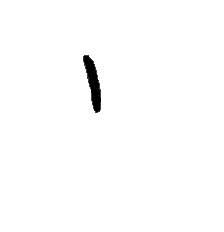

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00046.png


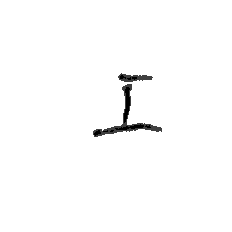

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00047.png


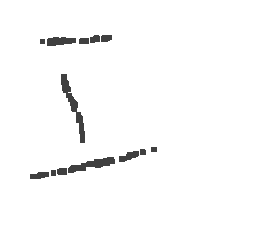

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00048.png


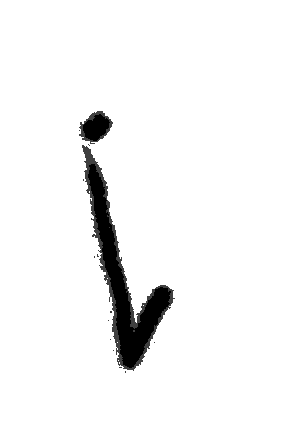

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00049.png


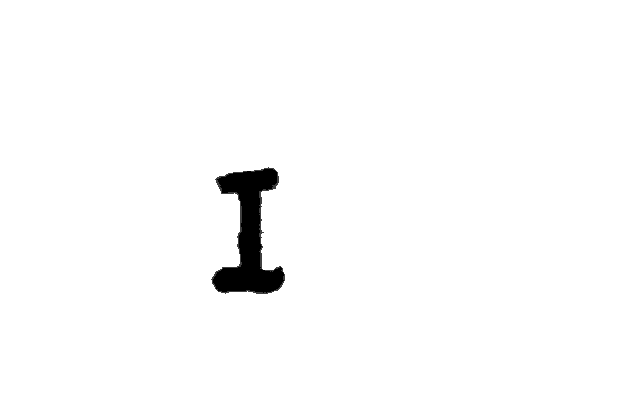

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00050.png


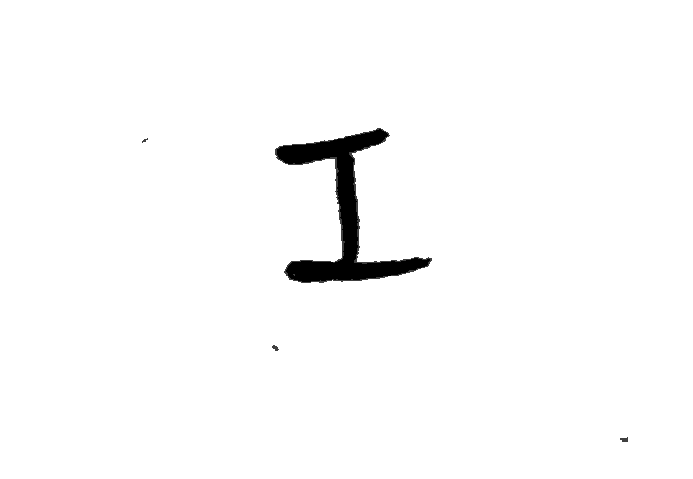

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00051.png


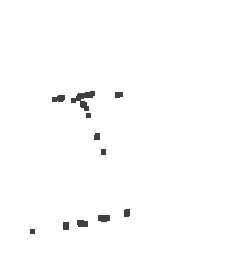

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00052.png


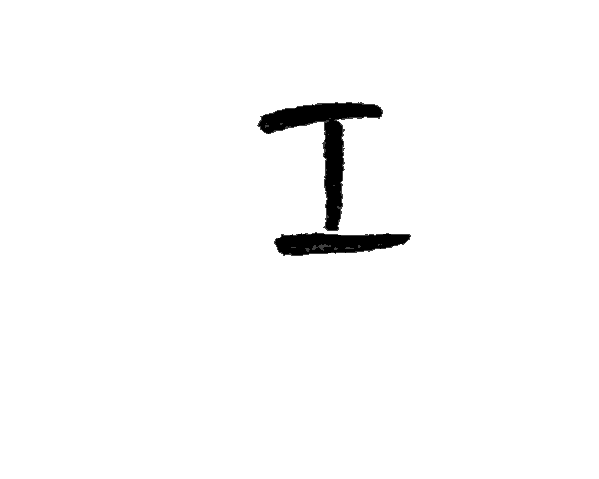

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00053.png


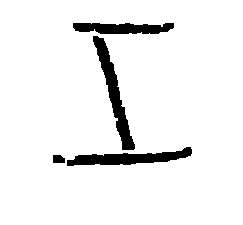

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00054.png


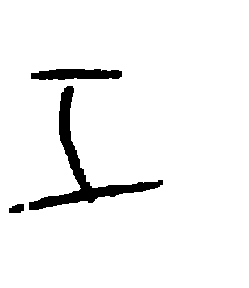

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00055.png


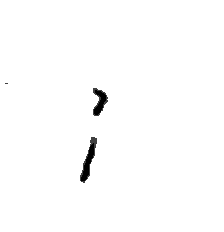

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00056.png


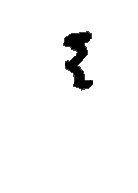

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00057.png


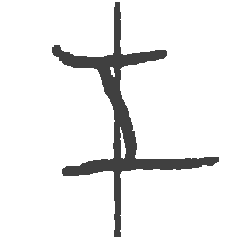

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00058.png


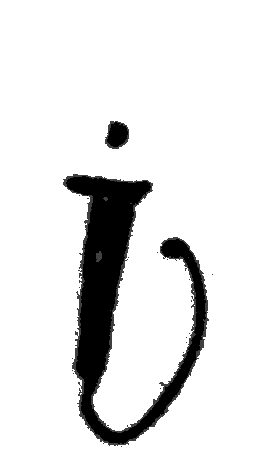

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00059.png


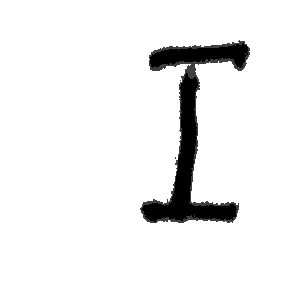

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00060.png


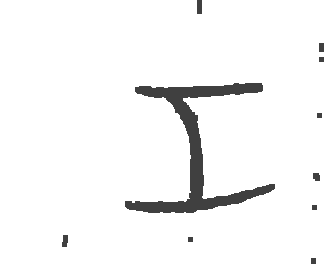

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00061.png


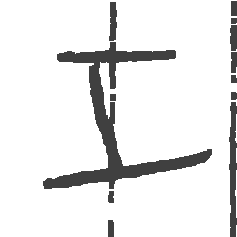

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00062.png


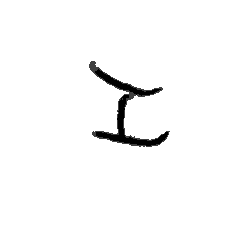

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00063.png


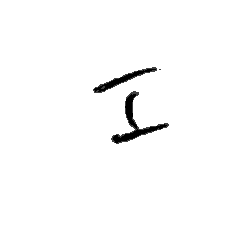

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00064.png


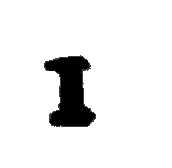

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00065.png


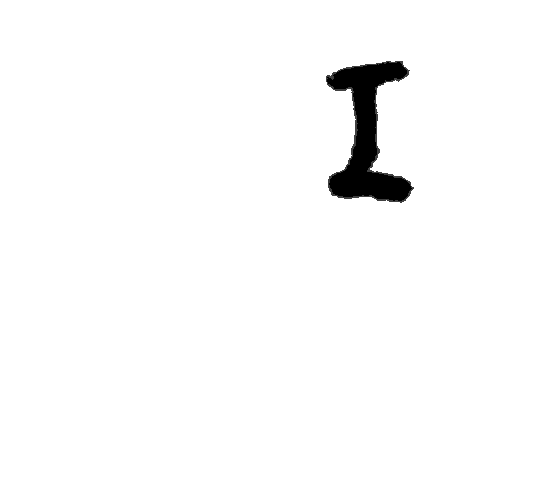

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00066.png


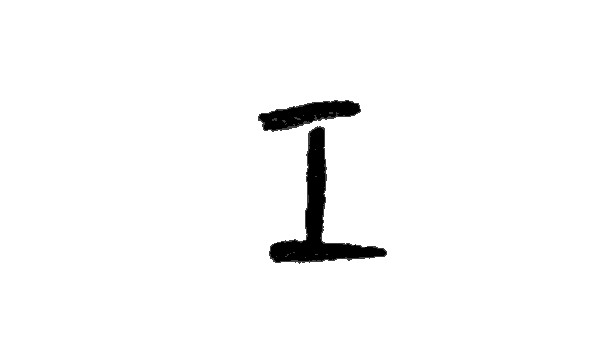

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00067.png


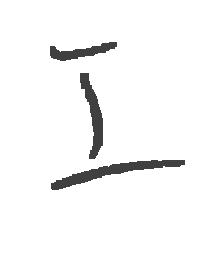

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00068.png


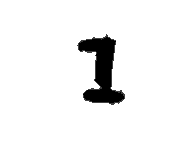

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00069.png


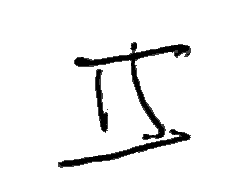

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00070.png


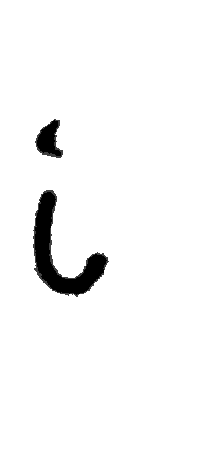

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00071.png


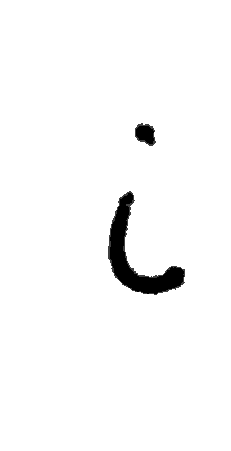

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00072.png


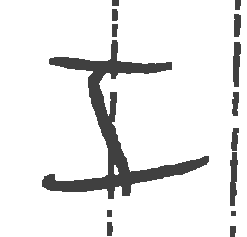

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00073.png


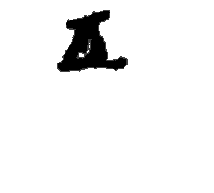

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00074.png


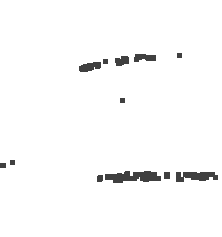

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00075.png


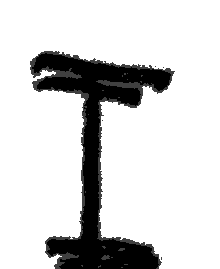

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00076.png


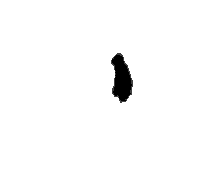

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00077.png


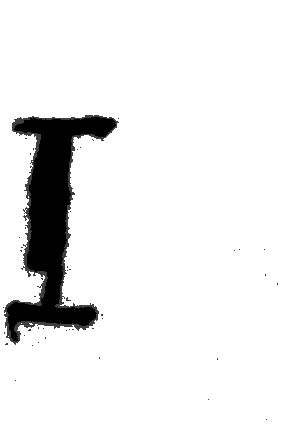

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00078.png


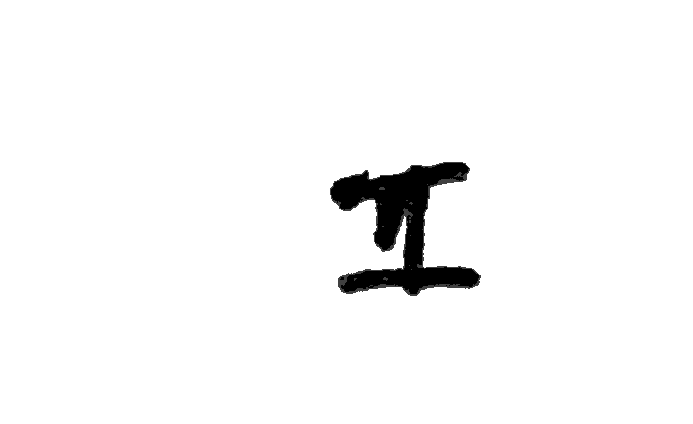

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00079.png


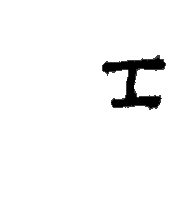

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00080.png


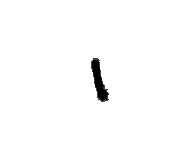

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00081.png


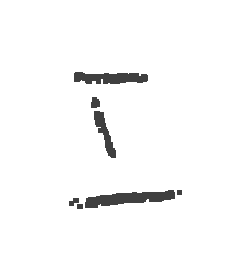

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00082.png


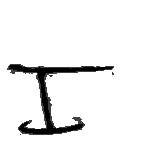

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00083.png


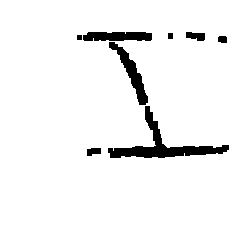

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00084.png


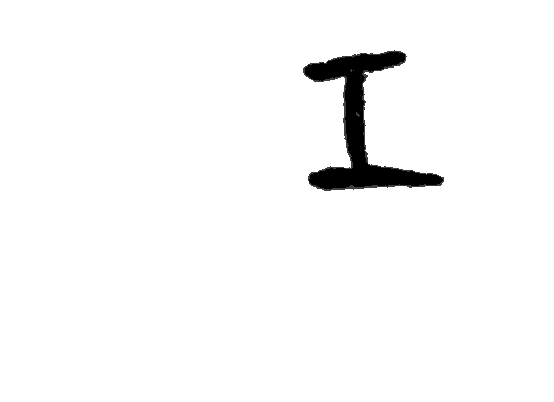

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00085.png


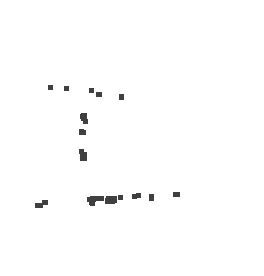

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00086.png


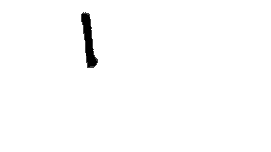

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00087.png


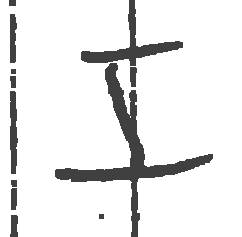

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00088.png


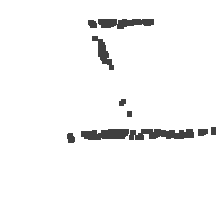

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00089.png


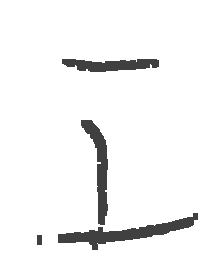

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00090.png


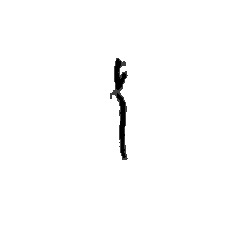

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00091.png


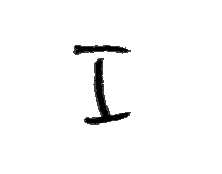

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00092.png


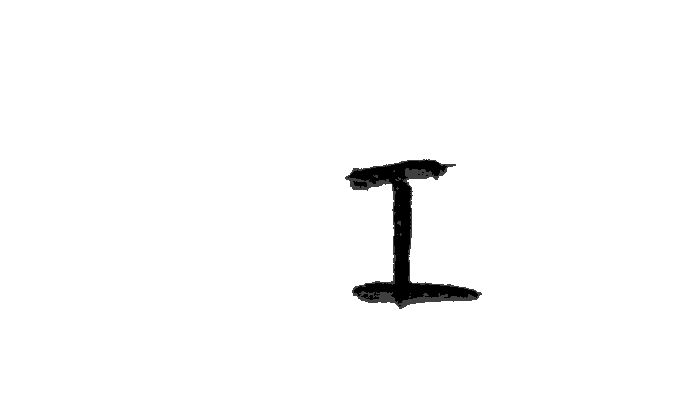

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00093.png


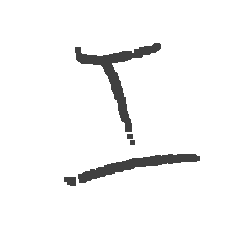

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00094.png


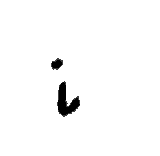

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00095.png


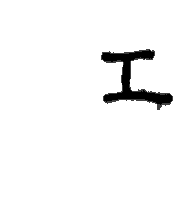

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00096.png


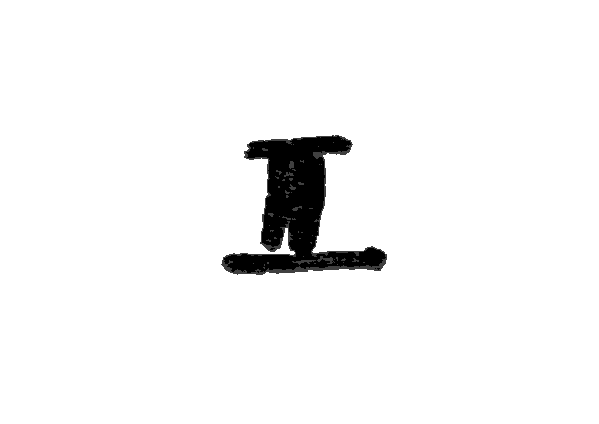

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00097.png


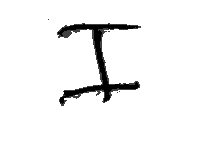

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00098.png


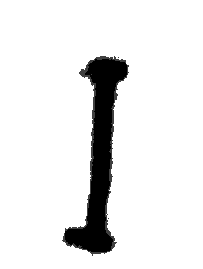

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00099.png


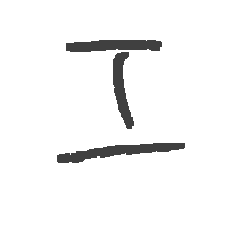

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00100.png


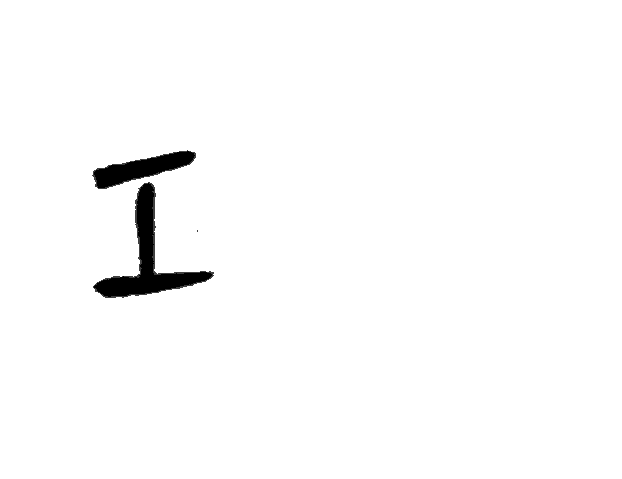

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00101.png


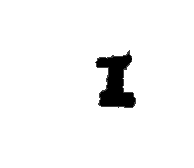

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00102.png


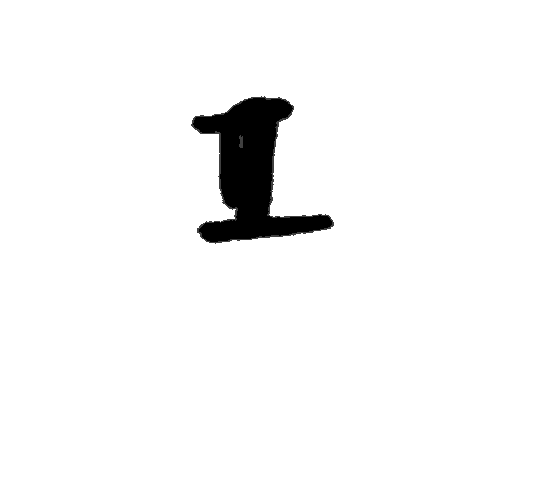

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00103.png


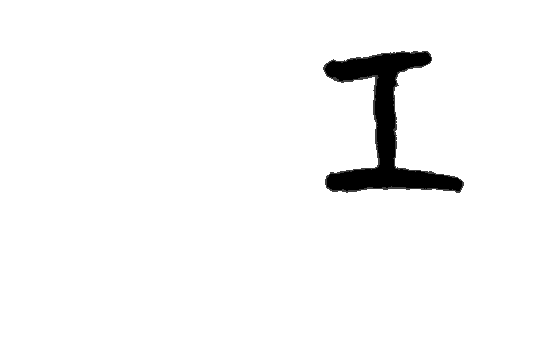

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00104.png


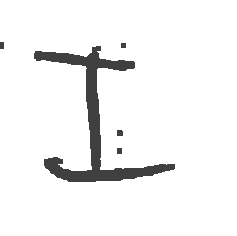

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00105.png


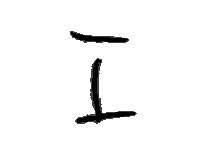

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00106.png


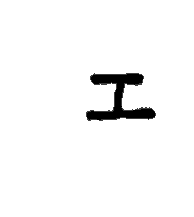

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00107.png


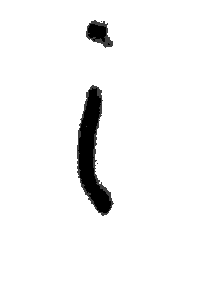

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00108.png


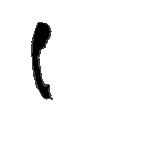

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00109.png


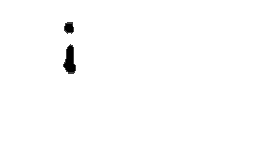

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00110.png


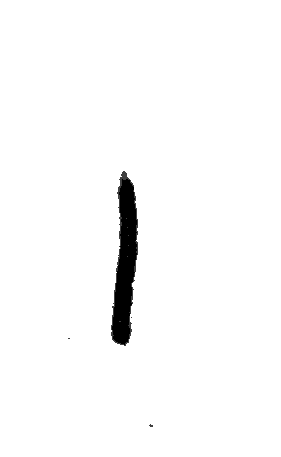

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00111.png


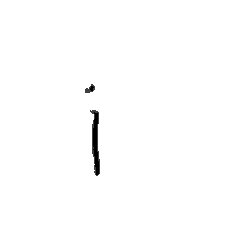

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00112.png


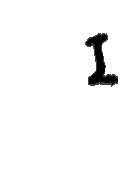

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00113.png


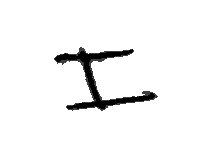

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00114.png


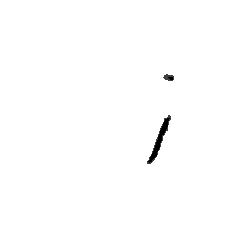

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00115.png


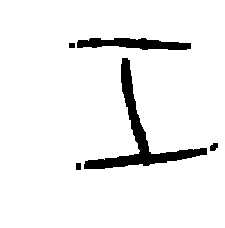

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00116.png


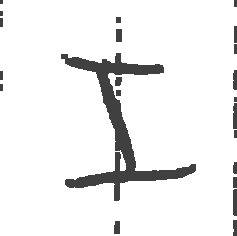

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00117.png


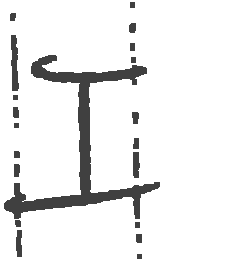

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00118.png


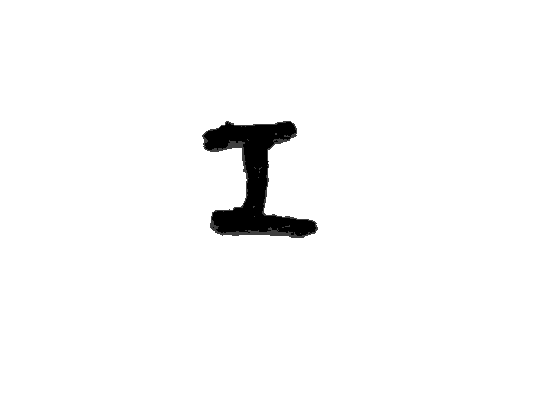

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00119.png


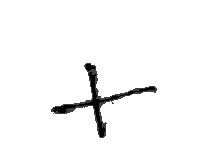

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00120.png


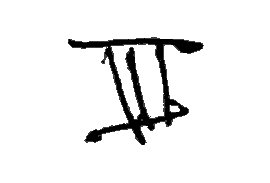

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00121.png


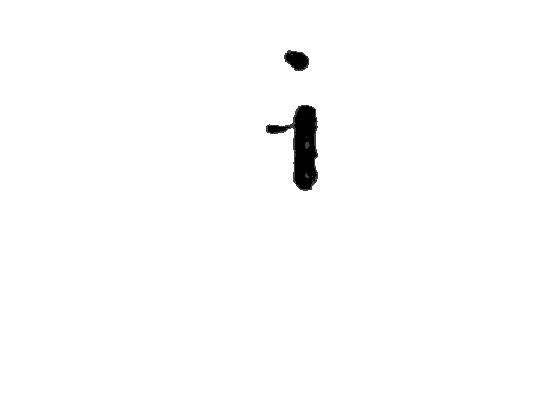

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00122.png


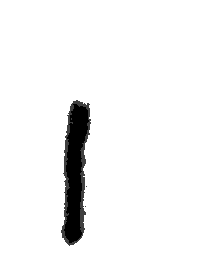

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00123.png


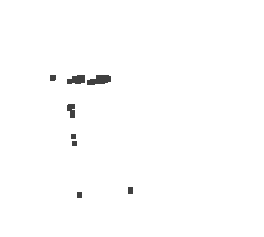

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00124.png


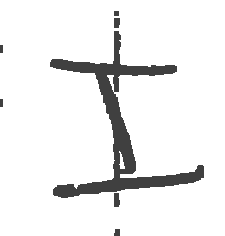

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00125.png


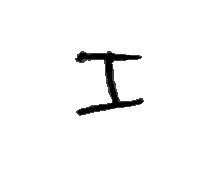

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00126.png


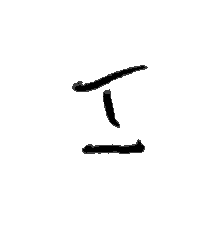

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00127.png


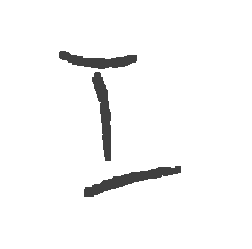

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00128.png


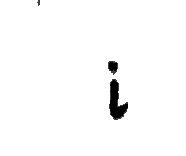

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00129.png


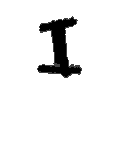

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00130.png


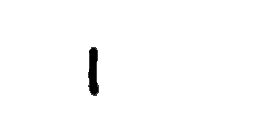

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00131.png


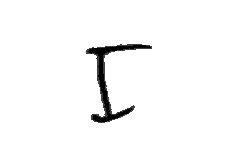

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00132.png


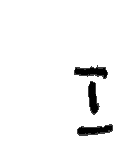

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00133.png


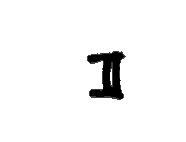

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00134.png


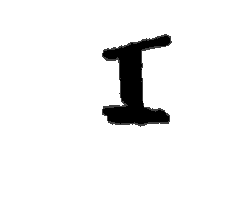

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00135.png


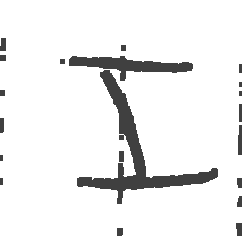

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00136.png


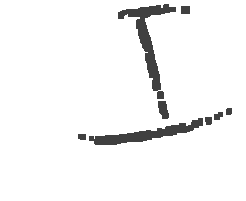

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00137.png


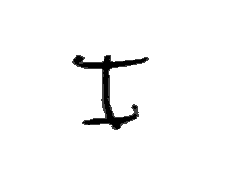

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00138.png


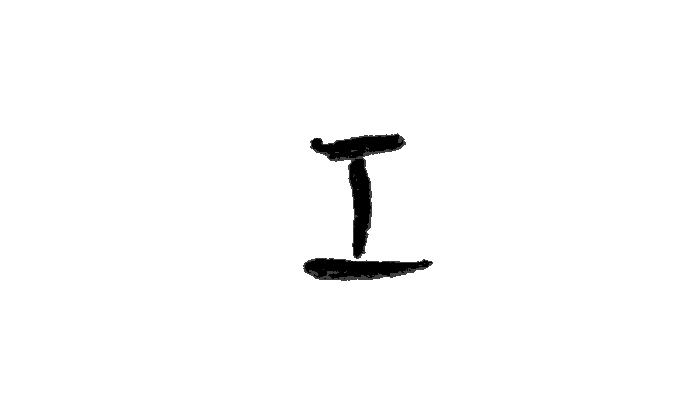

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00139.png


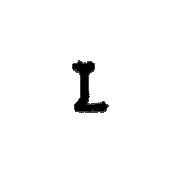

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00140.png


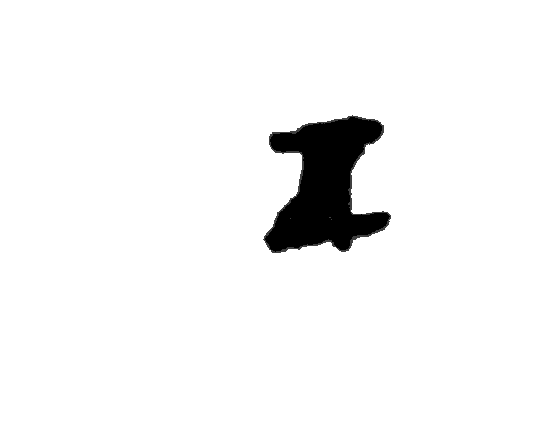

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00141.png


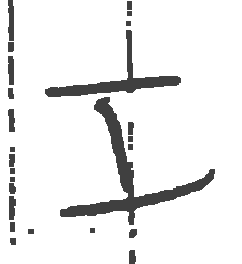

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00142.png


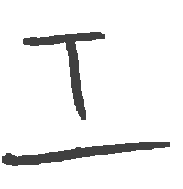

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00143.png


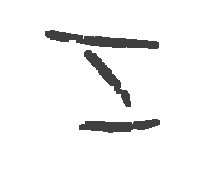

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00144.png


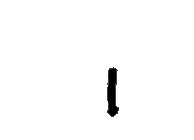

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00145.png


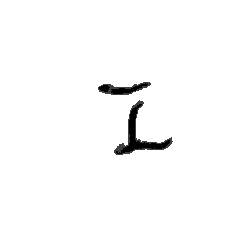

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00146.png


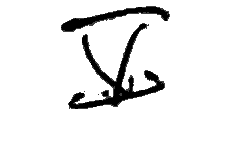

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00147.png


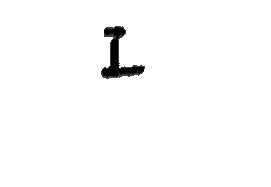

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00148.png


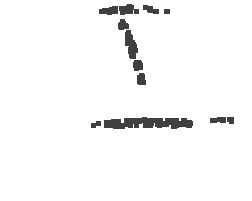

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00149.png


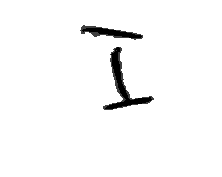

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00150.png


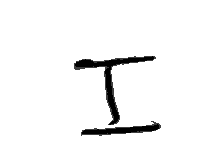

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00151.png


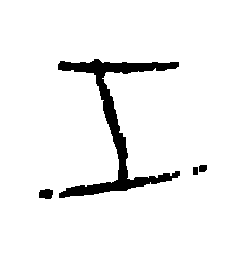

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00152.png


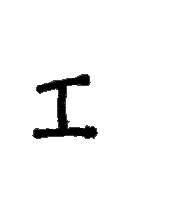

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00153.png


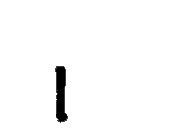

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00154.png


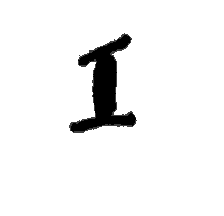

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00155.png


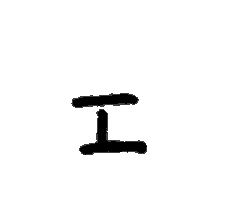

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00156.png


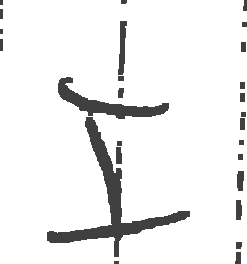

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00157.png


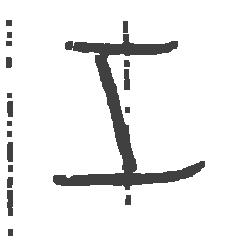

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00158.png


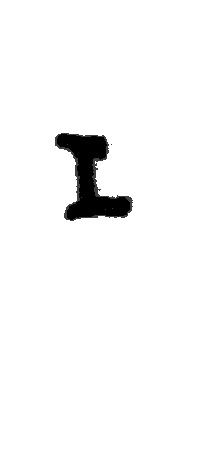

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00159.png


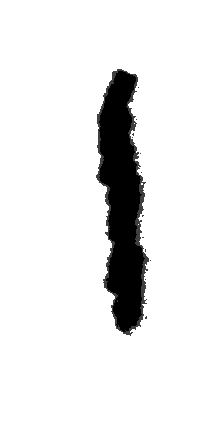

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00160.png


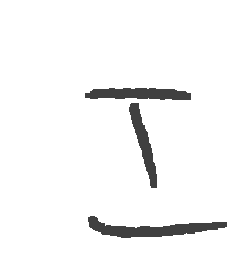

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00161.png


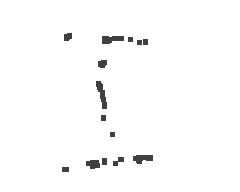

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00162.png


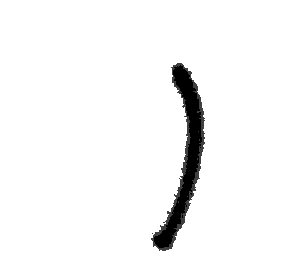

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00163.png


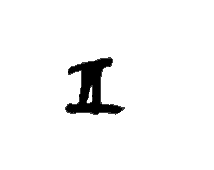

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00164.png


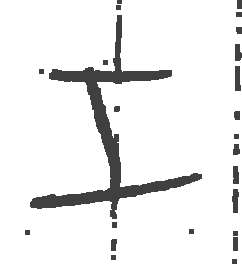

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00165.png


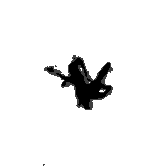

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00166.png


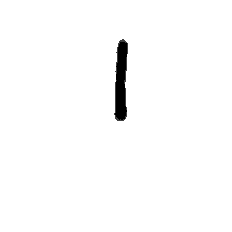

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00167.png


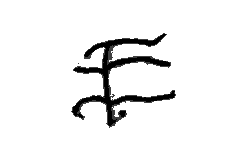

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00168.png


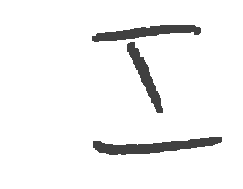

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00169.png


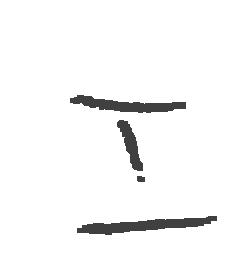

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00170.png


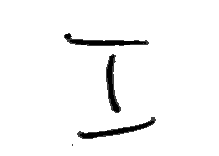

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00171.png


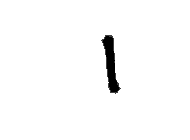

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00172.png


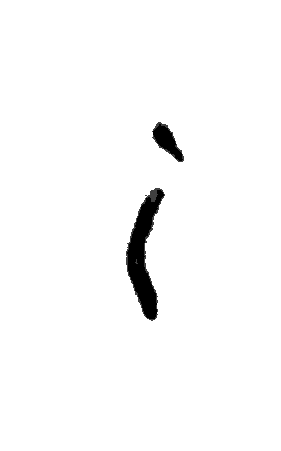

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00173.png


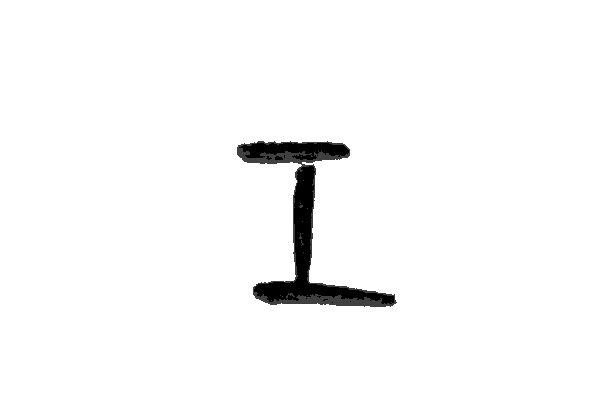

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00174.png


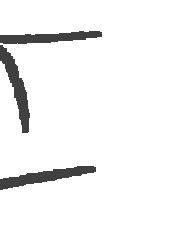

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00175.png


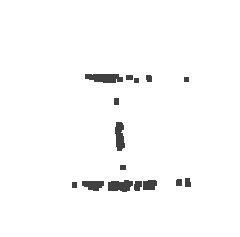

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00176.png


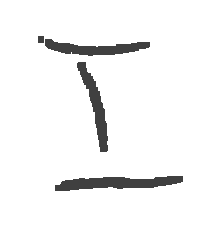

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00177.png


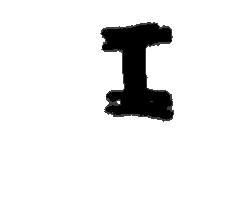

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00178.png


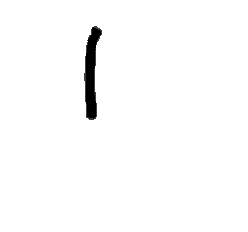

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00179.png


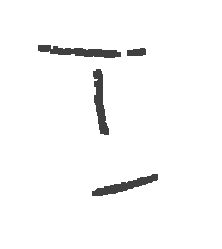

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00180.png


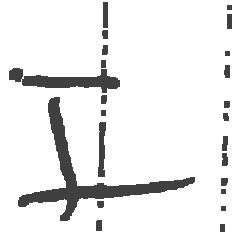

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00181.png


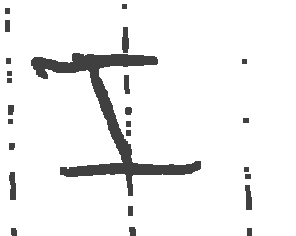

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00182.png


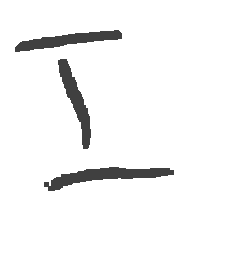

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00183.png


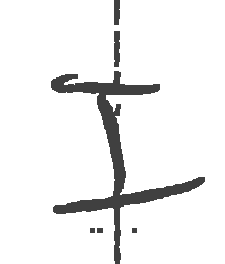

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00184.png


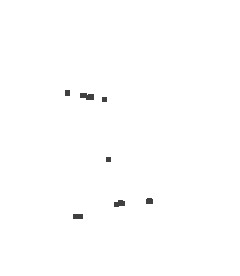

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00185.png


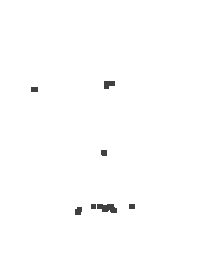

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00186.png


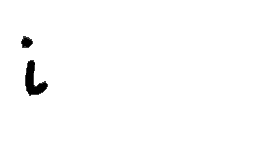

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00187.png


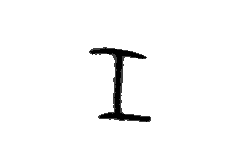

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00188.png


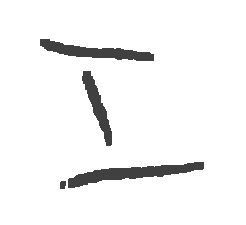

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00189.png


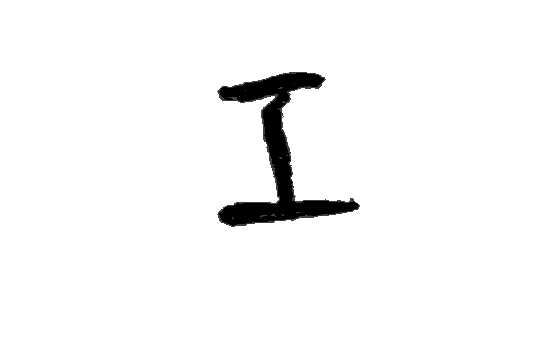

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00190.png


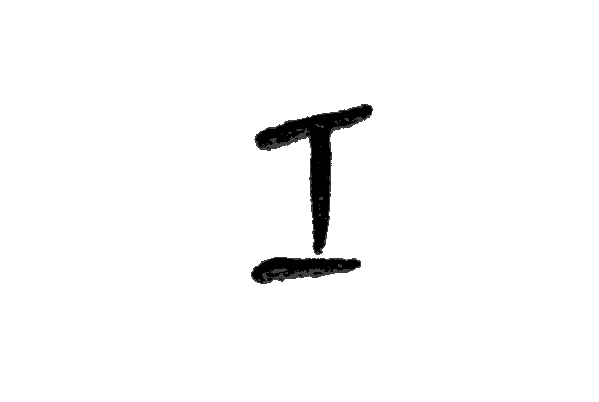

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00191.png


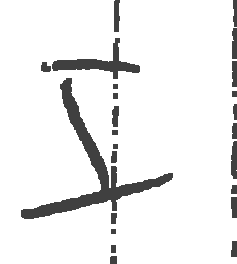

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00192.png


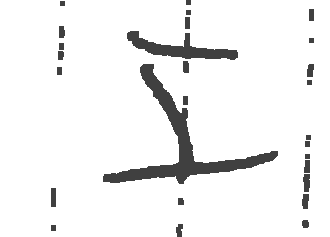

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00193.png


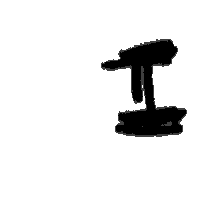

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00194.png


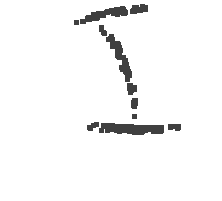

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00195.png


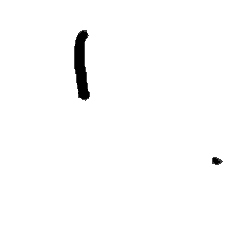

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00196.png


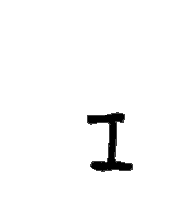

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00197.png


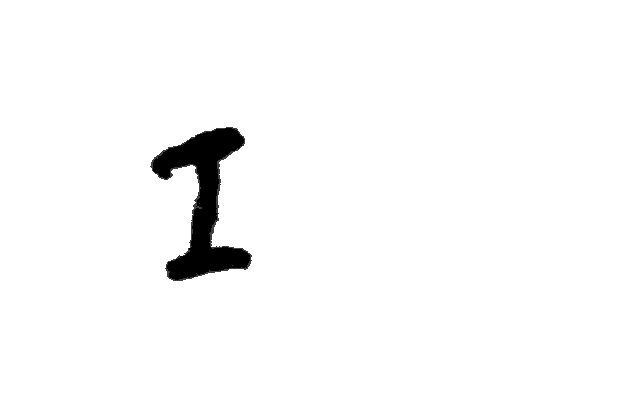

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00198.png


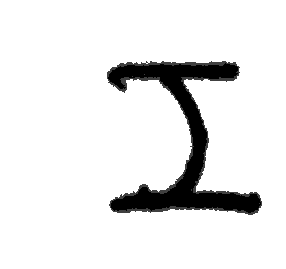

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00199.png


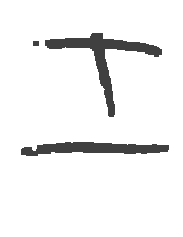

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00200.png


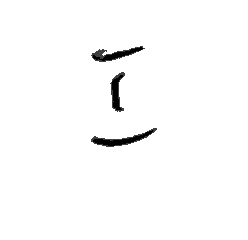

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00201.png


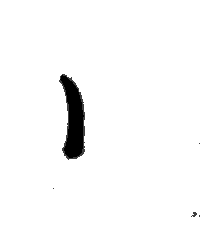

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00202.png


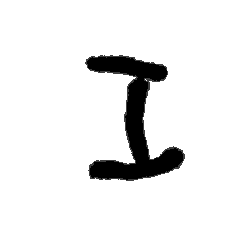

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00203.png


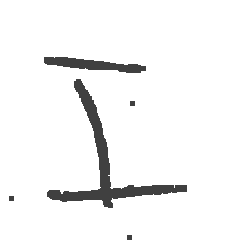

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00204.png


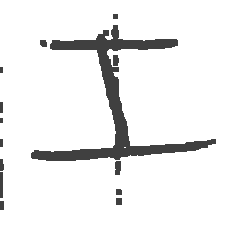

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00205.png


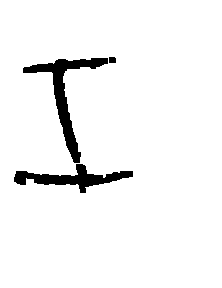

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00206.png


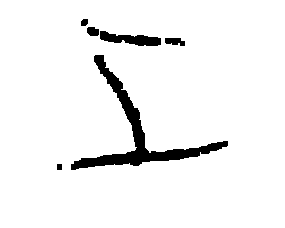

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00207.png


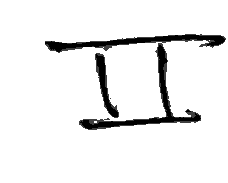

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00208.png


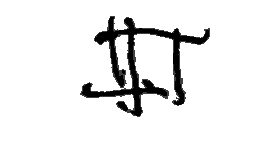

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00209.png


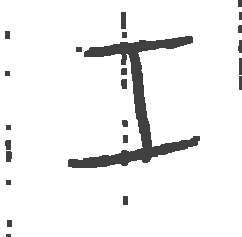

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00210.png


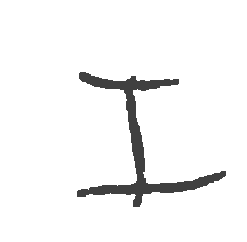

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00211.png


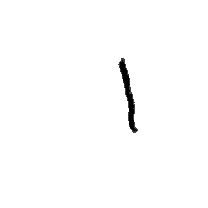

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00212.png


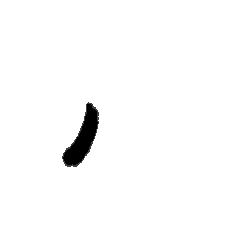

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00213.png


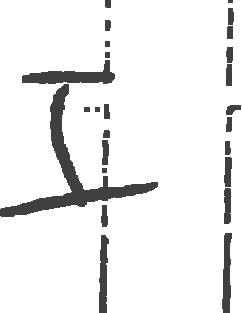

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00214.png


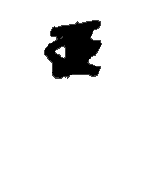

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00215.png


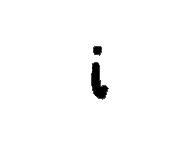

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00216.png


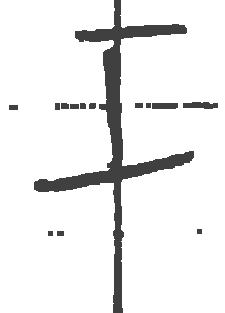

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00217.png


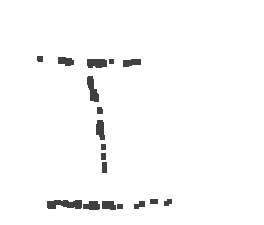

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00218.png


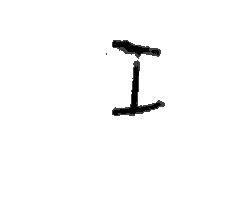

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00219.png


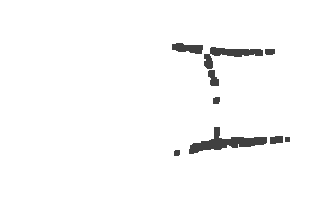

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00220.png


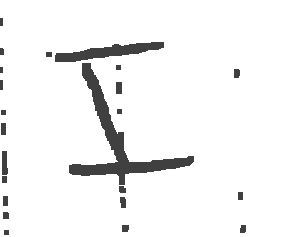

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00221.png


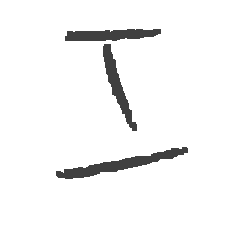

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00222.png


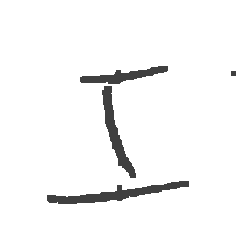

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00223.png


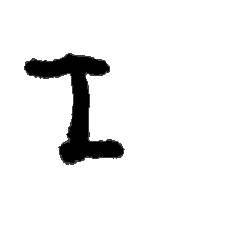

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00224.png


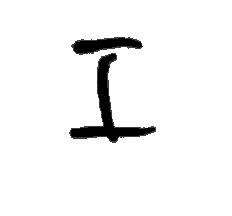

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00225.png


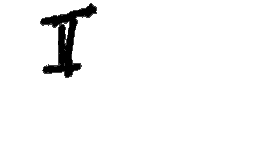

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00226.png


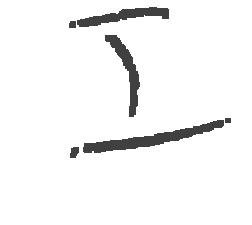

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00227.png


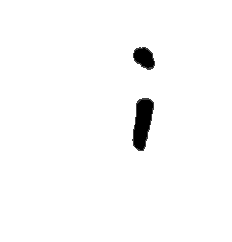

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00228.png


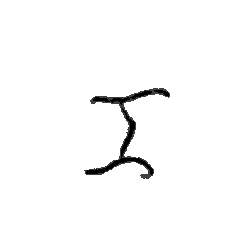

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00229.png


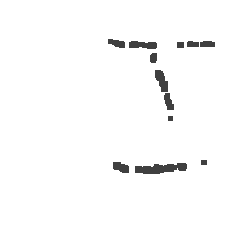

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00230.png


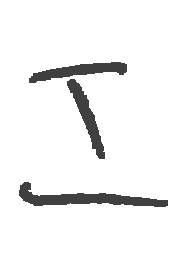

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00231.png


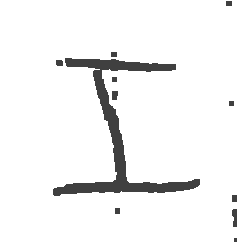

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00232.png


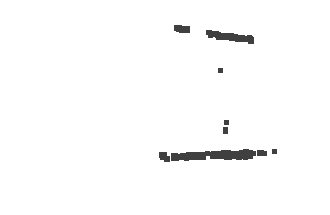

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00233.png


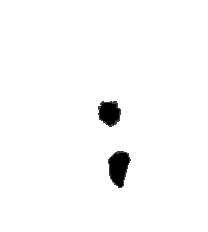

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00234.png


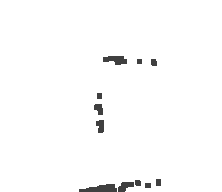

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00235.png


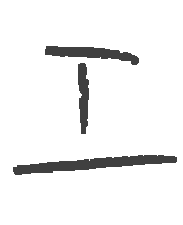

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00236.png


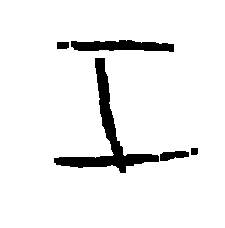

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00237.png


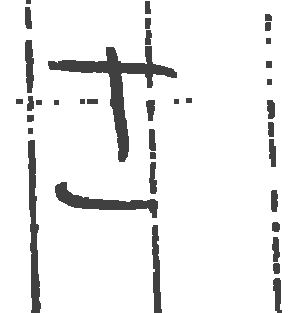

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00238.png


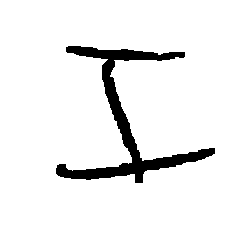

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00239.png


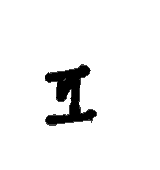

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00240.png


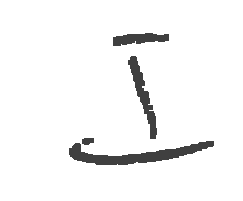

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00241.png


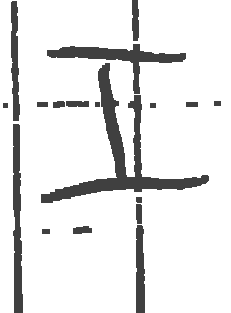

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00242.png


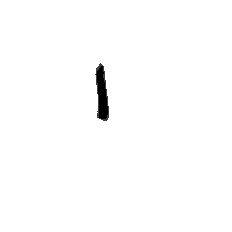

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00243.png


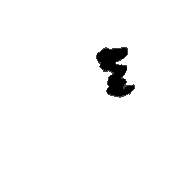

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00244.png


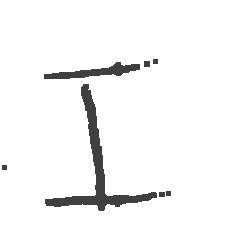

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00245.png


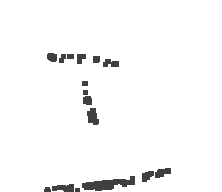

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00246.png


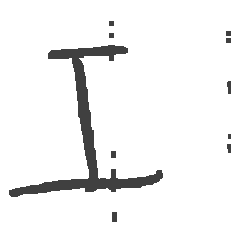

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00247.png


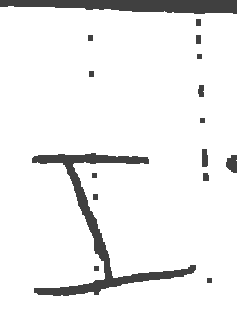

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00248.png


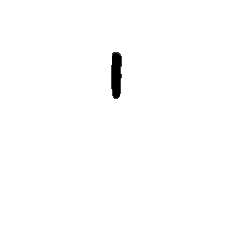

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00249.png


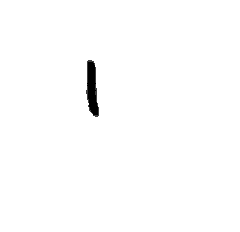

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00250.png


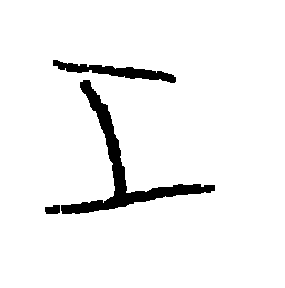

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00251.png


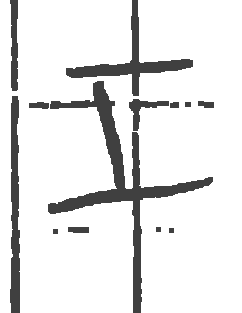

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00252.png


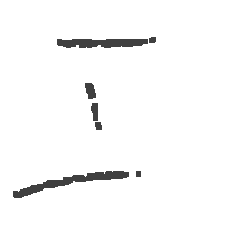

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00253.png


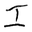

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00254.png


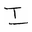

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00255.png


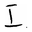

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00256.png


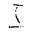

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00257.png


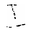

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00258.png


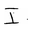

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00259.png


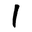

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00260.png


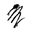

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00261.png


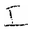

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00262.png


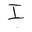

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00263.png


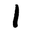

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00264.png


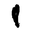

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00265.png


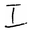

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00266.png


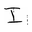

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00267.png


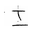

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00268.png


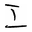

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00269.png


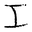

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00270.png


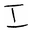

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00271.png


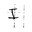

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00272.png


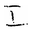

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00273.png


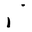

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00274.png


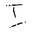

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00275.png


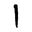

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00276.png


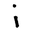

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00277.png


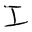

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00278.png


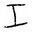

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00279.png


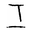

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00280.png


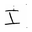

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00281.png


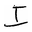

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00282.png


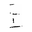

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00283.png


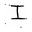

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00284.png


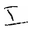

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00285.png


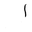

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00286.png


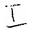

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00287.png


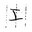

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00288.png


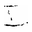

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00289.png


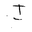

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00290.png


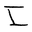

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00291.png


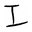

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00292.png


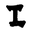

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00293.png


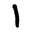

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00294.png


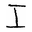

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00295.png


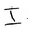

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00296.png


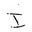

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00297.png


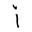

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00298.png


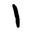

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00299.png


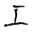

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00300.png


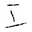

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00301.png


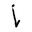

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00302.png


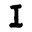

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00303.png


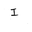

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00304.png


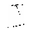

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00305.png


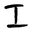

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00306.png


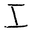

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00307.png


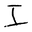

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00308.png


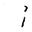

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00309.png


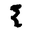

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00310.png


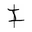

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00311.png


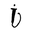

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00312.png


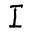

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00313.png


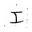

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00314.png


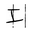

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00315.png


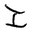

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00316.png


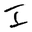

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00317.png


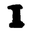

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00318.png


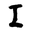

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00319.png


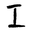

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00320.png


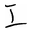

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00321.png


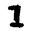

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00322.png


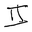

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00323.png


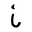

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00324.png


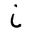

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00325.png


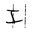

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00326.png


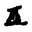

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00327.png


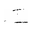

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00328.png


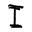

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00329.png


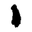

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00330.png


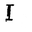

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00331.png


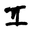

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00332.png


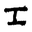

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00333.png


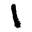

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00334.png


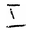

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00335.png


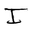

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00336.png


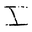

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00337.png


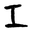

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00338.png


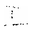

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00339.png


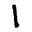

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00340.png


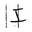

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00341.png


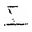

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00342.png


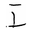

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00343.png


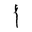

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00344.png


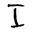

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00345.png


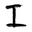

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00346.png


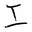

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00347.png


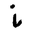

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00348.png


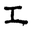

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00349.png


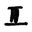

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00350.png


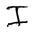

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00351.png


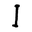

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00352.png


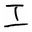

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00353.png


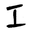

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00354.png


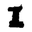

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00355.png


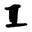

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00356.png


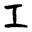

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00357.png


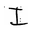

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00358.png


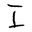

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00359.png


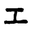

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00360.png


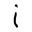

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00361.png


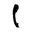

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00362.png


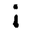

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00363.png


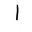

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00364.png


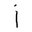

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00365.png


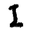

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00366.png


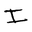

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00367.png


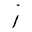

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00368.png


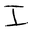

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00369.png


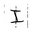

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00370.png


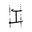

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00371.png


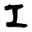

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00372.png


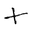

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00373.png


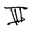

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00374.png


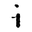

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00375.png


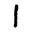

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00376.png


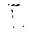

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00377.png


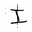

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00378.png


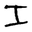

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00379.png


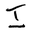

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00380.png


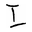

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00381.png


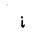

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00382.png


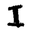

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00383.png


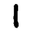

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00384.png


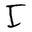

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00385.png


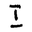

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00386.png


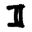

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00387.png


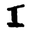

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00388.png


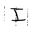

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00389.png


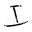

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00390.png


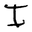

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00391.png


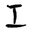

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00392.png


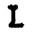

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00393.png


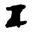

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00394.png


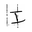

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00395.png


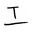

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00396.png


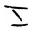

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00397.png


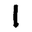

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00398.png


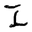

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00399.png


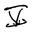

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00400.png


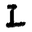

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00401.png


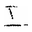

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00402.png


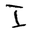

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00403.png


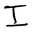

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00404.png


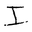

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00405.png


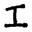

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00406.png


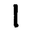

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00407.png


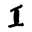

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00408.png


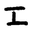

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00409.png


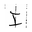

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00410.png


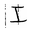

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00411.png


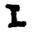

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00412.png


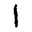

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00413.png


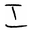

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00414.png


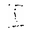

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00415.png


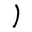

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00416.png


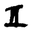

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00417.png


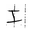

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00418.png


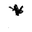

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00419.png


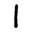

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00420.png


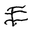

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00421.png


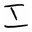

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00422.png


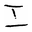

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00423.png


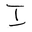

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00424.png


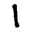

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00425.png


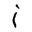

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00426.png


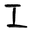

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00427.png


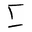

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00428.png


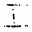

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00429.png


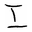

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00430.png


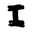

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00431.png


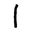

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00432.png


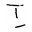

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00433.png


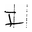

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00434.png


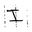

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00435.png


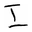

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00436.png


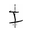

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00437.png


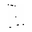

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00438.png


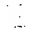

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00439.png


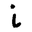

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00440.png


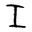

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00441.png


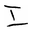

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00442.png


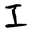

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00443.png


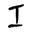

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00444.png


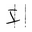

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00445.png


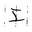

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00446.png


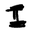

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00447.png


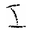

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00448.png


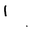

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00449.png


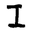

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00450.png


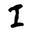

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00451.png


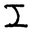

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00452.png


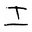

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00453.png


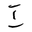

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00454.png


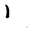

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00455.png


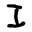

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00456.png


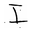

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00457.png


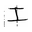

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00458.png


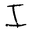

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00459.png


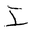

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00460.png


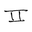

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00461.png


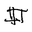

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00462.png


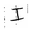

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00463.png


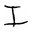

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00464.png


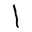

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00465.png


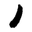

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00466.png


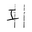

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00467.png


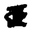

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00468.png


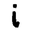

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00469.png


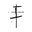

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00470.png


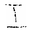

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00471.png


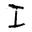

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00472.png


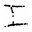

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00473.png


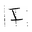

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00474.png


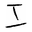

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00475.png


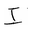

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00476.png


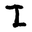

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00477.png


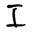

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00478.png


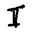

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00479.png


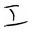

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00480.png


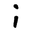

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00481.png


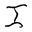

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00482.png


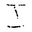

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00483.png


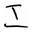

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00484.png


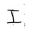

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00485.png


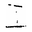

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00486.png


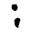

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00487.png


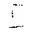

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00488.png


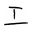

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00489.png


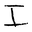

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00490.png


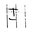

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00491.png


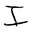

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00492.png


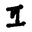

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00493.png


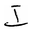

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00494.png


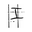

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00495.png


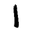

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00496.png


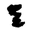

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00497.png


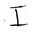

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00498.png


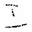

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00499.png


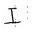

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00500.png


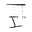

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00501.png


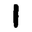

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00502.png


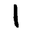

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00503.png


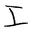

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00504.png


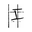

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00505.png


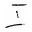

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00506.png


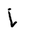

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00507.png


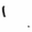

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00508.png


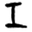

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00509.png


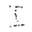

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00510.png


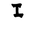

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00511.png


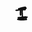

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00512.png


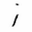

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00513.png


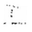

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00514.png


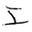

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00515.png


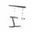

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00516.png


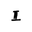

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00517.png


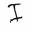

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00518.png


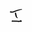

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00519.png


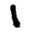

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00520.png


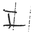

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00521.png


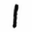

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00522.png


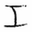

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00523.png


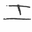

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00524.png


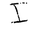

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00525.png


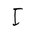

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00526.png


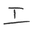

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00527.png


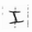

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00528.png


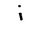

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00529.png


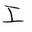

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00530.png


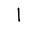

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00531.png


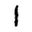

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00532.png


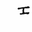

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00533.png


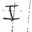

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00534.png


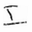

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00535.png


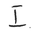

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00536.png


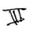

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00537.png


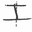

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00538.png


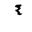

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00539.png


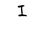

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00540.png


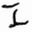

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00541.png


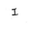

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00542.png


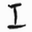

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00543.png


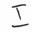

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00544.png


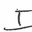

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00545.png


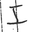

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00546.png


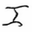

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00547.png


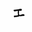

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00548.png


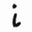

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00549.png


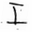

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00550.png


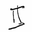

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00551.png


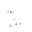

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00552.png


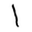

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00553.png


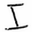

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00554.png


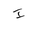

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00555.png


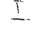

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00556.png


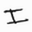

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00557.png


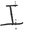

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00558.png


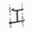

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00559.png


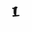

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00560.png


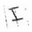

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00561.png


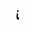

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00562.png


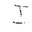

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00563.png


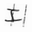

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00564.png


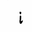

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00565.png


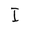

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00566.png


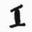

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00567.png


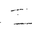

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00568.png


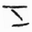

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00569.png


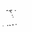

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00570.png


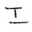

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00571.png


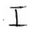

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00572.png


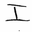

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00573.png


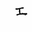

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00574.png


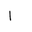

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00575.png


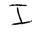

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00576.png


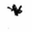

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00577.png


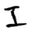

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00578.png


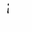

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00579.png


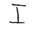

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00580.png


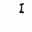

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00581.png


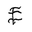

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00582.png


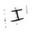

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00583.png


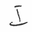

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00584.png


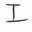

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00585.png


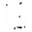

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00586.png


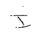

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00587.png


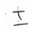

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00588.png


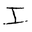

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00589.png


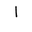

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00590.png


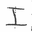

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00591.png


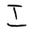

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00592.png


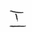

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00593.png


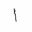

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00594.png


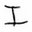

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00595.png


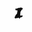

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00596.png


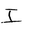

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00597.png


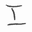

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00598.png


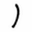

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00599.png


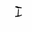

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00600.png


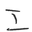

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00601.png


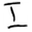

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00602.png


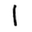

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00603.png


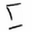

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00604.png


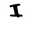

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00605.png


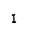

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00606.png


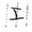

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00607.png


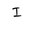

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00608.png


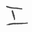

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00609.png


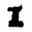

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00610.png


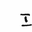

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00611.png


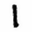

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00612.png


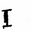

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00613.png


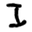

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00614.png


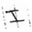

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00615.png


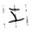

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00616.png


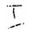

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00617.png


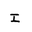

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00618.png


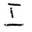

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00619.png


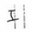

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00620.png


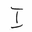

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00621.png


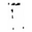

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00622.png


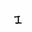

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00623.png


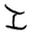

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00624.png


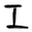

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00625.png


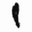

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00626.png


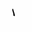

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00627.png


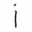

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00628.png


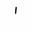

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00629.png


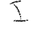

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00630.png


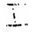

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00631.png


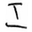

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00632.png


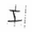

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00633.png


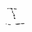

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00634.png


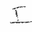

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00635.png


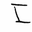

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00636.png


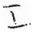

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00637.png


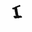

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00638.png


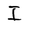

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00639.png


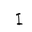

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00640.png


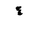

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00641.png


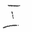

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00642.png


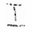

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00643.png


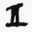

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00644.png


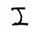

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00645.png


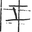

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00646.png


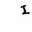

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00647.png


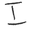

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00648.png


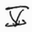

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00649.png


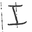

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00650.png


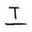

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00651.png


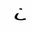

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00652.png


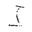

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00653.png


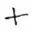

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00654.png


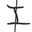

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00655.png


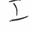

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00656.png


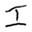

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00657.png


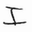

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00658.png


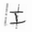

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00659.png


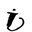

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00660.png


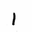

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00661.png


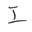

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00662.png


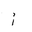

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00663.png


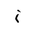

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00664.png


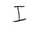

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00665.png


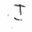

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00666.png


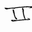

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00667.png


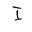

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00668.png


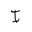

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00669.png


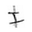

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00670.png


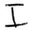

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00671.png


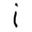

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00672.png


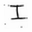

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00673.png


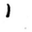

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00674.png


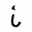

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00675.png


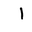

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00676.png


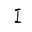

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00677.png


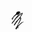

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00678.png


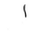

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00679.png


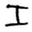

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00680.png


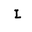

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00681.png


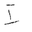

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00682.png


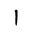

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00683.png


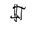

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00684.png


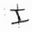

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00685.png


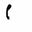

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00686.png


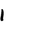

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00687.png


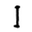

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00688.png


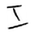

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00689.png


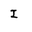

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00690.png


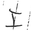

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00691.png


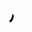

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00692.png


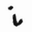

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00693.png


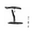

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00694.png


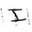

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00695.png


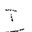

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00696.png


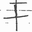

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00697.png


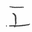

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00698.png


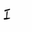

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00699.png


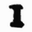

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00700.png


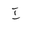

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00701.png


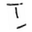

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00702.png


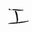

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00703.png


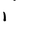

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00704.png


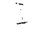

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00705.png


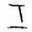

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00706.png


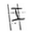

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00707.png


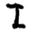

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00708.png


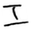

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00709.png


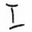

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00710.png


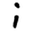

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00711.png


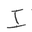

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00712.png


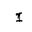

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00713.png


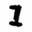

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00714.png


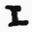

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00715.png


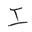

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00716.png


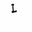

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00717.png


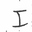

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00718.png


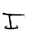

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00719.png


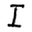

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00720.png


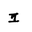

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00721.png


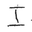

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00722.png


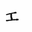

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00723.png


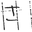

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00724.png


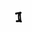

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00725.png


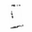

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00726.png


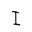

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00727.png


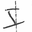

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00728.png


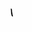

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00729.png


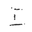

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00730.png


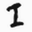

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00731.png


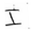

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00732.png


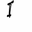

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00733.png


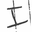

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00734.png


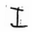

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00735.png


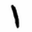

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00736.png


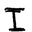

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00737.png


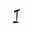

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00738.png


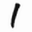

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00739.png


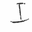

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00740.png


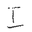

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00741.png


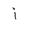

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00742.png


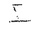

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00743.png


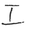

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00744.png


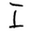

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00745.png


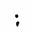

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/i/00746.png


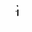

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00000.png


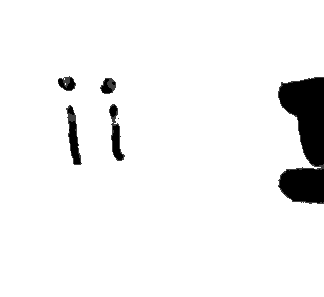

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00001.png


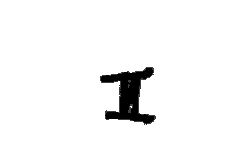

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00002.png


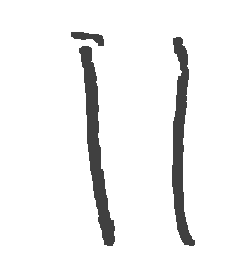

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00003.png


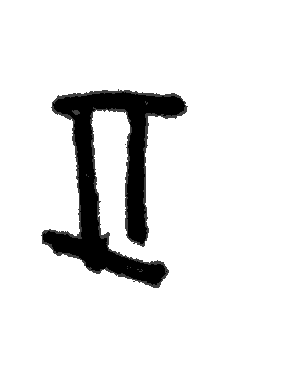

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00004.png


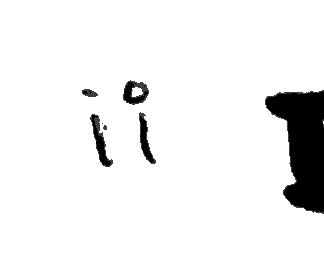

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00005.png


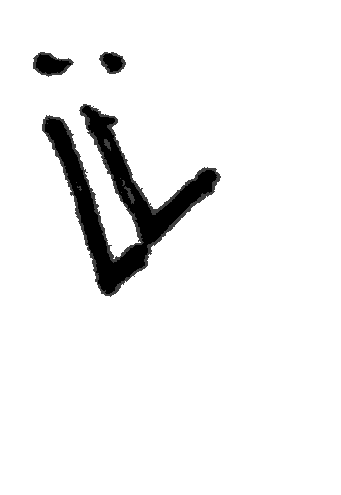

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00006.png


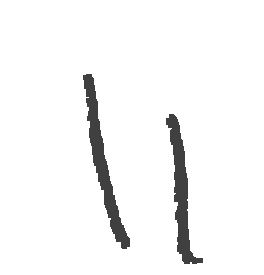

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00007.png


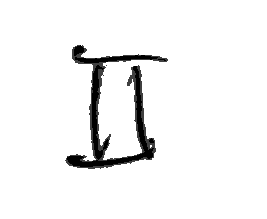

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00008.png


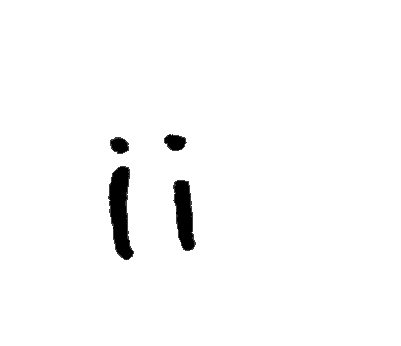

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00009.png


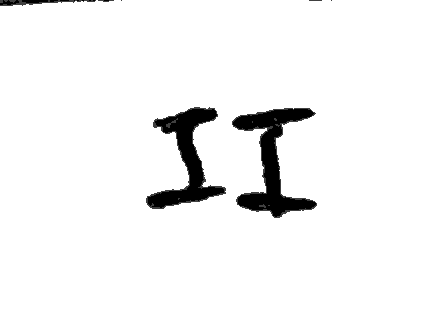

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00010.png


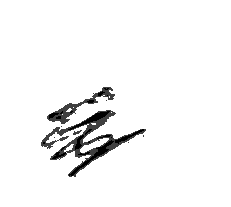

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00011.png


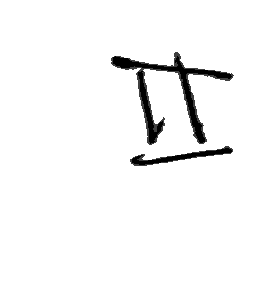

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00012.png


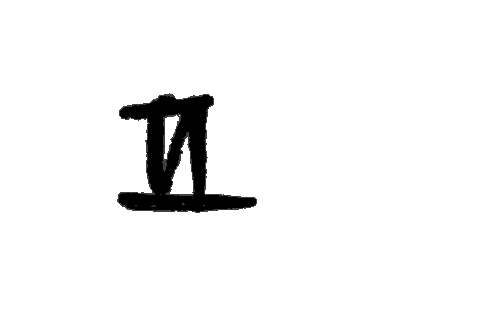

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00013.png


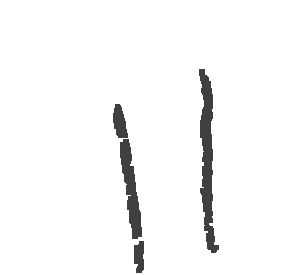

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00014.png


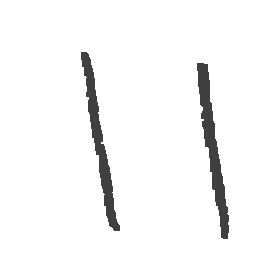

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00015.png


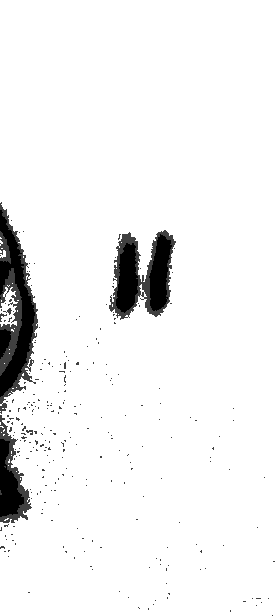

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00016.png


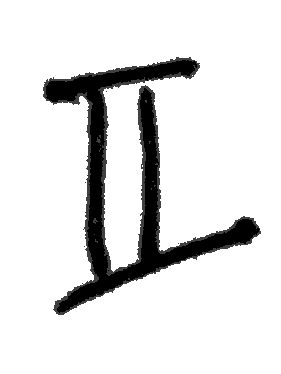

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00017.png


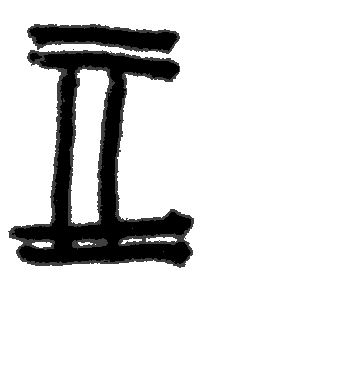

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00018.png


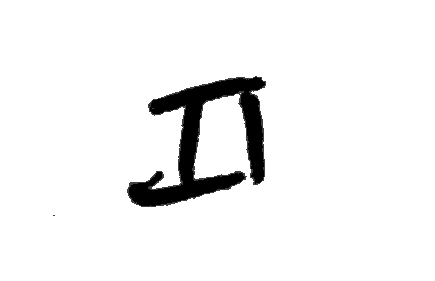

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00019.png


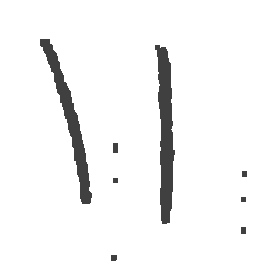

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00020.png


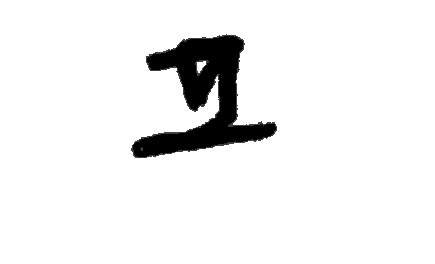

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00021.png


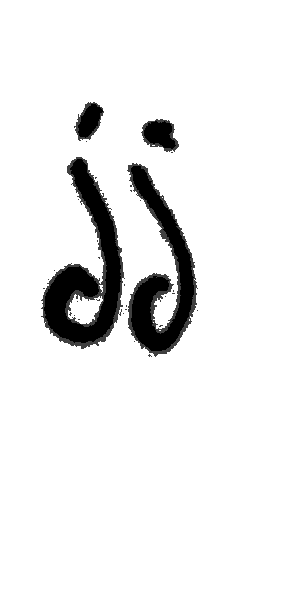

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00022.png


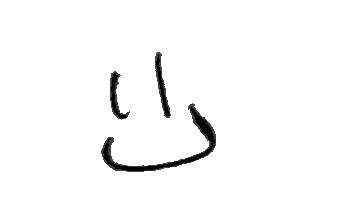

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00023.png


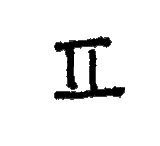

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00024.png


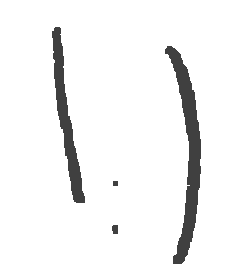

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00025.png


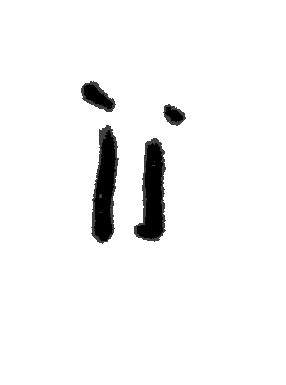

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00026.png


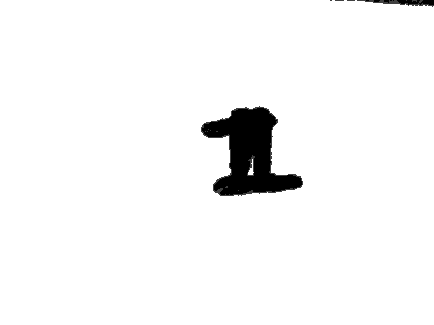

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00027.png


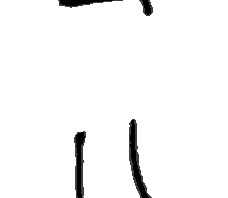

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00028.png


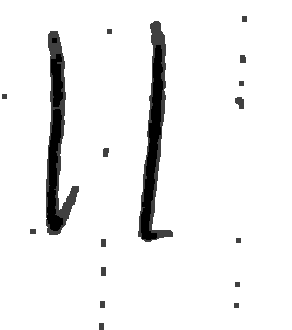

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00029.png


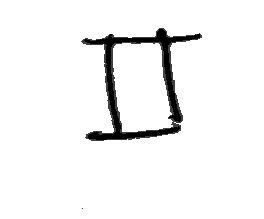

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00030.png


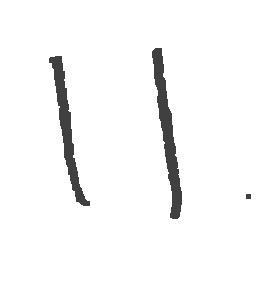

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00031.png


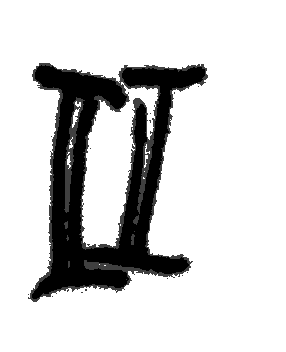

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00032.png


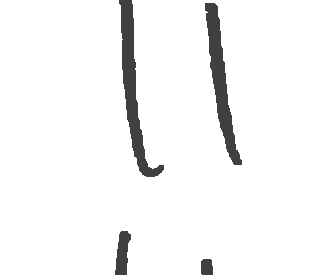

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00033.png


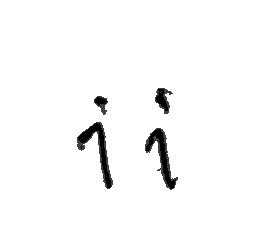

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00034.png


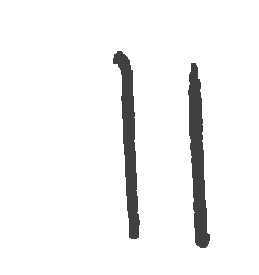

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00035.png


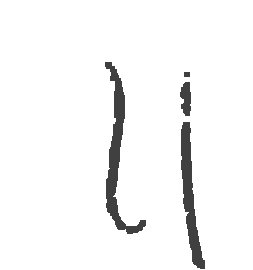

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00036.png


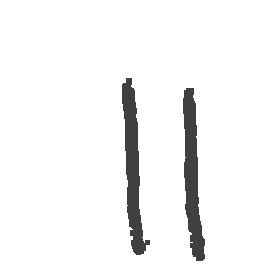

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00037.png


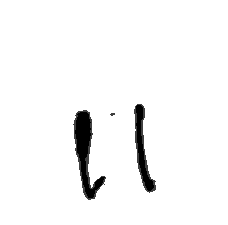

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00038.png


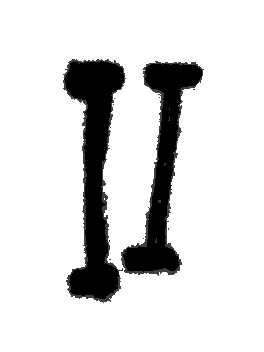

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00039.png


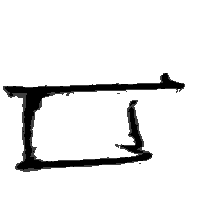

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00040.png


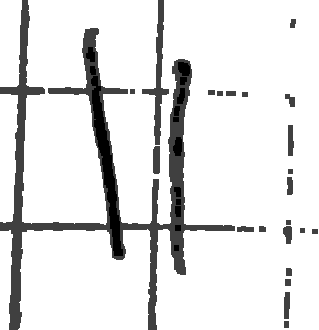

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00041.png


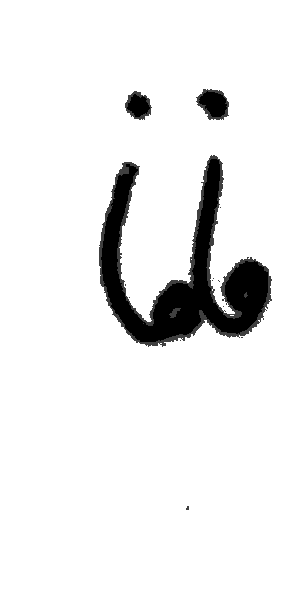

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00042.png


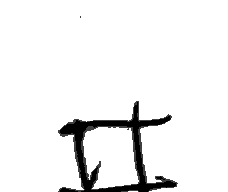

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00043.png


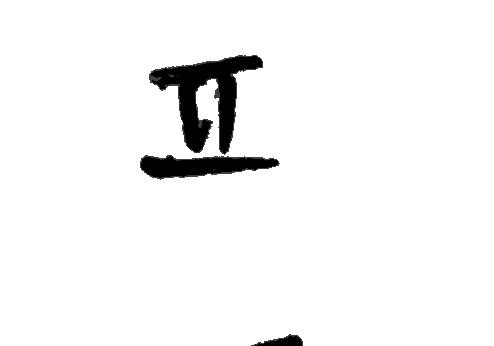

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00044.png


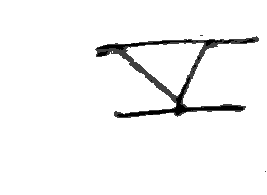

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00045.png


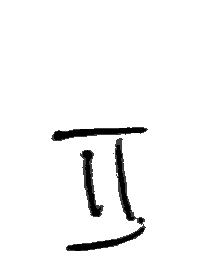

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00046.png


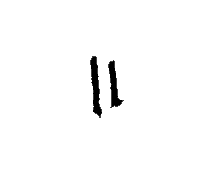

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00047.png


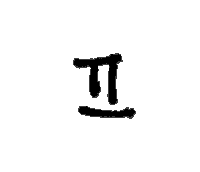

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00048.png


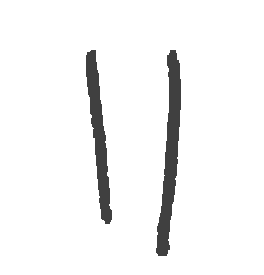

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00049.png


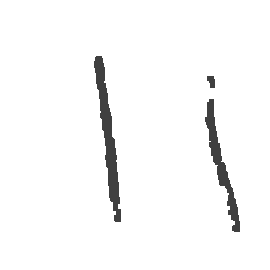

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00050.png


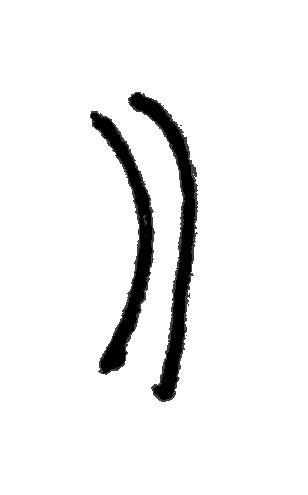

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00051.png


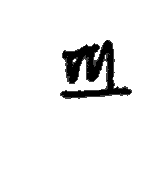

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00052.png


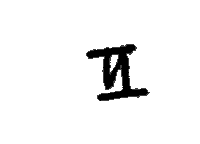

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00053.png


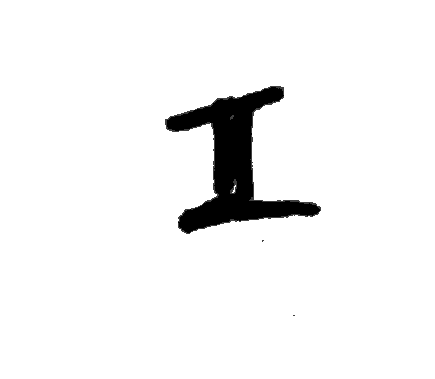

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00054.png


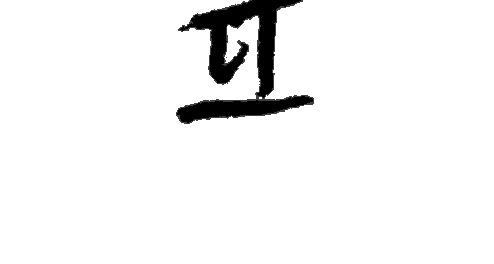

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00055.png


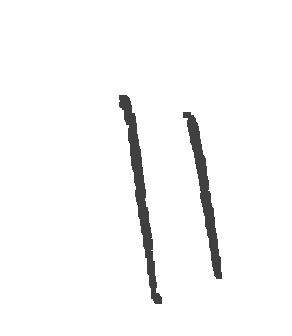

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00056.png


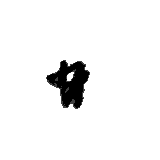

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00057.png


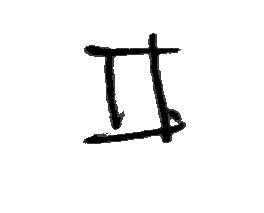

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00058.png


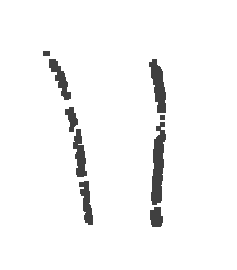

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00059.png


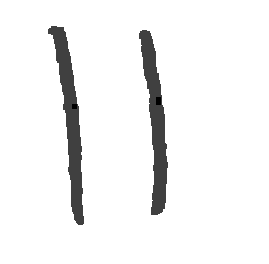

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00060.png


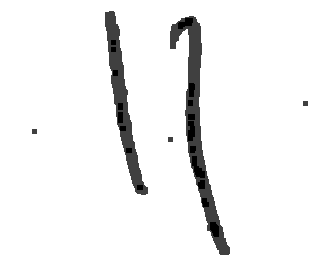

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00061.png


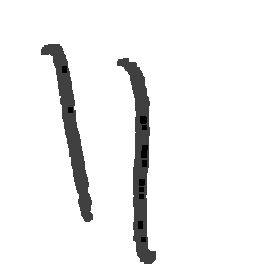

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00062.png


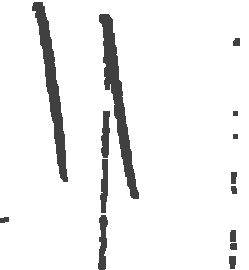

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00063.png


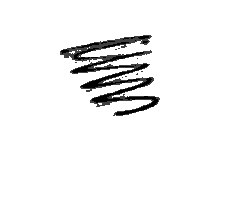

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00064.png


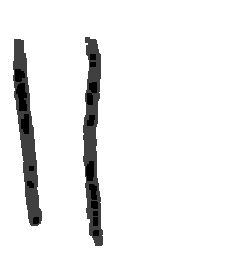

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00065.png


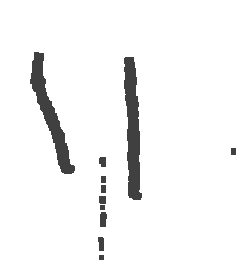

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00066.png


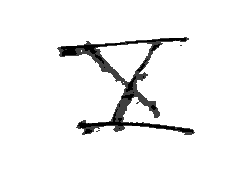

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00067.png


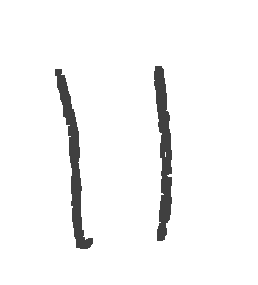

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00068.png


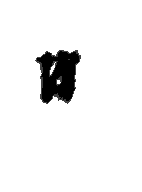

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00069.png


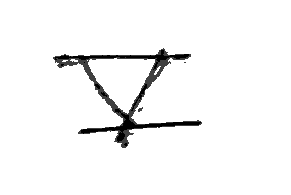

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00070.png


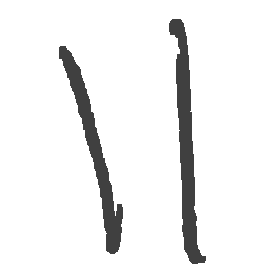

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00071.png


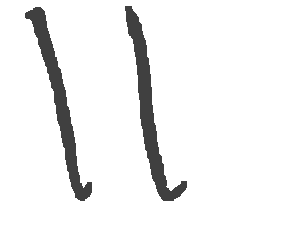

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00072.png


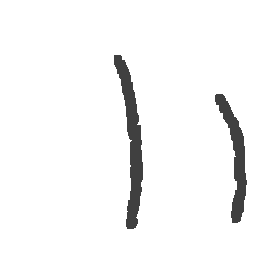

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00073.png


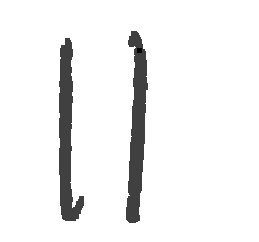

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00074.png


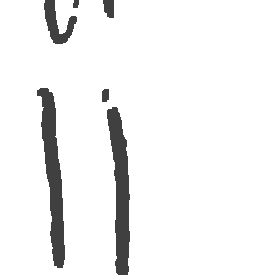

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00075.png


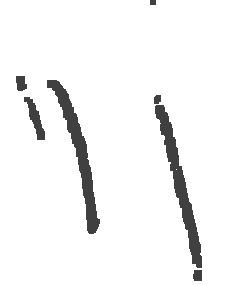

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00076.png


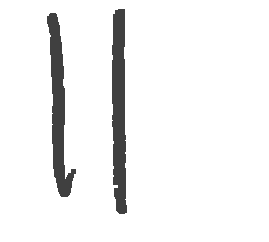

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00077.png


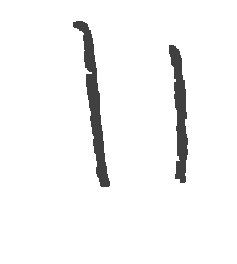

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00078.png


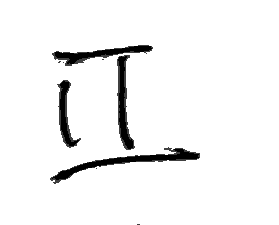

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00079.png


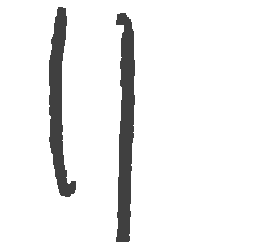

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00080.png


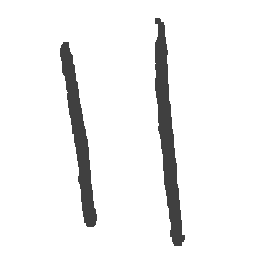

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00081.png


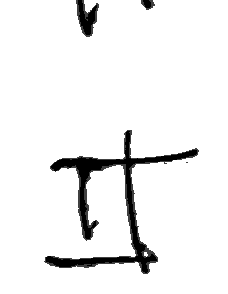

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00082.png


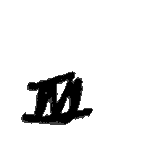

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00083.png


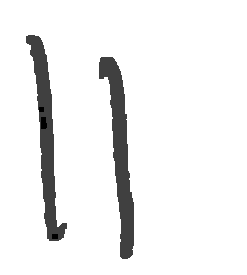

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00084.png


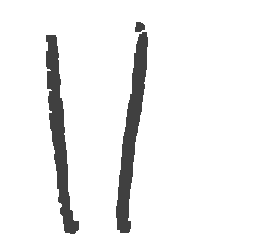

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00085.png


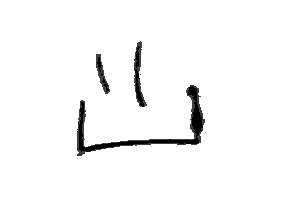

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00086.png


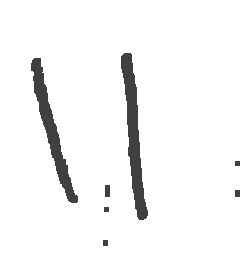

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00087.png


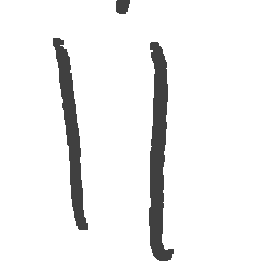

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00088.png


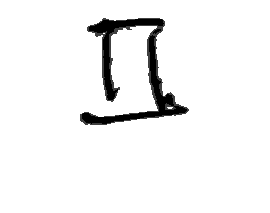

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00089.png


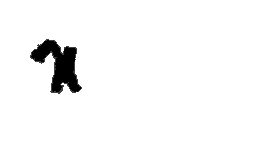

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00090.png


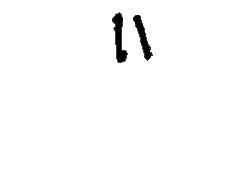

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00091.png


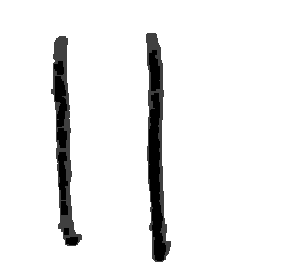

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00092.png


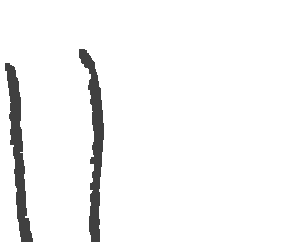

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00093.png


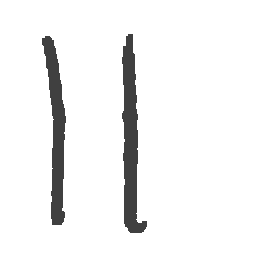

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00094.png


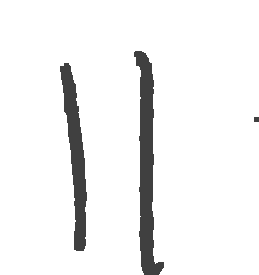

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00095.png


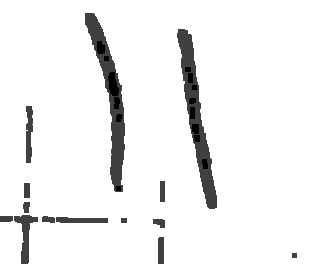

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00096.png


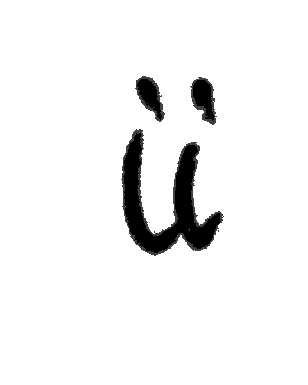

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00097.png


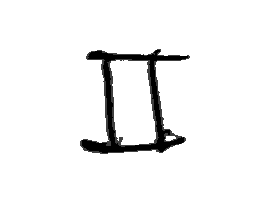

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00098.png


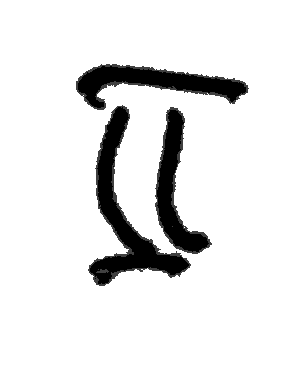

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00099.png


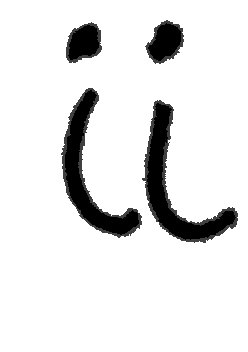

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00100.png


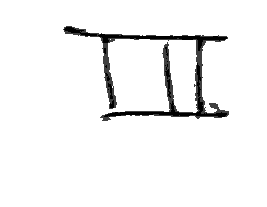

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00101.png


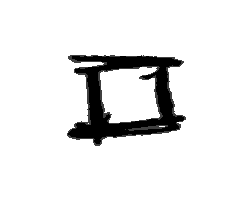

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00102.png


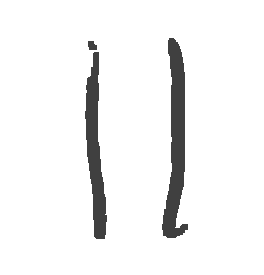

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00103.png


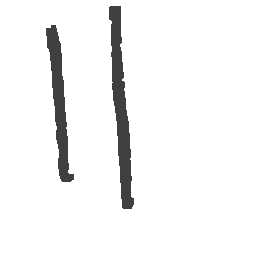

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00104.png


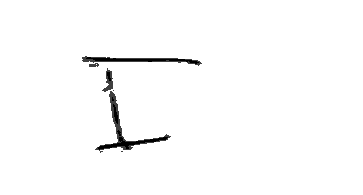

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00105.png


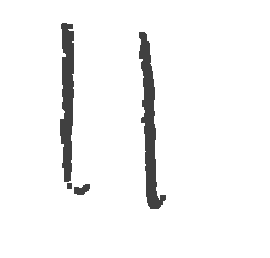

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00106.png


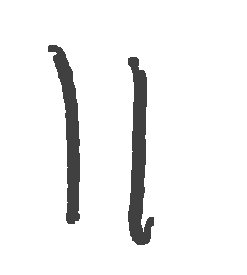

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00107.png


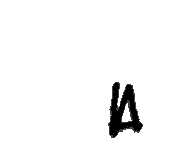

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00108.png


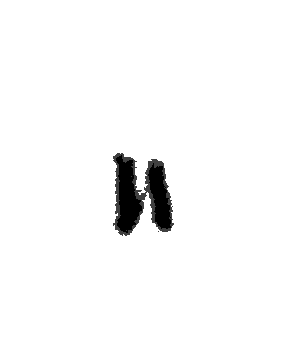

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00109.png


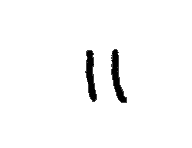

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00110.png


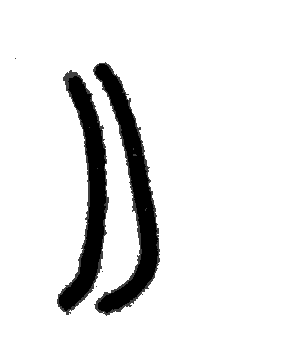

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00111.png


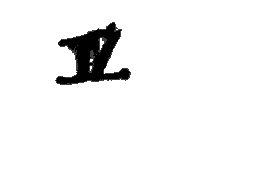

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00112.png


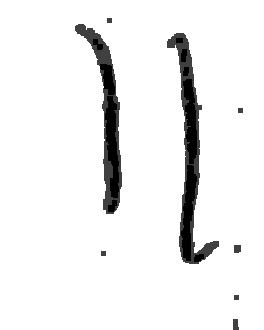

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00113.png


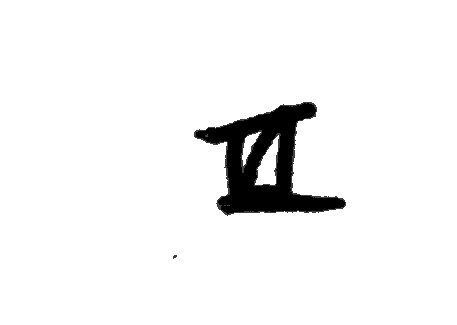

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00114.png


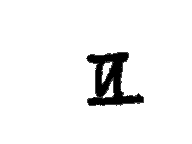

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00115.png


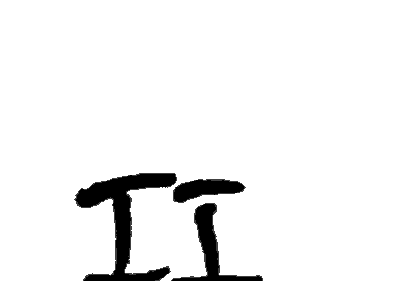

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00116.png


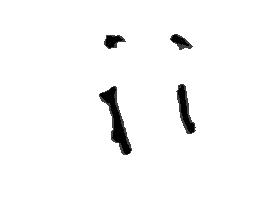

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00117.png


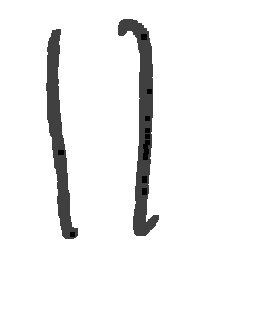

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00118.png


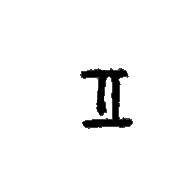

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00119.png


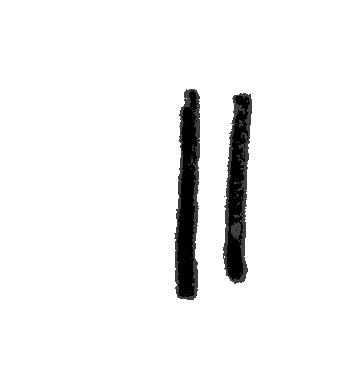

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00120.png


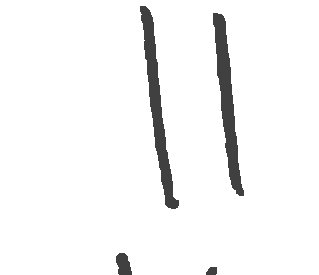

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00121.png


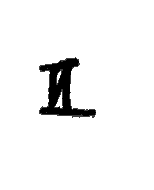

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00122.png


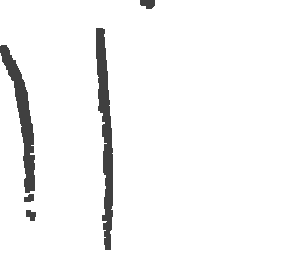

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00123.png


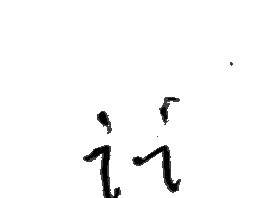

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00124.png


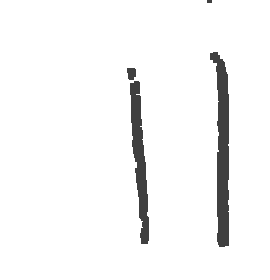

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00125.png


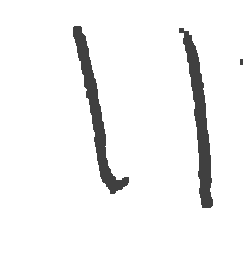

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00126.png


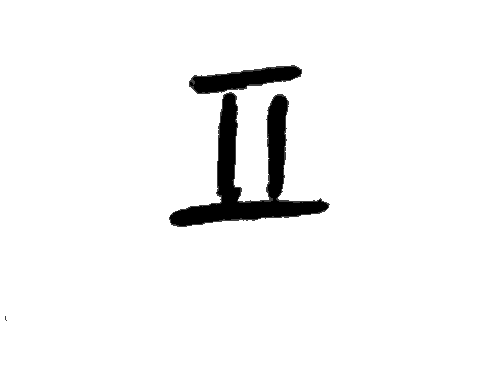

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00127.png


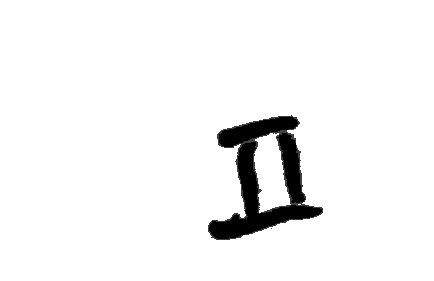

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00128.png


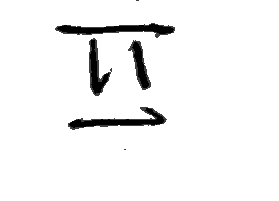

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00129.png


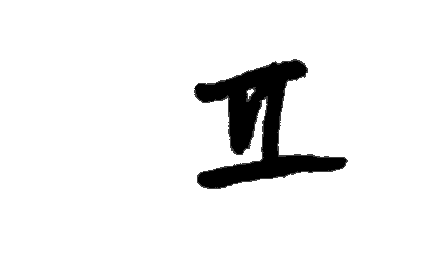

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00130.png


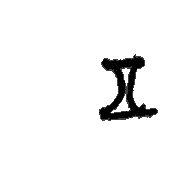

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00131.png


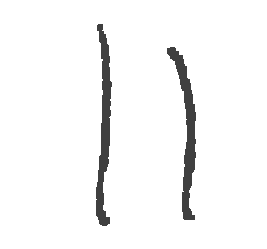

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00132.png


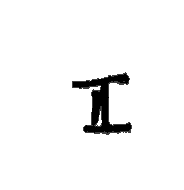

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00133.png


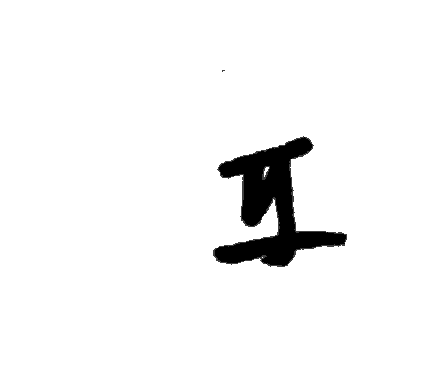

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00134.png


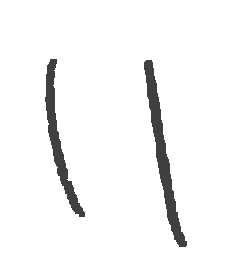

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00135.png


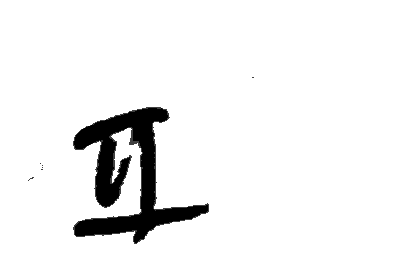

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00136.png


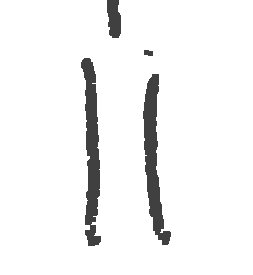

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00137.png


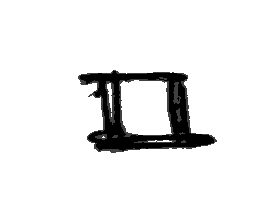

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00138.png


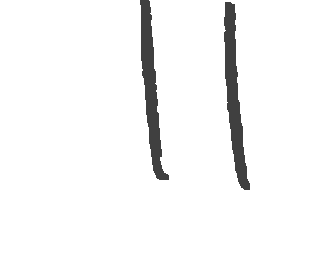

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00139.png


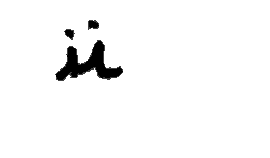

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00140.png


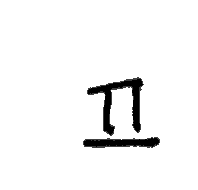

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00141.png


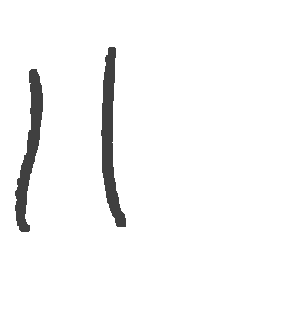

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00142.png


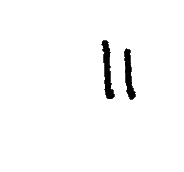

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00143.png


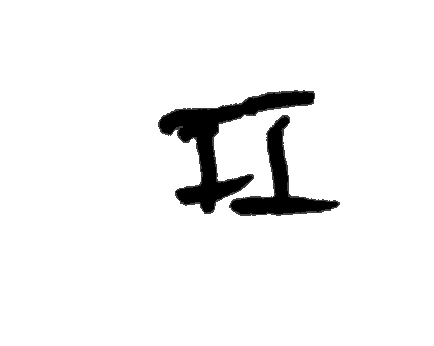

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00144.png


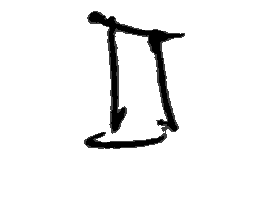

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00145.png


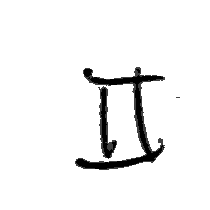

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00146.png


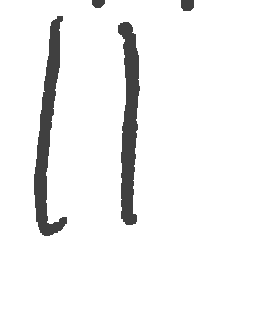

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00147.png


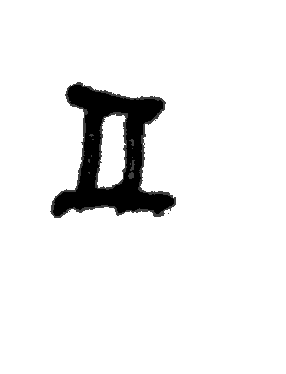

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00148.png


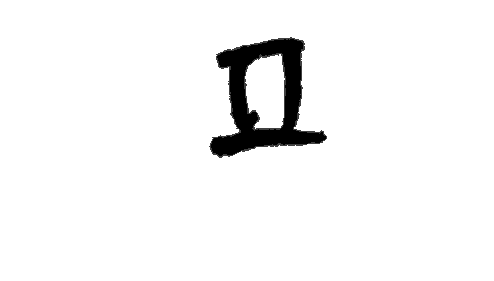

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00149.png


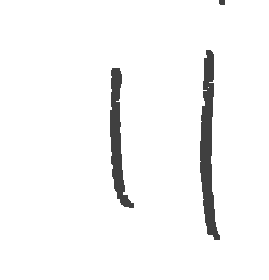

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00150.png


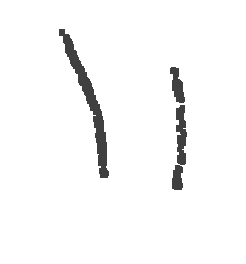

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00151.png


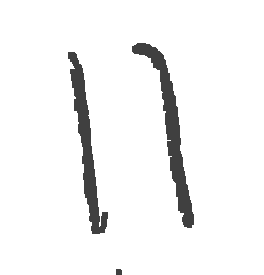

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00152.png


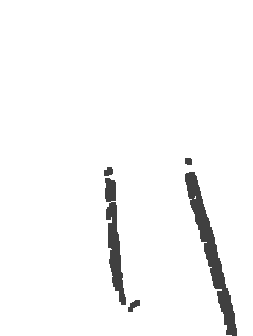

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00153.png


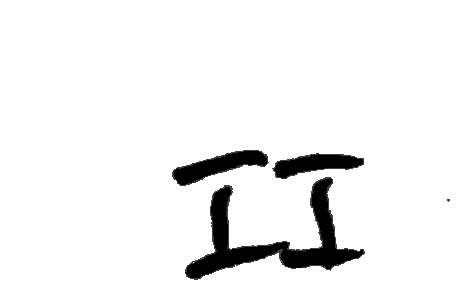

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00154.png


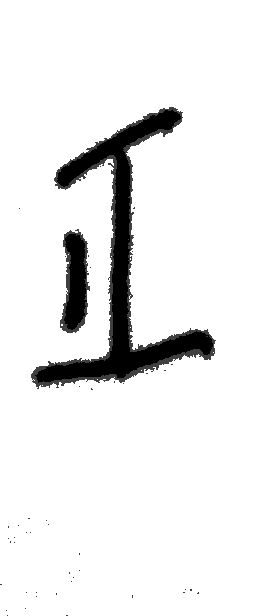

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00155.png


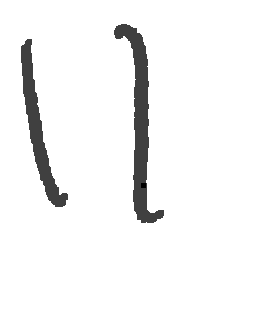

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00156.png


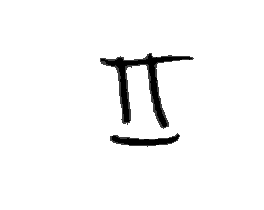

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00157.png


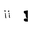

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00158.png


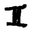

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00159.png


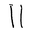

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00160.png


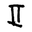

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00161.png


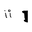

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00162.png


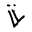

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00163.png


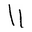

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00164.png


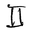

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00165.png


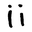

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00166.png


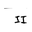

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00167.png


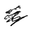

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00168.png


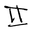

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00169.png


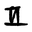

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00170.png


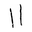

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00171.png


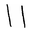

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00172.png


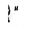

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00173.png


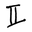

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00174.png


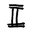

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00175.png


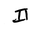

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00176.png


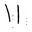

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00177.png


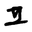

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00178.png


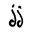

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00179.png


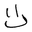

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00180.png


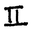

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00181.png


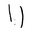

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00182.png


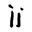

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00183.png


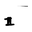

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00184.png


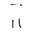

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00185.png


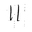

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00186.png


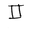

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00187.png


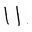

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00188.png


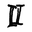

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00189.png


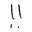

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00190.png


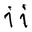

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00191.png


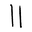

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00192.png


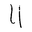

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00193.png


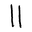

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00194.png


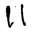

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00195.png


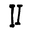

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00196.png


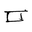

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00197.png


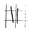

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00198.png


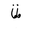

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00199.png


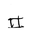

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00200.png


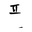

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00201.png


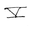

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00202.png


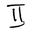

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00203.png


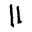

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00204.png


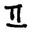

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00205.png


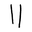

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00206.png


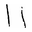

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00207.png


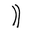

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00208.png


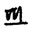

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00209.png


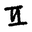

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00210.png


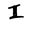

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00211.png


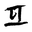

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00212.png


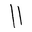

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00213.png


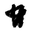

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00214.png


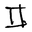

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00215.png


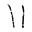

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00216.png


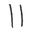

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00217.png


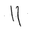

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00218.png


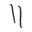

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00219.png


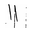

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00220.png


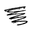

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00221.png


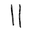

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00222.png


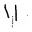

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00223.png


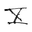

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00224.png


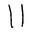

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00225.png


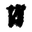

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00226.png


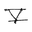

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00227.png


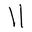

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00228.png


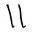

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00229.png


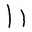

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00230.png


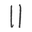

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00231.png


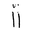

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00232.png


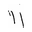

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00233.png


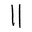

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00234.png


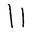

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00235.png


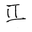

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00236.png


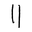

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00237.png


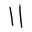

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00238.png


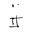

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00239.png


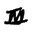

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00240.png


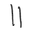

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00241.png


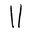

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00242.png


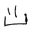

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00243.png


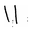

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00244.png


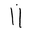

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00245.png


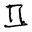

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00246.png


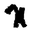

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00247.png


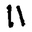

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00248.png


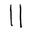

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00249.png


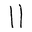

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00250.png


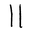

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00251.png


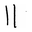

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00252.png


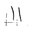

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00253.png


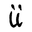

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00254.png


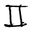

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00255.png


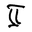

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00256.png


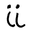

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00257.png


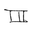

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00258.png


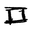

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00259.png


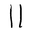

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00260.png


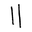

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00261.png


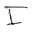

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00262.png


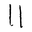

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00263.png


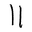

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00264.png


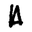

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00265.png


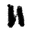

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00266.png


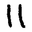

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00267.png


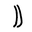

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00268.png


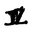

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00269.png


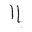

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00270.png


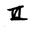

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00271.png


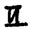

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00272.png


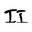

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00273.png


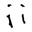

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00274.png


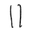

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00275.png


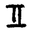

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00276.png


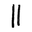

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00277.png


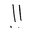

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00278.png


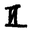

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00279.png


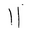

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00280.png


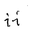

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00281.png


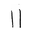

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00282.png


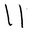

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00283.png


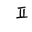

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00284.png


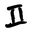

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00285.png


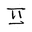

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00286.png


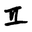

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00287.png


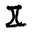

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00288.png


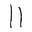

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00289.png


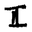

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00290.png


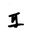

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00291.png


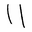

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00292.png


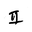

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00293.png


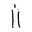

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00294.png


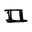

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00295.png


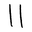

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00296.png


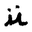

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00297.png


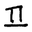

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00298.png


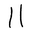

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00299.png


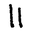

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00300.png


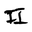

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00301.png


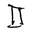

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00302.png


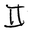

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00303.png


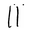

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00304.png


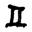

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00305.png


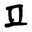

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00306.png


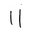

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00307.png


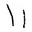

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00308.png


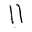

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00309.png


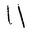

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00310.png


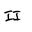

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00311.png


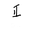

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00312.png


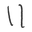

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00313.png


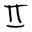

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00314.png


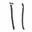

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00315.png


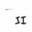

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00316.png


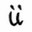

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00317.png


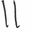

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00318.png


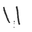

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00319.png


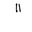

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00320.png


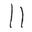

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00321.png


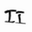

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00322.png


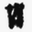

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00323.png


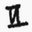

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00324.png


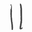

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00325.png


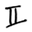

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00326.png


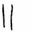

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00327.png


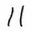

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00328.png


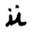

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00329.png


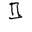

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00330.png


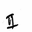

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00331.png


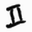

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00332.png


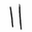

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00333.png


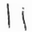

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00334.png


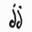

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00335.png


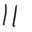

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00336.png


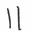

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00337.png


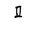

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00338.png


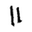

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00339.png


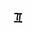

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00340.png


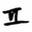

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00341.png


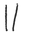

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00342.png


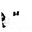

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00343.png


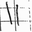

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00344.png


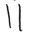

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00345.png


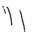

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00346.png


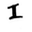

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00347.png


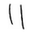

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00348.png


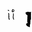

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00349.png


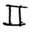

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00350.png


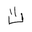

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00351.png


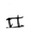

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00352.png


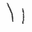

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00353.png


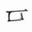

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00354.png


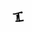

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00355.png


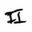

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00356.png


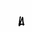

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00357.png


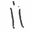

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00358.png


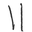

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00359.png


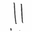

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00360.png


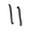

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00361.png


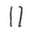

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00362.png


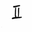

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00363.png


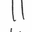

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00364.png


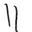

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00365.png


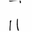

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00366.png


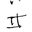

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00367.png


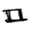

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00368.png


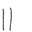

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00369.png


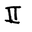

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00370.png


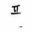

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00371.png


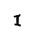

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00372.png


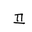

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00373.png


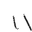

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00374.png


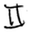

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00375.png


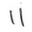

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00376.png


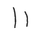

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00377.png


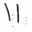

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00378.png


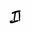

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00379.png


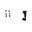

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00380.png


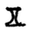

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00381.png


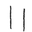

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00382.png


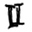

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00383.png


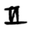

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00384.png


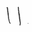

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00385.png


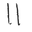

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00386.png


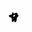

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00387.png


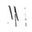

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00388.png


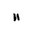

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00389.png


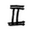

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00390.png


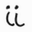

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00391.png


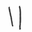

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00392.png


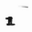

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00393.png


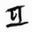

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00394.png


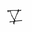

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00395.png


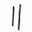

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00396.png


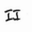

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00397.png


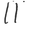

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00398.png


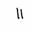

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00399.png


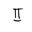

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00400.png


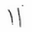

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00401.png


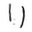

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00402.png


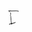

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00403.png


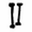

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00404.png


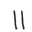

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00405.png


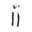

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00406.png


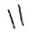

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00407.png


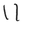

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00408.png


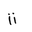

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00409.png


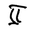

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00410.png


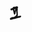

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00411.png


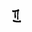

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00412.png


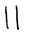

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00413.png


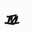

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00414.png


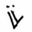

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00415.png


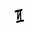

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00416.png


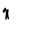

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00417.png


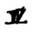

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00418.png


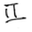

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00419.png


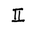

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00420.png


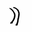

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00421.png


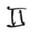

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00422.png


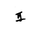

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00423.png


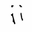

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00424.png


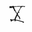

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00425.png


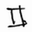

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00426.png


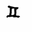

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00427.png


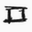

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00428.png


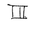

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00429.png


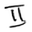

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00430.png


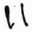

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00431.png


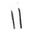

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00432.png


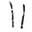

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00433.png


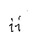

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00434.png


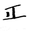

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00435.png


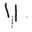

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00436.png


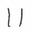

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00437.png


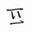

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00438.png


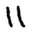

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00439.png


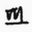

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00440.png


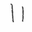

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00441.png


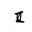

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00442.png


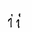

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00443.png


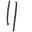

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00444.png


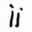

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00445.png


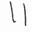

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00446.png


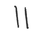

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00447.png


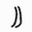

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00448.png


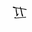

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00449.png


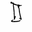

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00450.png


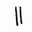

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00451.png


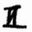

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00452.png


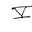

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00453.png


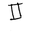

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00454.png


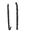

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00455.png


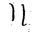

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00456.png


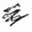

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00457.png


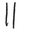

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00458.png


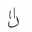

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00459.png


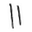

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00460.png


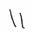

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00461.png


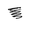

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00462.png


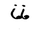

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00463.png


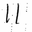

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00464.png


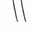

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00465.png


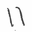

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00466.png


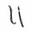

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00467.png


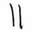

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00468.png


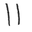

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00469.png


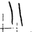

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00470.png


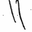

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00471.png


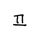

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00472.png


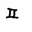

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00473.png


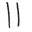

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00474.png


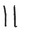

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00475.png


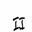

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00476.png


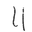

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00477.png


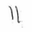

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00478.png


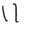

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00479.png


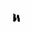

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00480.png


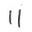

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00481.png


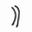

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00482.png


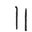

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00483.png


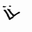

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00484.png


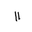

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00485.png


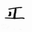

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00486.png


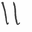

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00487.png


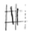

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00488.png


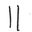

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00489.png


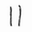

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00490.png


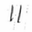

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00491.png


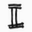

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00492.png


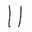

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00493.png


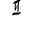

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00494.png


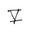

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00495.png


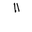

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00496.png


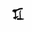

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00497.png


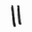

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00498.png


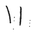

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00499.png


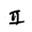

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00500.png


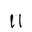

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00501.png


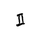

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00502.png


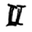

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00503.png


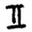

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00504.png


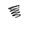

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00505.png


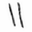

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00506.png


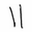

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00507.png


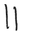

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00508.png


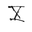

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00509.png


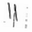

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00510.png


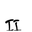

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00511.png


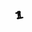

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00512.png


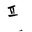

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00513.png


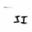

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00514.png


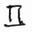

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00515.png


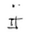

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00516.png


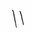

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00517.png


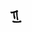

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00518.png


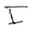

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00519.png


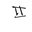

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00520.png


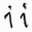

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00521.png


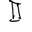

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00522.png


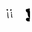

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00523.png


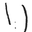

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00524.png


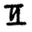

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00525.png


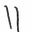

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00526.png


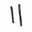

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00527.png


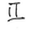

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00528.png


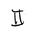

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00529.png


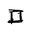

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00530.png


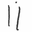

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00531.png


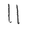

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00532.png


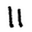

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00533.png


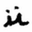

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00534.png


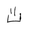

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00535.png


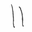

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00536.png


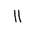

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00537.png


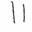

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00538.png


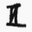

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00539.png


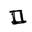

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00540.png


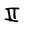

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00541.png


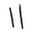

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00542.png


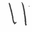

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00543.png


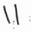

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00544.png


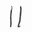

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00545.png


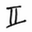

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00546.png


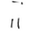

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00547.png


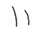

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00548.png


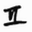

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00549.png


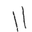

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00550.png


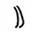

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00551.png


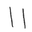

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00552.png


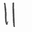

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00553.png


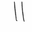

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00554.png


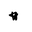

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00555.png


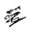

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00556.png


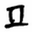

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00557.png


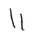

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00558.png


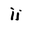

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00559.png


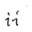

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00560.png


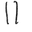

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00561.png


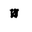

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00562.png


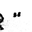

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00563.png


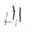

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00564.png


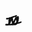

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00565.png


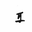

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00566.png


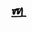

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00567.png


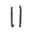

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00568.png


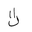

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00569.png


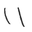

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00570.png


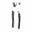

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00571.png


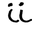

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00572.png


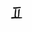

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00573.png


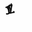

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00574.png


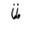

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00575.png


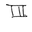

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00576.png


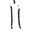

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00577.png


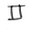

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00578.png


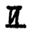

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00579.png


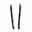

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00580.png


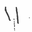

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00581.png


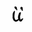

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00582.png


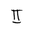

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00583.png


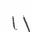

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00584.png


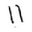

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00585.png


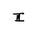

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00586.png


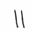

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00587.png


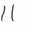

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00588.png


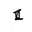

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00589.png


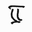

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00590.png


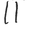

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00591.png


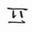

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00592.png


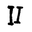

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00593.png


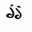

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00594.png


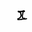

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00595.png


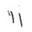

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00596.png


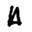

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00597.png


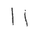

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00598.png


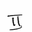

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00599.png


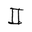

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00600.png


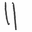

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00601.png


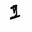

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00602.png


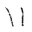

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00603.png


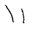

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00604.png


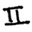

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00605.png


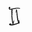

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00606.png


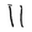

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00607.png


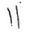

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00608.png


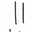

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00609.png


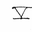

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00610.png


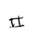

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00611.png


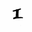

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00612.png


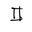

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00613.png


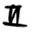

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00614.png


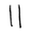

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00615.png


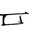

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00616.png


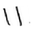

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00617.png


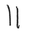

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00618.png


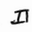

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00619.png


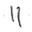

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00620.png


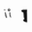

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00621.png


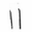

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00622.png


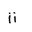

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00623.png


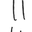

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00624.png


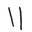

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00625.png


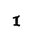

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00626.png


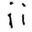

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00627.png


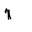

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00628.png


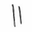

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00629.png


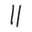

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00630.png


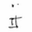

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00631.png


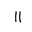

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00632.png


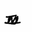

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00633.png


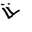

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00634.png


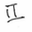

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00635.png


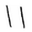

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00636.png


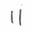

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00637.png


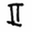

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00638.png


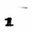

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00639.png


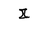

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00640.png


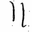

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00641.png


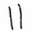

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00642.png


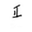

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00643.png


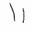

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00644.png


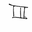

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00645.png


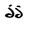

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00646.png


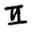

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00647.png


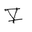

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00648.png


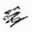

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00649.png


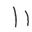

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00650.png


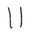

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00651.png


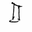

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00652.png


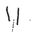

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00653.png


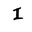

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00654.png


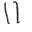

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00655.png


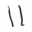

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00656.png


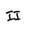

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00657.png


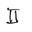

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00658.png


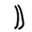

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00659.png


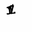

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00660.png


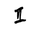

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00661.png


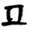

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00662.png


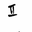

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00663.png


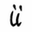

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00664.png


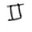

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00665.png


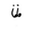

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00666.png


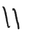

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00667.png


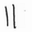

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00668.png


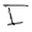

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00669.png


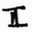

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00670.png


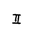

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00671.png


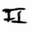

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00672.png


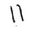

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00673.png


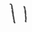

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00674.png


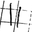

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00675.png


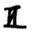

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00676.png


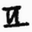

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00677.png


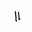

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00678.png


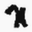

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00679.png


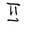

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00680.png


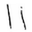

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00681.png


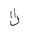

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00682.png


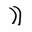

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00683.png


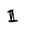

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00684.png


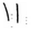

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00685.png


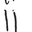

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00686.png


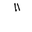

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00687.png


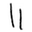

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00688.png


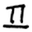

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00689.png


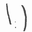

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00690.png


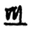

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00691.png


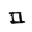

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00692.png


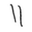

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00693.png


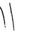

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00694.png


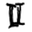

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00695.png


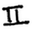

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00696.png


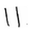

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00697.png


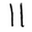

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00698.png


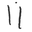

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00699.png


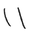

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00700.png


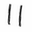

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00701.png


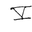

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00702.png


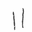

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00703.png


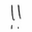

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00704.png


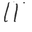

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00705.png


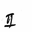

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00706.png


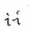

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00707.png


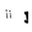

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00708.png


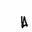

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00709.png


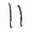

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00710.png


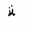

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00711.png


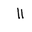

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00712.png


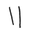

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00713.png


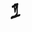

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00714.png


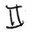

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00715.png


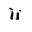

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00716.png


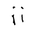

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00717.png


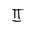

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00718.png


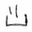

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00719.png


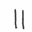

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00720.png


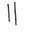

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00721.png


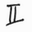

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00722.png


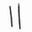

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00723.png


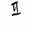

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00724.png


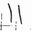

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00725.png


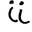

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00726.png


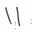

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00727.png


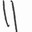

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00728.png


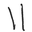

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00729.png


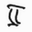

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00730.png


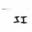

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00731.png


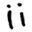

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00732.png


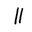

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00733.png


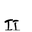

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00734.png


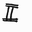

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00735.png


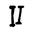

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00736.png


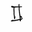

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00737.png


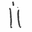

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00738.png


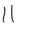

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00739.png


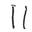

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00740.png


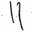

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00741.png


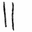

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00742.png


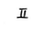

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00743.png


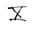

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00744.png


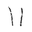

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00745.png


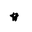

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00746.png


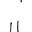

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00747.png


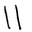

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00748.png


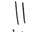

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00749.png


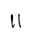

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00750.png


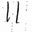

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00751.png


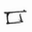

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00752.png


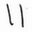

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00753.png


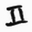

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00754.png


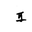

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00755.png


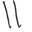

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00756.png


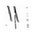

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00757.png


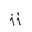

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00758.png


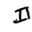

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00759.png


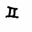

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00760.png


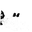

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00761.png


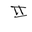

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00762.png


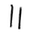

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00763.png


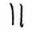

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00764.png


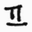

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00765.png


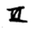

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00766.png


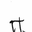

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00767.png


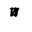

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00768.png


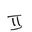

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00769.png


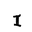

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00770.png


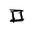

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00771.png


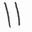

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00772.png


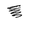

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00773.png


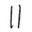

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00774.png


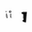

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00775.png


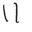

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00776.png


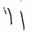

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00777.png


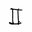

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00778.png


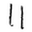

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00779.png


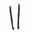

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00780.png


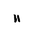

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00781.png


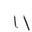

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00782.png


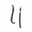

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00783.png


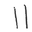

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00784.png


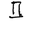

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00785.png


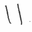

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00786.png


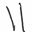

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00787.png


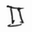

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00788.png


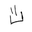

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00789.png


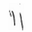

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00790.png


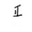

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00791.png


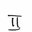

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00792.png


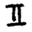

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00793.png


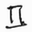

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00794.png


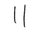

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00795.png


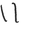

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00796.png


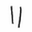

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00797.png


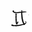

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00798.png


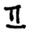

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00799.png


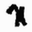

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00800.png


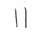

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00801.png


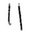

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00802.png


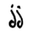

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00803.png


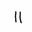

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00804.png


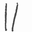

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00805.png


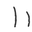

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00806.png


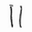

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00807.png


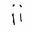

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00808.png


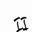

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00809.png


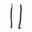

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00810.png


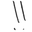

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00811.png


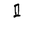

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00812.png


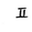

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00813.png


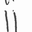

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00814.png


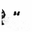

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00815.png


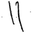

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00816.png


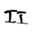

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00817.png


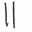

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00818.png


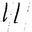

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00819.png


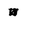

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00820.png


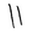

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00821.png


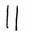

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00822.png


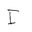

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00823.png


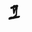

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00824.png


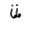

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00825.png


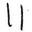

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00826.png


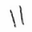

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00827.png


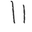

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00828.png


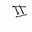

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00829.png


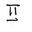

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00830.png


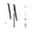

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00831.png


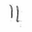

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00832.png


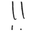

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00833.png


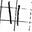

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00834.png


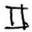

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00835.png


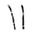

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00836.png


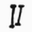

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00837.png


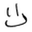

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00838.png


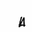

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00839.png


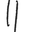

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00840.png


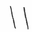

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00841.png


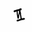

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00842.png


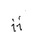

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00843.png


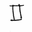

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00844.png


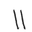

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00845.png


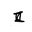

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00846.png


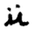

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00847.png


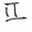

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00848.png


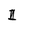

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00849.png


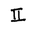

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00850.png


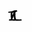

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00851.png


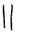

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00852.png


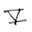

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00853.png


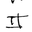

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00854.png


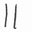

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00855.png


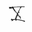

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00856.png


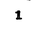

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00857.png


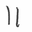

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00858.png


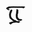

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00859.png


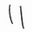

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00860.png


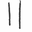

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00861.png


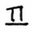

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00862.png


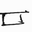

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00863.png


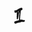

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00864.png


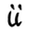

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00865.png


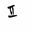

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00866.png


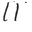

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00867.png


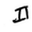

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00868.png


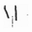

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00869.png


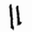

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00870.png


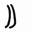

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00871.png


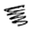

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00872.png


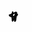

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00873.png


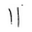

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00874.png


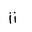

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00875.png


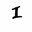

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00876.png


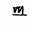

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00877.png


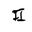

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00878.png


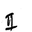

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00879.png


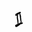

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00880.png


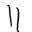

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00881.png


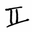

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00882.png


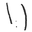

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00883.png


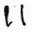

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00884.png


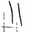

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00885.png


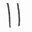

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00886.png


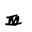

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00887.png


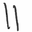

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00888.png


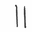

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00889.png


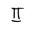

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00890.png


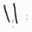

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00891.png


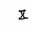

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00892.png


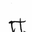

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00893.png


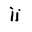

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00894.png


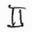

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00895.png


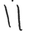

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00896.png


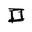

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00897.png


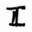

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00898.png


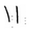

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00899.png


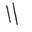

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00900.png


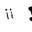

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00901.png


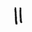

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00902.png


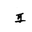

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00903.png


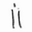

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00904.png


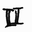

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00905.png


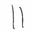

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00906.png


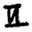

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00907.png


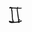

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00908.png


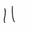

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00909.png


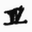

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00910.png


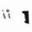

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00911.png


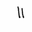

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00912.png


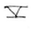

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00913.png


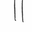

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00914.png


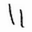

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00915.png


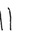

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00916.png


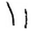

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00917.png


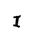

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00918.png


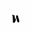

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00919.png


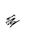

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00920.png


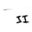

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00921.png


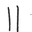

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00922.png


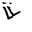

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00923.png


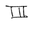

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00924.png


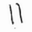

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00925.png


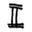

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00926.png


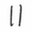

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00927.png


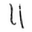

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00928.png


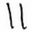

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00929.png


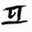

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00930.png


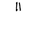

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00931.png


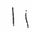

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00932.png


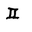

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00933.png


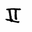

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00934.png


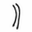

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00935.png


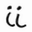

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00936.png


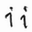

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00937.png


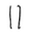

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00938.png


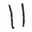

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00939.png


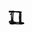

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00940.png


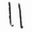

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00941.png


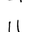

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00942.png


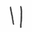

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00943.png


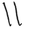

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00944.png


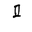

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00945.png


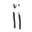

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00946.png


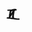

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00947.png


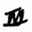

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00948.png


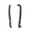

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00949.png


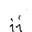

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00950.png


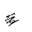

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00951.png


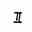

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00952.png


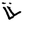

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00953.png


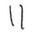

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00954.png


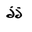

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00955.png


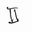

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00956.png


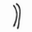

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00957.png


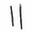

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00958.png


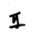

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00959.png


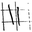

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00960.png


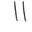

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00961.png


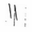

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00962.png


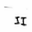

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00963.png


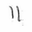

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00964.png


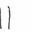

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00965.png


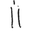

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00966.png


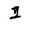

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00967.png


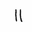

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00968.png


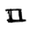

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00969.png


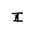

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00970.png


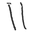

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00971.png


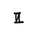

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/ii/00972.png


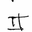

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00000.png


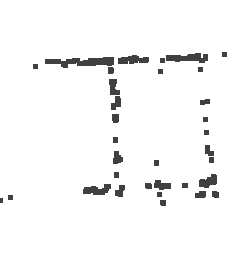

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00001.png


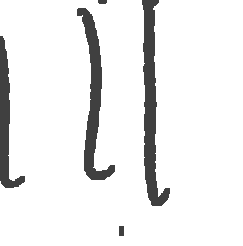

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00002.png


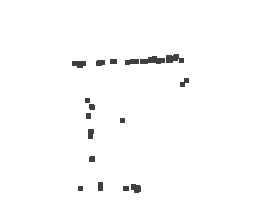

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00003.png


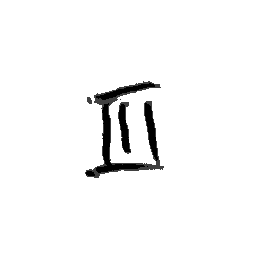

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00004.png


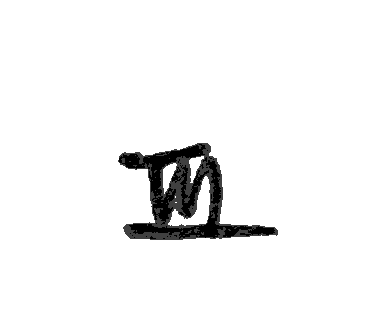

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00005.png


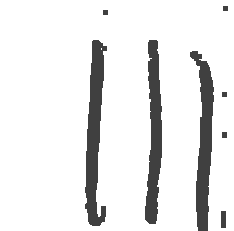

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00006.png


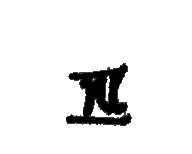

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00007.png


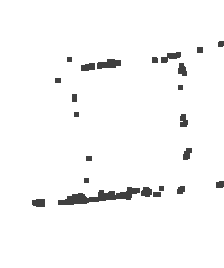

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00008.png


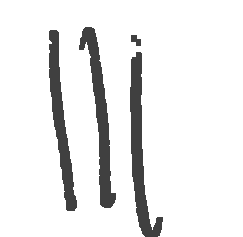

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00009.png


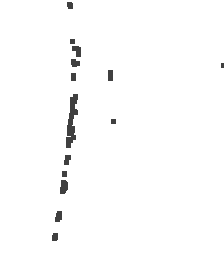

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00010.png


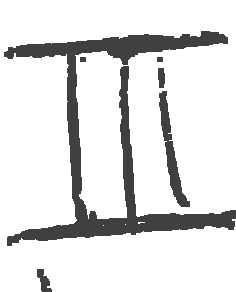

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00011.png


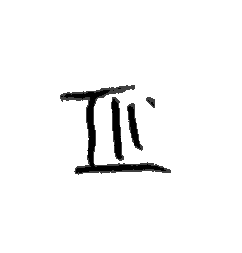

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00012.png


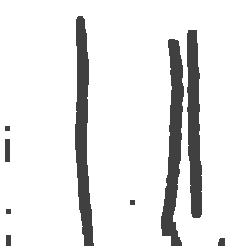

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00013.png


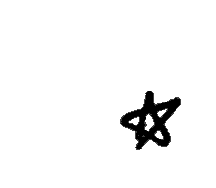

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00014.png


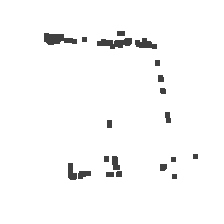

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00015.png


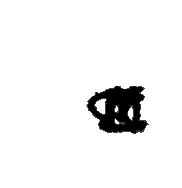

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00016.png


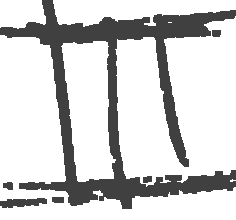

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00017.png


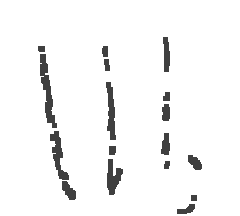

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00018.png


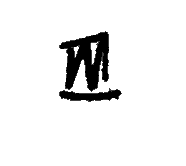

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00019.png


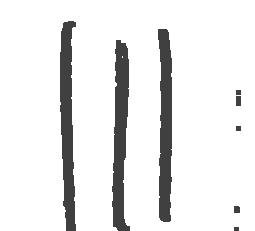

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00020.png


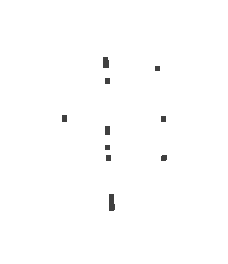

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00021.png


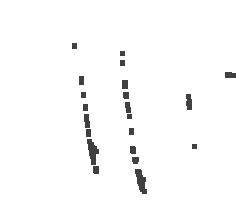

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00022.png


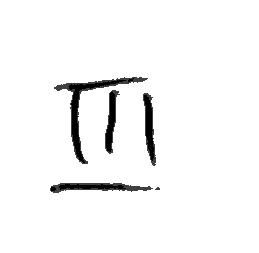

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00023.png


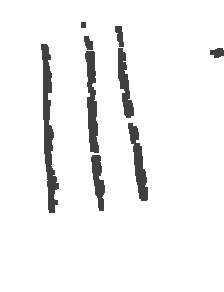

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00024.png


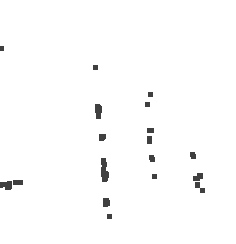

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00025.png


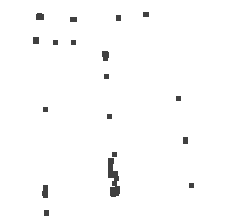

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00026.png


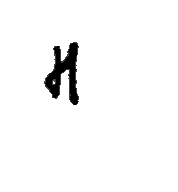

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00027.png


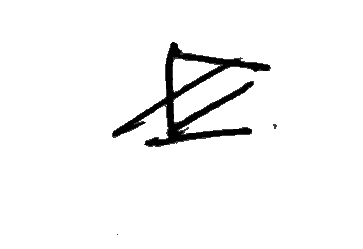

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00028.png


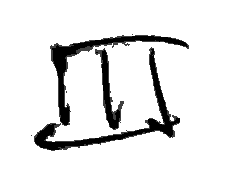

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00029.png


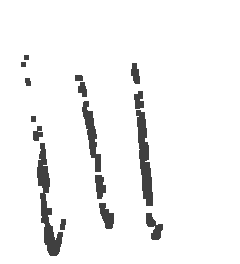

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00030.png


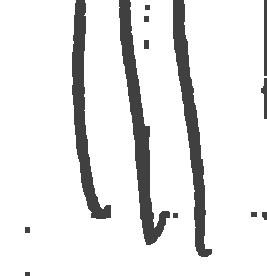

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00031.png


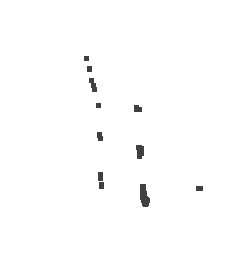

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00032.png


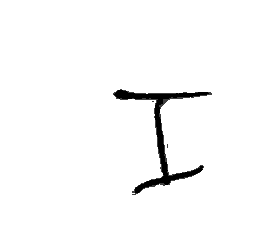

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00033.png


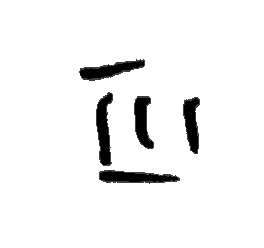

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00034.png


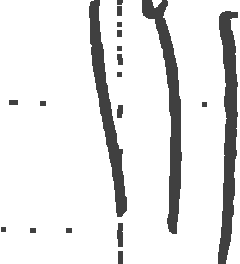

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00035.png


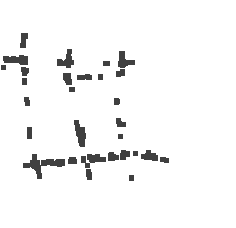

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00036.png


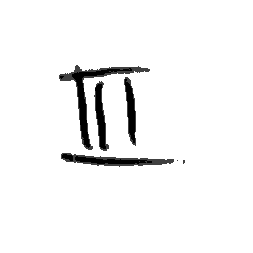

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00037.png


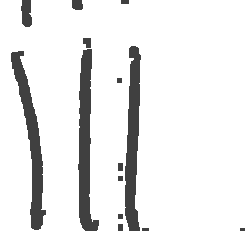

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00038.png


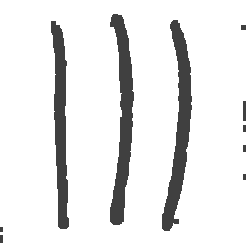

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00039.png


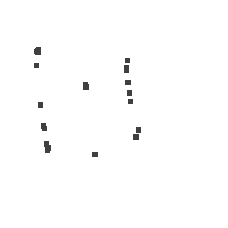

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00040.png


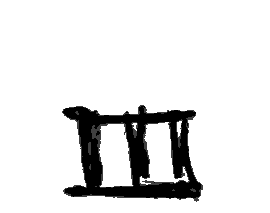

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00041.png


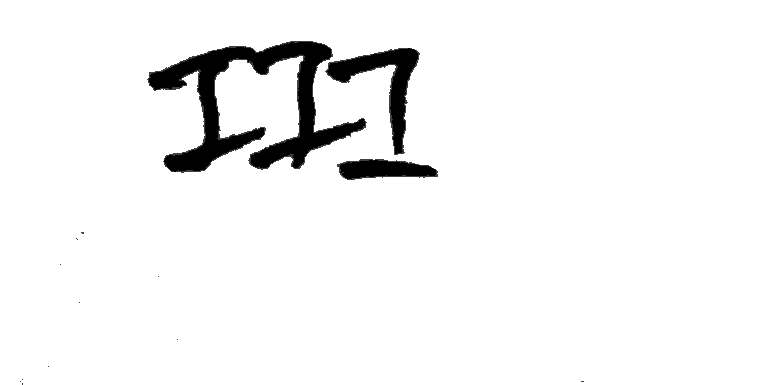

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00042.png


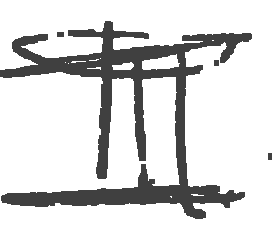

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00043.png


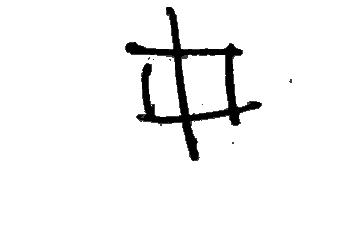

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00044.png


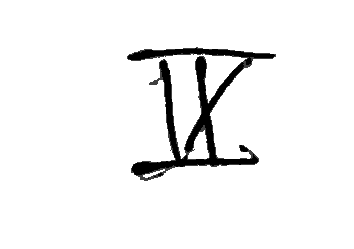

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00045.png


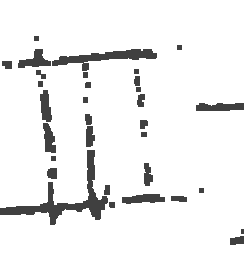

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00046.png


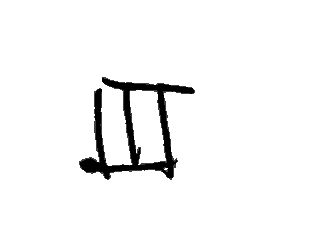

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00047.png


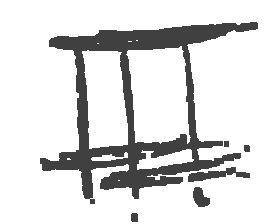

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00048.png


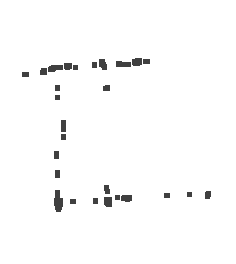

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00049.png


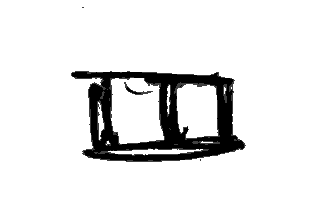

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00050.png


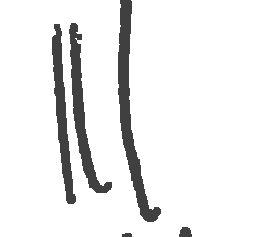

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00051.png


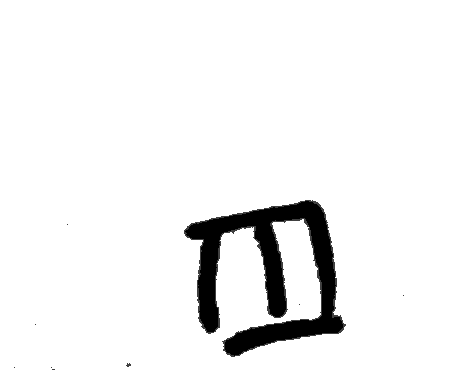

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00052.png


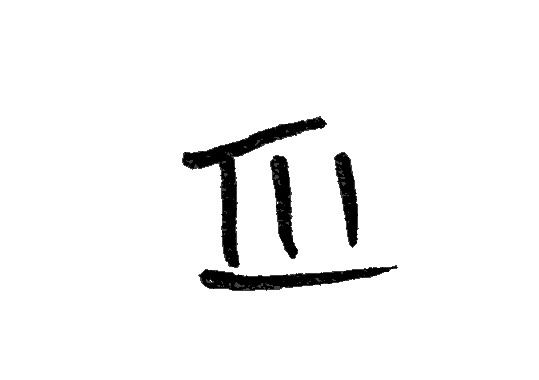

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00053.png


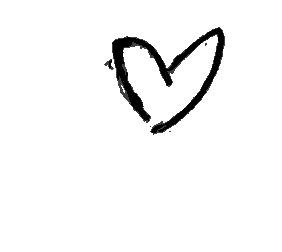

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00054.png


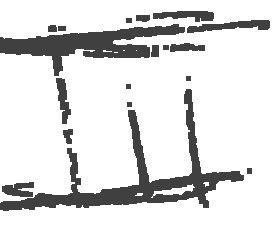

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00055.png


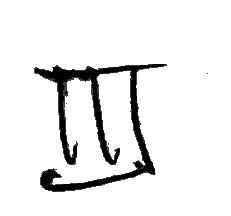

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00056.png


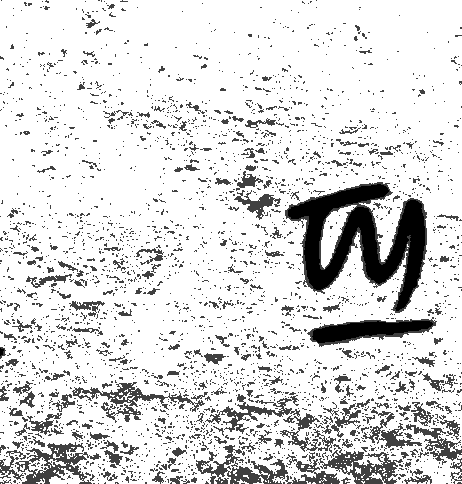

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00057.png


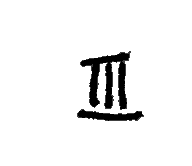

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00058.png


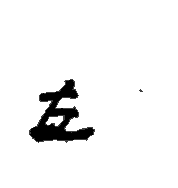

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00059.png


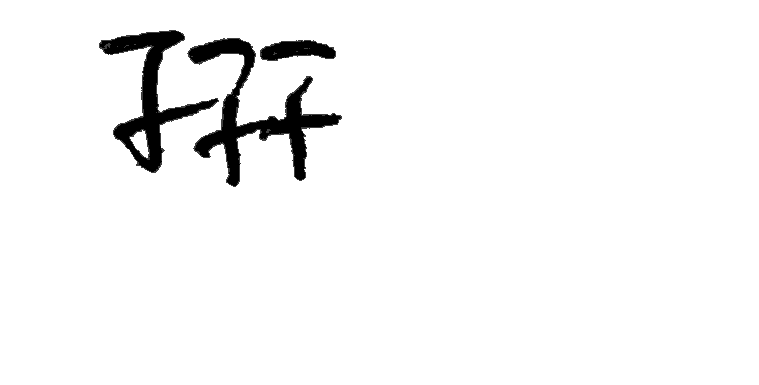

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00060.png


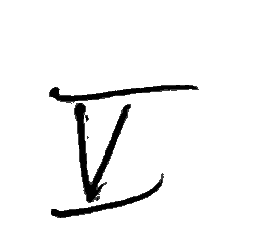

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00061.png


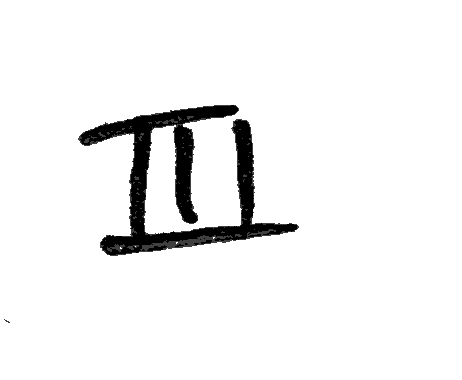

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00062.png


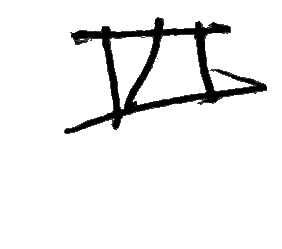

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00063.png


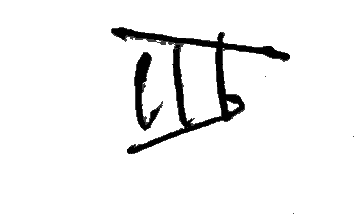

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00064.png


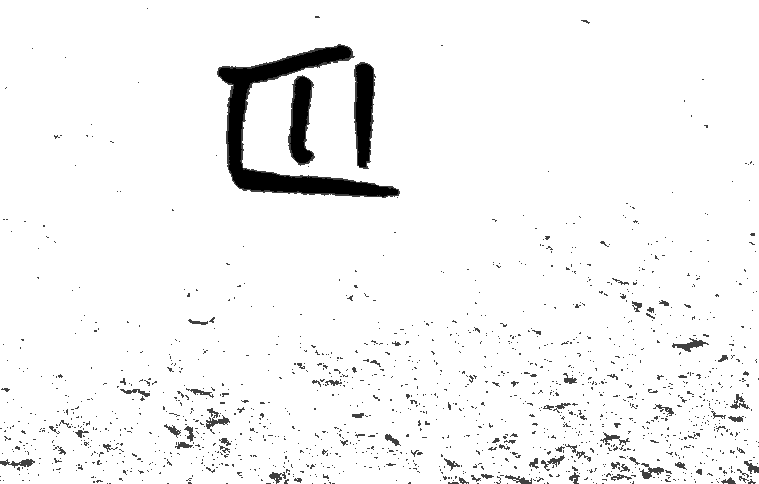

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00065.png


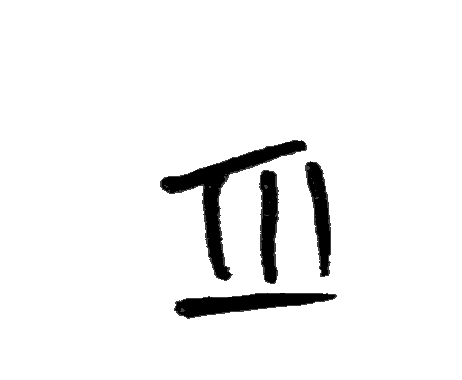

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00066.png


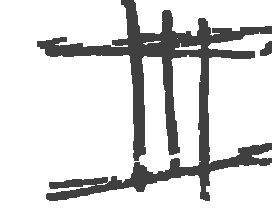

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00067.png


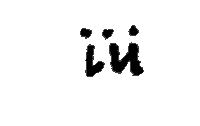

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00068.png


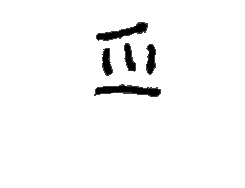

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00069.png


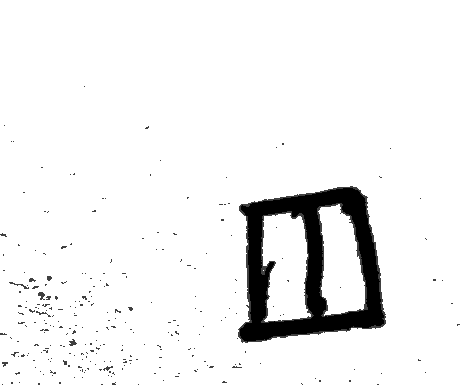

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00070.png


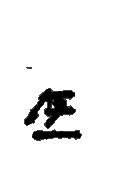

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00071.png


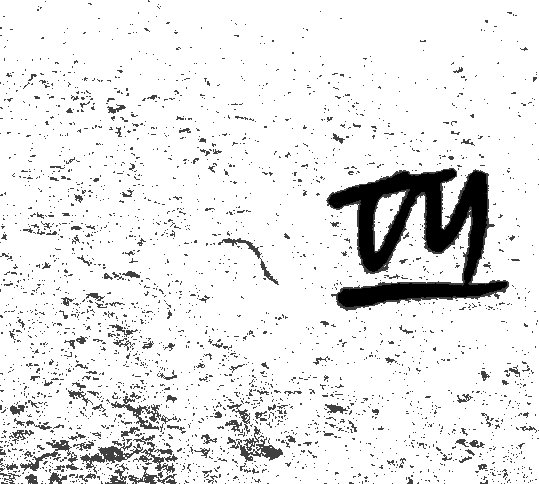

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00072.png


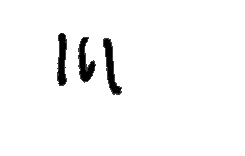

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00073.png


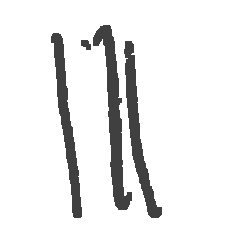

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00074.png


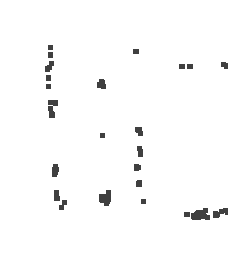

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00075.png


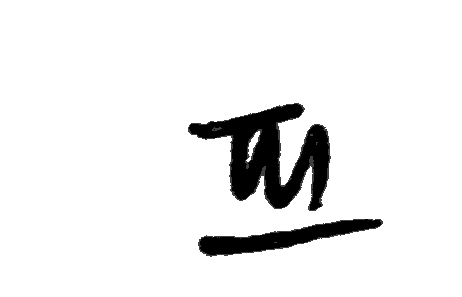

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00076.png


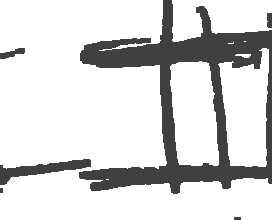

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00077.png


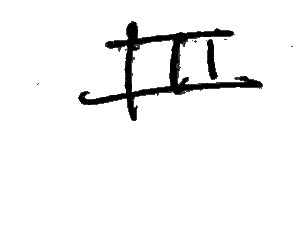

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00078.png


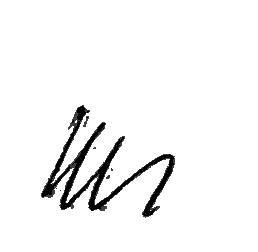

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00079.png


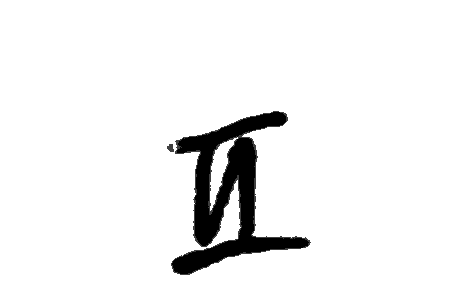

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00080.png


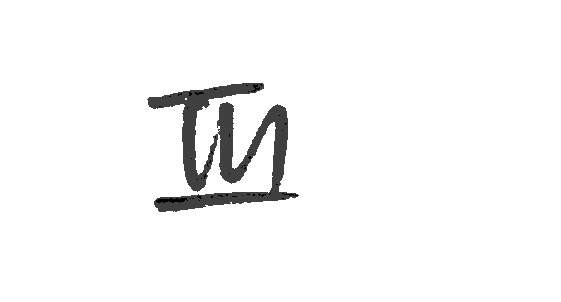

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00081.png


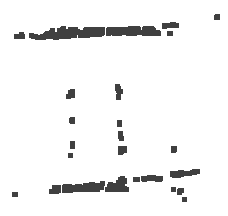

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00082.png


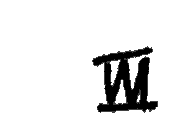

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00083.png


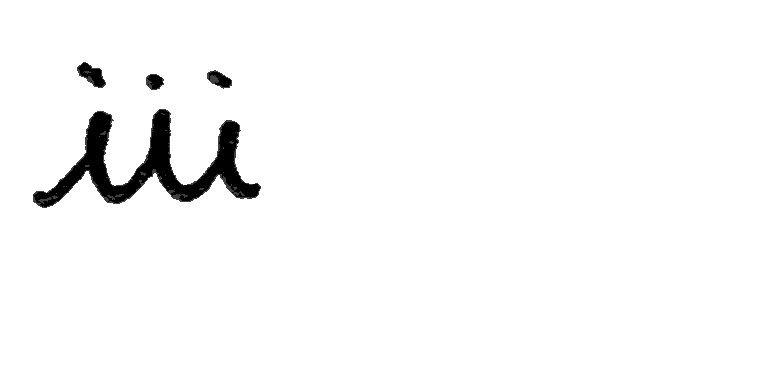

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00084.png


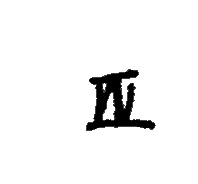

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00085.png


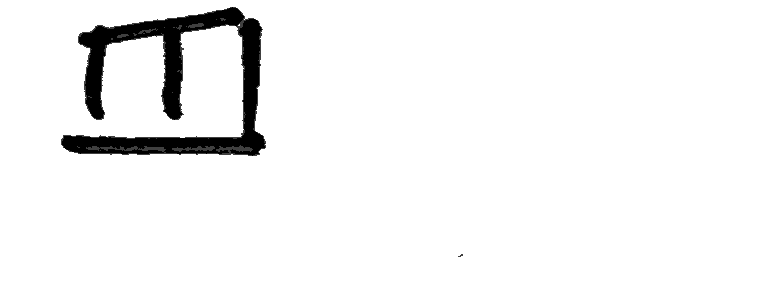

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00086.png


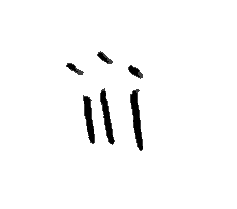

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00087.png


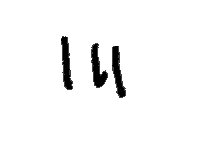

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00088.png


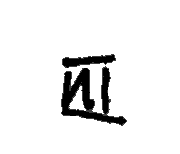

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00089.png


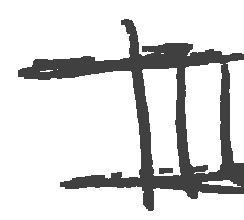

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00090.png


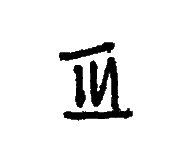

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00091.png


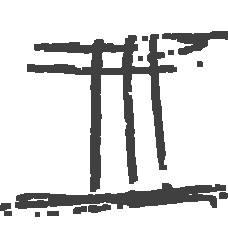

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00092.png


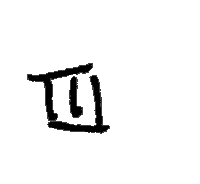

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00093.png


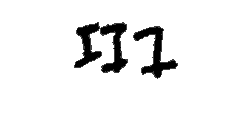

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00094.png


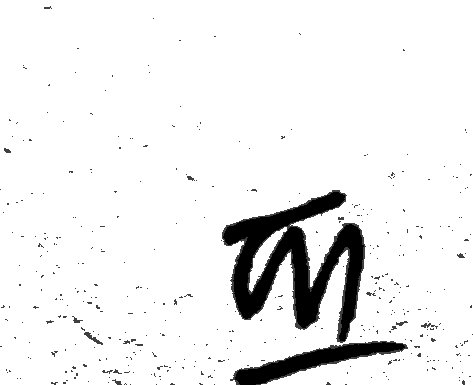

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00095.png


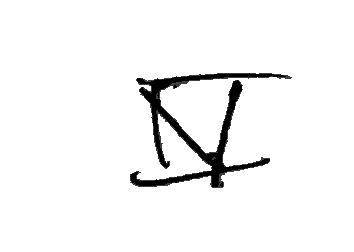

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00096.png


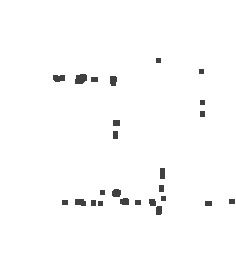

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00097.png


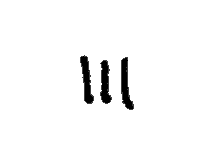

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00098.png


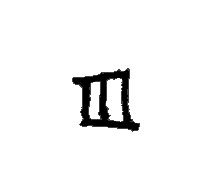

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00099.png


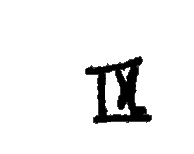

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00100.png


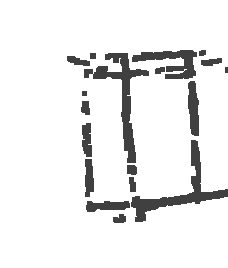

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00101.png


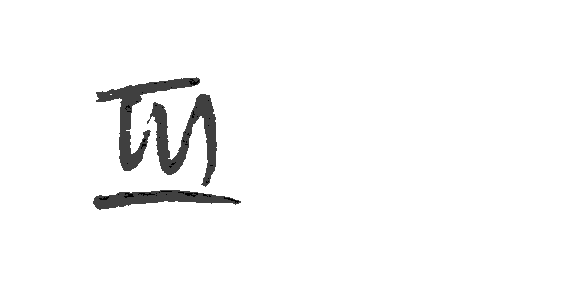

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00102.png


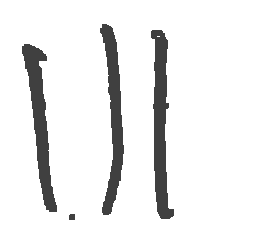

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00103.png


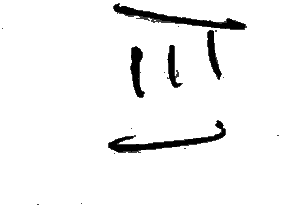

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00104.png


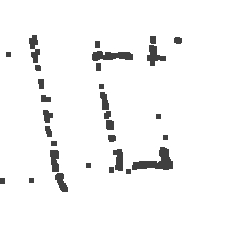

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00105.png


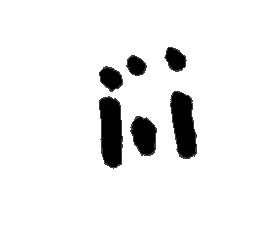

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00106.png


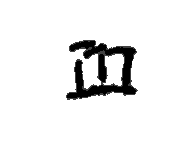

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00107.png


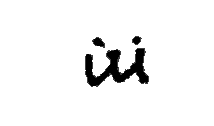

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00108.png


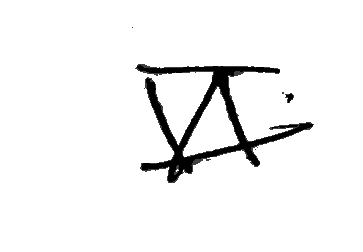

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00109.png


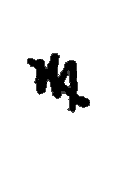

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00110.png


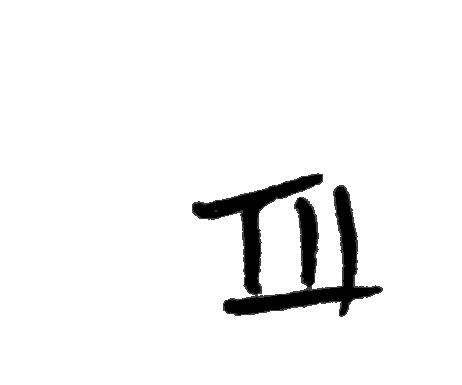

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00111.png


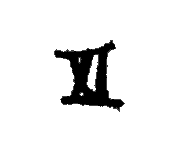

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00112.png


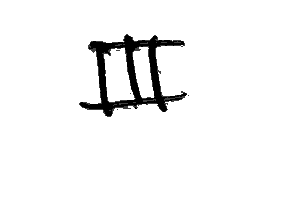

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00113.png


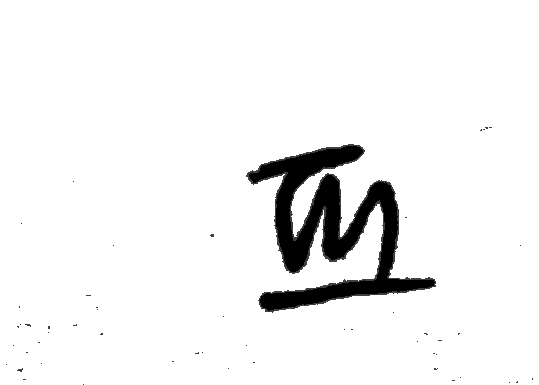

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00114.png


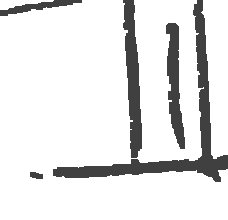

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00115.png


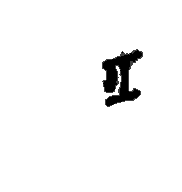

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00116.png


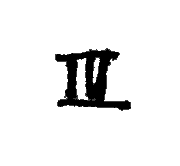

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00117.png


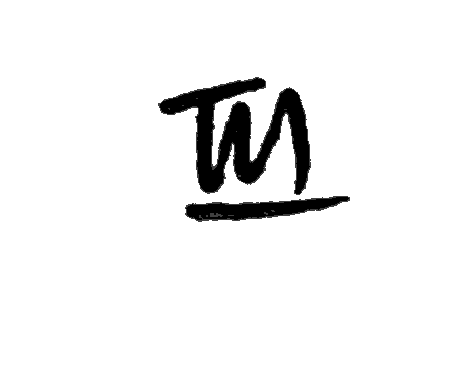

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00118.png


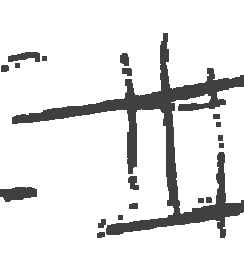

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00119.png


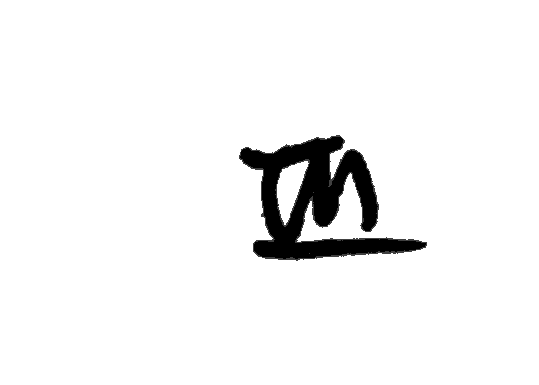

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00120.png


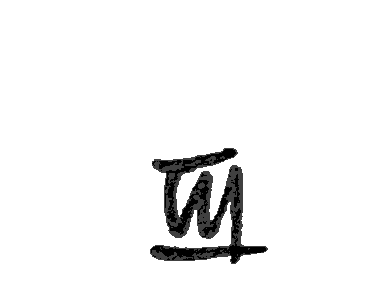

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00121.png


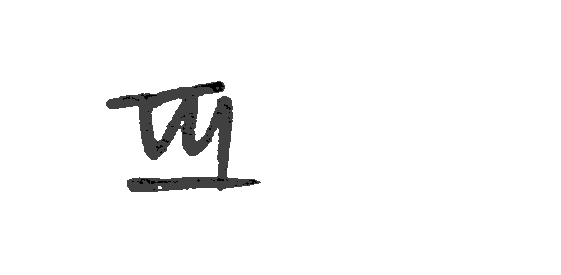

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00122.png


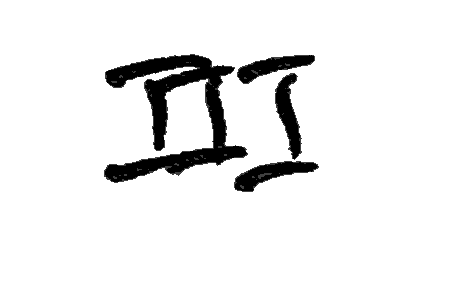

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00123.png


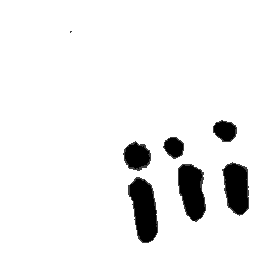

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00124.png


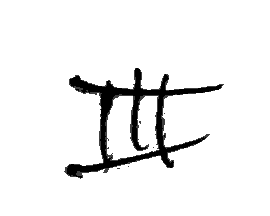

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00125.png


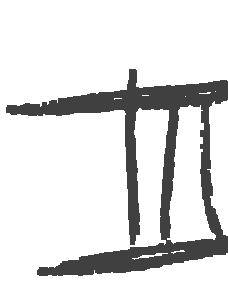

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00126.png


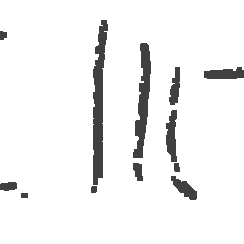

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00127.png


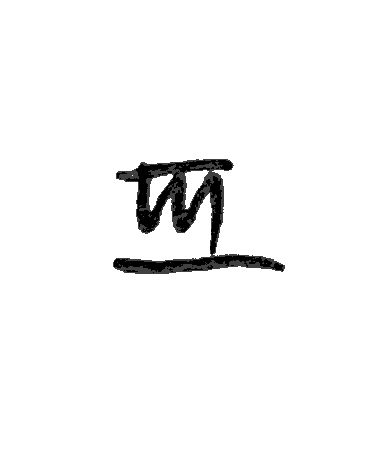

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00128.png


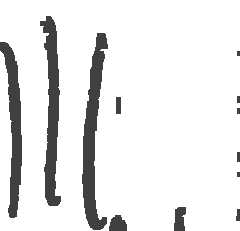

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00129.png


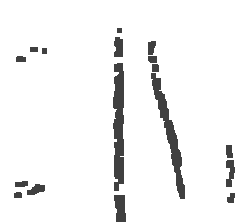

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00130.png


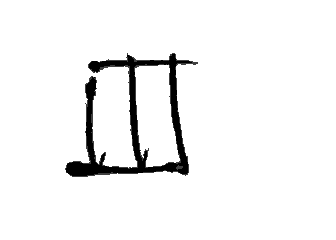

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00131.png


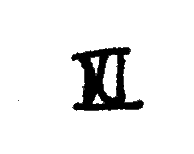

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00132.png


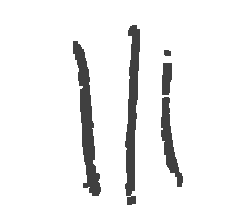

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00133.png


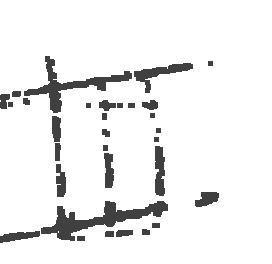

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00134.png


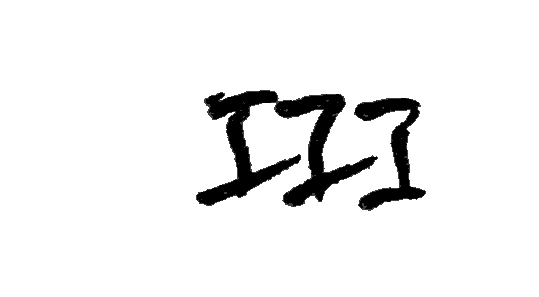

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00135.png


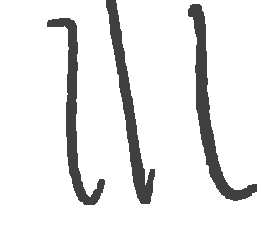

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00136.png


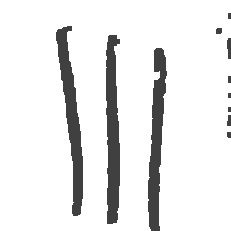

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00137.png


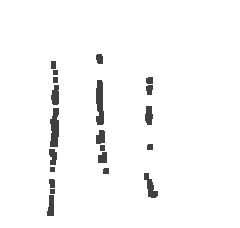

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00138.png


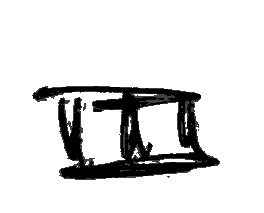

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00139.png


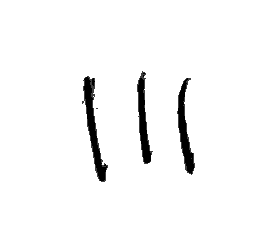

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00140.png


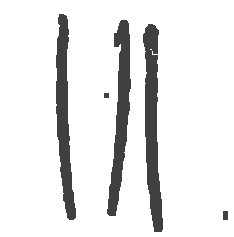

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00141.png


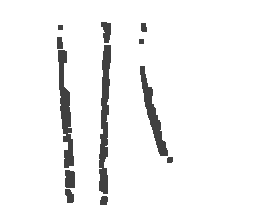

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00142.png


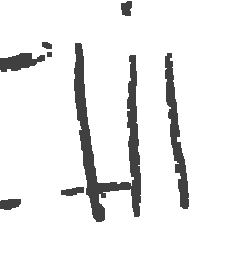

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00143.png


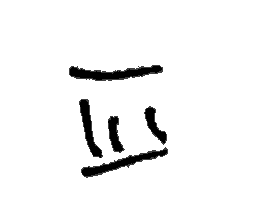

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00144.png


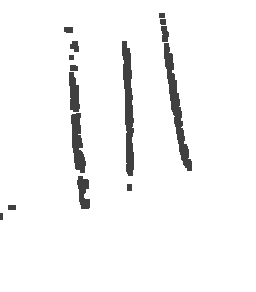

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00145.png


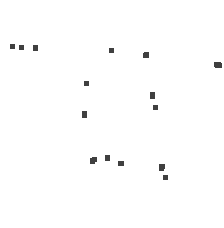

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00146.png


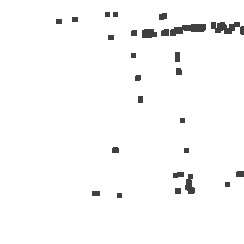

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00147.png


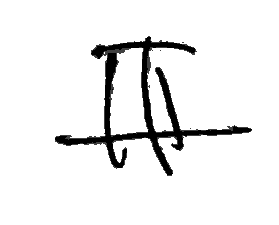

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00148.png


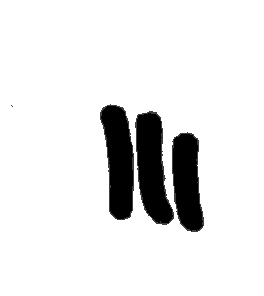

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00149.png


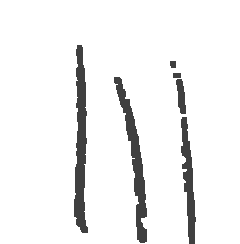

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00150.png


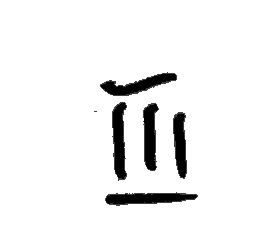

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00151.png


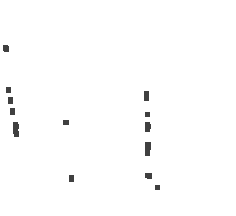

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00152.png


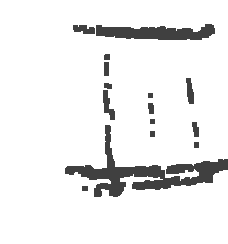

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00153.png


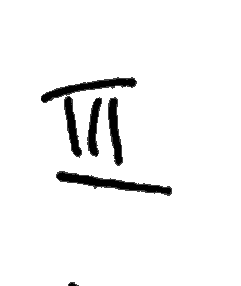

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00154.png


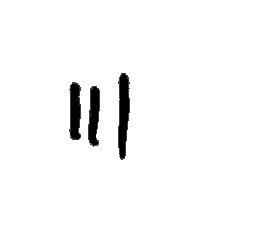

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00155.png


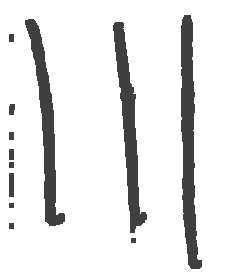

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00156.png


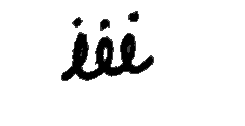

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00157.png


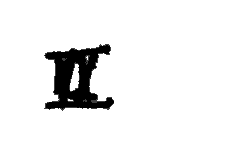

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00158.png


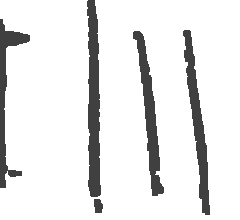

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00159.png


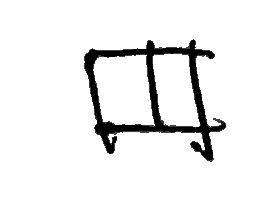

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00160.png


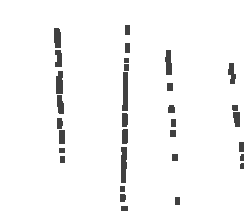

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00161.png


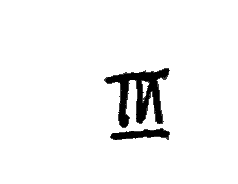

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00162.png


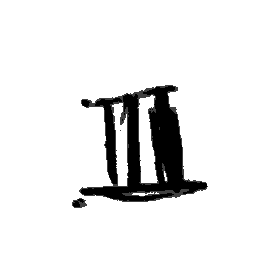

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00163.png


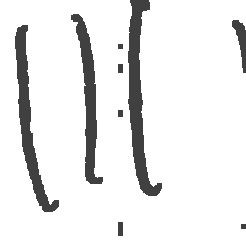

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00164.png


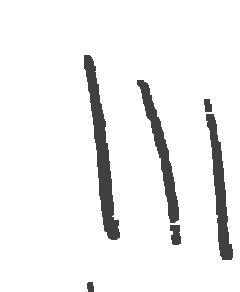

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00165.png


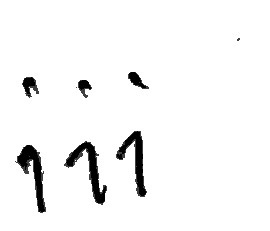

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00166.png


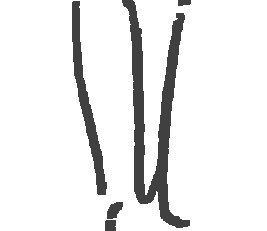

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00167.png


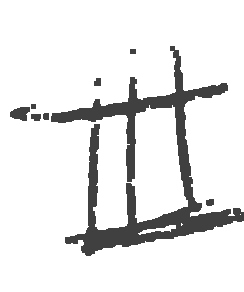

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00168.png


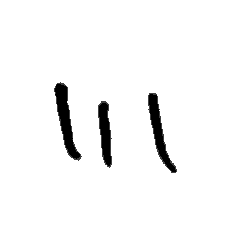

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00169.png


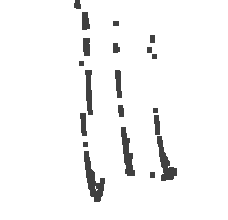

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00170.png


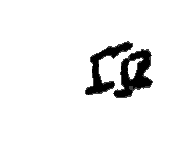

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00171.png


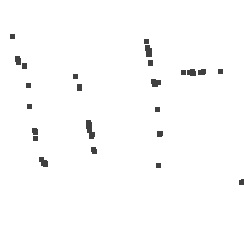

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00172.png


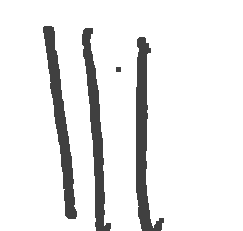

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00173.png


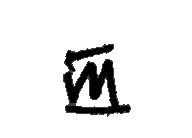

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00174.png


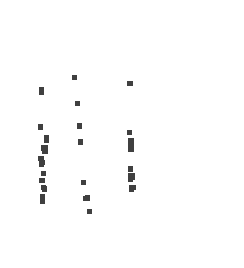

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00175.png


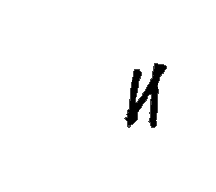

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00176.png


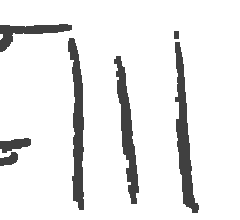

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00177.png


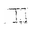

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00178.png


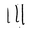

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00179.png


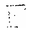

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00180.png


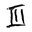

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00181.png


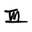

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00182.png


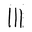

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00183.png


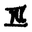

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00184.png


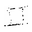

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00185.png


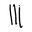

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00186.png


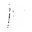

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00187.png


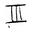

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00188.png


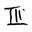

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00189.png


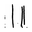

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00190.png


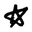

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00191.png


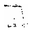

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00192.png


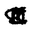

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00193.png


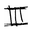

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00194.png


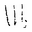

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00195.png


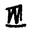

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00196.png


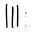

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00197.png


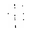

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00198.png


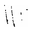

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00199.png


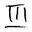

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00200.png


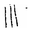

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00201.png


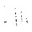

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00202.png


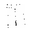

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00203.png


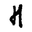

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00204.png


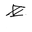

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00205.png


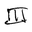

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00206.png


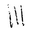

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00207.png


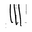

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00208.png


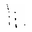

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00209.png


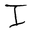

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00210.png


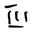

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00211.png


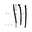

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00212.png


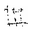

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00213.png


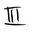

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00214.png


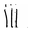

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00215.png


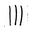

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00216.png


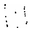

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00217.png


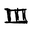

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00218.png


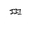

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00219.png


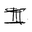

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00220.png


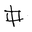

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00221.png


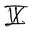

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00222.png


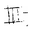

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00223.png


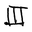

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00224.png


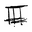

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00225.png


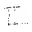

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00226.png


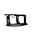

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00227.png


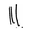

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00228.png


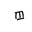

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00229.png


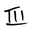

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00230.png


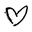

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00231.png


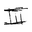

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00232.png


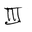

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00233.png


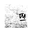

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00234.png


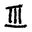

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00235.png


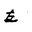

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00236.png


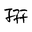

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00237.png


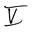

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00238.png


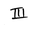

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00239.png


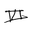

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00240.png


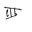

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00241.png


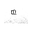

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00242.png


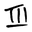

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00243.png


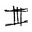

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00244.png


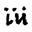

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00245.png


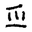

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00246.png


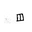

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00247.png


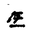

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00248.png


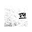

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00249.png


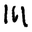

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00250.png


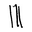

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00251.png


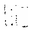

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00252.png


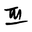

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00253.png


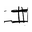

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00254.png


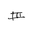

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00255.png


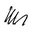

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00256.png


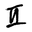

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00257.png


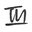

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00258.png


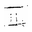

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00259.png


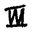

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00260.png


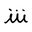

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00261.png


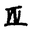

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00262.png


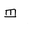

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00263.png


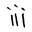

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00264.png


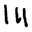

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00265.png


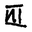

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00266.png


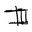

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00267.png


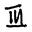

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00268.png


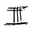

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00269.png


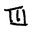

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00270.png


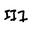

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00271.png


Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00272.png


Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00273.png


Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00274.png


Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00275.png


Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/train/iii/00276.png


... (6,814 outputs left out)

Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/val/x/b33b81e4-ce5d-11eb-b317-38f9d35ea60f.png


Biểu đồ: /content/deeplearningai-data-centric-competition/optimization_history/20261110T113110Z_447bd9ff/dataset/val/x/b33c36ac-ce5d-11eb-b317-38f9d35ea60f.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
from pathlib import Path
import json
from IPython.display import display, Markdown, Image
from google.colab import files

run = Path(
    "/content/deeplearningai-data-centric-competition/"
    "optimization_history/20261110T113110Z_447bd9ff"
)
assert run.is_dir(), f"Không thấy thư mục: {run}"

sections = [
    "# Kết quả thực nghiệm DAT301m",
    f"Run: `{run.name}`",
    (
        "Báo cáo khôi phục từ các file đã lưu của run. "
        "Đây không phải toàn bộ output gốc của notebook. "
        "Validation dùng để lựa chọn mô hình; label_book là "
        "tập tham khảo công khai gồm 52 ảnh, không phải hidden test."
    ),
]

# Đọc kết quả, cấu hình, lịch sử epoch và quyết định lựa chọn.
names = [
    "config.json",
    "v2_reference.json",
    "curves.json",
    "training_status.json",
    "v3_validation.json",
    "selection.json",
    "results.json",
]

for name in names:
    path = run / name
    if path.is_file():
        data = json.loads(path.read_text(encoding="utf-8"))
        sections.append(
            f"## {name}\n\n```json\n"
            + json.dumps(data, ensure_ascii=False, indent=2)
            + "\n```"
        )
    else:
        sections.append(f"## {name}\n\nKhông có file này trong run.")

report = "\n\n".join(sections)
display(Markdown(report))

# Hiển thị các biểu đồ còn lưu để bạn xem/chụp hoặc tải riêng.
for path in sorted(run.rglob("*.png")):
    print("Biểu đồ:", path)
    display(Image(filename=str(path)))

output = Path("/content/ket_qua_present.md")
output.write_text(report, encoding="utf-8")
files.download(str(output))